# 객체탐지 파일별 1 · 객체인식 Day01

**한 줄 요약** · 분류의 한계에서 탐지 출력 · 박스 · XML · IoU · NMS · 모델 계열 · 데이터 계약 · 채점까지 원본 순서대로

- **원본** · `7. 딥러닝/06_객체인식/강의자료/객체인식_Day01.html` (원본 파일은 그대로 둠)
- **종합 정리본** · `00_최소선/11_객체탐지` 객체탐지-1 (박스 · IoU · NMS · 채점) · 객체탐지-3 1장 (모델 계열)

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. 분류 모델의 한계와 탐지 모델 출력(boxes · scores · labels)을 설명한다
2. XML 정답을 읽고 xyxy · xywh · cxcywh, 크기 바꾸기 · 뒤집기의 박스를 계산한다
3. IoU를 손계산하고 신뢰도 거르기 → 클래스별 NMS를 한 단계씩 설명한다
4. R-CNN 계열 · SSD · YOLO가 후보를 두는 방식과 데이터 계약(target)을 말한다
5. 짝짓기로 TP · FP · FN을 정하고 사진 8장의 정밀도 · 재현율 · F1을 계산한다

## 어디에 쓰나

*실제 상황 → 이 권에서 배우는 것*

- **탐지 모델 결과를 처음 읽을 때** · boxes · scores · labels (2장)
- **라벨 파일 형식이 헷갈릴 때** · XML · 박스 표기 (3장)
- **결과에 겹친 박스가 많을 때** · 신뢰도 · NMS (5장)
- **내 데이터로 학습을 준비할 때** · 데이터 계약 · target (7장)

## 학습 지도

<img src="images/pfo1_map.png" alt="Day01 학습 지도" width="763">

**예상 학습 시간** · 개념 2시간 30분 + 실습 1시간 (CPU로 실행 · 몇 분)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td>0</td><td>준비</td><td>실행 환경 · 원본 구성</td></tr>
<tr><td>1</td><td>분류 vs 탐지</td><td>분류 모델로는 왜 위치를 못 찾는가?</td></tr>
<tr><td>2</td><td>탐지 모델 처음 돌려 보기</td><td>탐지 모델은 무엇을 몇 줄 내놓는가?</td></tr>
<tr><td>3</td><td>박스 숫자 4개 · XML</td><td>박스 네 숫자의 뜻과 정답 XML은?</td></tr>
<tr><td>4</td><td>IoU</td><td>예측 박스가 정답과 얼마나 맞았는지 어떻게 재는가?</td></tr>
<tr><td>5</td><td>신뢰도 · NMS · 한 줄로</td><td>후보가 너무 많으면 어떻게 정리하는가?</td></tr>
<tr><td>6</td><td>후보는 어디서 오나</td><td>R-CNN 계열과 SSD는 후보를 어떻게 만드는가?</td></tr>
<tr><td>7</td><td>Oxford 탐지 데이터 계약</td><td>모델에 먹일 한 샘플은 어떤 모양인가?</td></tr>
<tr><td>8</td><td>YOLO와 비교</td><td>YOLO는 SSD와 무엇이 같고 다른가?</td></tr>
<tr><td>9</td><td>종합 실습</td><td>COCO SSD의 예측을 머리 정답으로 채점하면 정밀도 · 재현율은?</td></tr>
<tr><td>—</td><td>마무리 · 부록</td><td>오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td></tr>
</tbody></table>

---
## 0. 준비

원본은 Mac(MPS 없이 CPU)과 데이터 폴더 기준 → 이 노트북은 kagglehub 캐시 · Windows 글꼴 · CPU로 실행. **셀은 위에서부터 차례로**.

*항목 → 설정*

- **데이터** · Oxford-IIIT Pet (kagglehub 캐시 · 원본의 data/oxford_pet과 같은 파일)
- **모델** · ResNet18 · SSD300 · Faster R-CNN(구조만) · YOLO11n (원본은 YOLO26n)
- **장치 · seed** · CPU (원본과 같음) · `torch.manual_seed(0)`
- **weights** · 노트북 옆 `weights/yolo11n.pt` (GitHub에 안 올림)
- **원본 셀 수** · 201개 (코드 100 · 설명 101, 빈 설명 셀은 원본 그림 자리)

**실행 흐름**

1. 도구 불러오기 · OpenMP · seed · 한글 글꼴
2. kagglehub 캐시에서 데이터 경로 · 파일 수 확인
3. 색 약속 · read_voc · load_image · 박스 하나 그리기

In [1]:
# 라이브러리 · 데이터 경로 (원본 셀 1 · Mac 경로 → kagglehub 캐시)
# 왜 · 원본의 Mac 전용 경로 대신 어느 PC에서나 같은 데이터 경로를 쓰기 위해
import os                           # 환경 변수
import time                         # 시간 재기 (1-3 · 6-1)
import xml.etree.ElementTree as ET  # XML 정답 읽기
from pathlib import Path            # 폴더 · 파일 경로

# 왜 · 데이터 받기 · 그림 · 모델 도구를 한곳에서 확인하기 위해
import kagglehub                 # Oxford-IIIT Pet (있으면 캐시 경로만)
import matplotlib.pyplot as plt  # 사진 · 그래프
import numpy as np               # 배열 (3-2)
import torch                     # 텐서 · 모델 실행
import torchvision               # 탐지 모델 · 박스 함수
from matplotlib import patches   # 박스 그리기
from PIL import Image            # 사진 열기

# 왜 · torch와 numpy를 한 커널에서 쓸 때 커널이 멈추는 충돌을 막기 위해
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # numpy · torch OpenMP 충돌 방지
torch.manual_seed(0)                                   # 난수 고정 (7-1의 가짜 입력)
plt.rcParams["font.family"] = "Malgun Gothic"          # 그림 속 한글 (원본은 Mac 글꼴)
plt.rcParams["axes.unicode_minus"] = False             # 음수 기호 깨짐 방지

# 왜 · 데이터를 매번 내려받지 않고 캐시 경로를 다시 쓰기 위해
DATA = Path(kagglehub.dataset_download(     # 원본의 data/oxford_pet과 같은 데이터
    "zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1"))
IMAGES = DATA / "images" / "images"         # 사진 폴더
ANN = DATA / "annotations" / "annotations"  # 목록 txt · README · xmls
XMLS = ANN / "xmls"                         # 머리 박스 XML
WEIGHTS = Path("weights")                   # 노트북 옆 yolo11n.pt (8장 · GitHub에 안 올림)
print("torch", torch.__version__.split("+")[0], "· torchvision",  # 버전 기록
      torchvision.__version__.split("+")[0], "· 실행 장치 cpu (원본과 같음)")
# 받은 수
print("사진", len(list(IMAGES.glob("*.jpg"))), "장 · XML", len(list(XMLS.glob("*.xml"))), "개")


# 도우미 (원본 셀 2 · 3): 정답 = 초록 실선 · 예측 = 파랑 실선 · 후보 = 파랑 점선
# 왜 · 모든 그림에서 정답 · 예측 · 후보를 같은 색 약속으로 구분하기 위해
GT_COLOR, PRED_COLOR = "#16a34a", "#2563eb"  # 흰 배경에서 보이는 색


# 왜 · XML 정답 읽기를 한 함수로 묶어 모든 장에서 다시 쓰기 위해
def read_voc(xml_path):                            # XML 한 개 → (boxes, names)
    """boxes = [[xmin, ymin, xmax, ymax], ...]"""  # 함수 설명
    root = ET.parse(xml_path).getroot()            # XML 열기
    boxes, names = [], []                          # 박스 · 이름
    for obj in root.iter("object"):                # 물체마다
        bb = obj.find("bndbox")                    # 박스 태그
        # 글자 → 실수
        boxes.append([float(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")])
        names.append(obj.findtext("name"))         # cat 또는 dog
    return boxes, names                            # 같은 순서


# 왜 · 흑백 사진도 3채널로 맞춰 모델 입력 형식을 통일하기 위해
def load_image(stem):                                         # 파일 이름(확장자 없이) → RGB 사진
    return Image.open(IMAGES / f"{stem}.jpg").convert("RGB")  # 흑백도 3채널로


# 왜 · 박스 하나 그리는 코드를 여러 그림 함수에서 같이 쓰기 위해
def _box(ax, b, color, ls="-", lw=3, text=None):                            # 박스 하나
    x1, y1, x2, y2 = [float(v) for v in b]                                  # 텐서여도 숫자로
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,  # (왼쪽 위, 너비, 높이)
                                   ec=color, ls=ls, lw=lw))
    if text:                                                                # 이름표가 있으면
        ax.text(x1 + 3, y1 + 3, text, color="white", fontsize=9, va="top",  # 왼쪽 위 글자
                bbox=dict(fc=color, ec="none", pad=2))

torch 2.11.0 · torchvision 0.26.0 · 실행 장치 cpu (원본과 같음)
사진 7390 장 · XML 3686 개


**실행 흐름**

1. list · 텐서를 같은 목록으로
2. 후보(점선) → 예측(실선) → 정답(초록) 순서로 그리기

In [2]:
# 왜 · list와 텐서를 같은 형식으로 바꿔 그림 함수가 둘 다 받게 하기 위해
def _rows(boxes):      # list · 텐서 모두 → [[x1, y1, x2, y2], ...]
    if boxes is None:  # 없으면
        return []      # 빈 목록
    return boxes.tolist() if hasattr(boxes, "tolist") else list(boxes)  # 텐서면 tolist


# 왜 · 사진 위에 정답 · 예측 · 후보를 한 번에 그리기 위해
def draw(img, gt=None, pred=None, cand=None, labels=None, title=None, ax=None):  # 사진 + 박스
    if ax is None:                                                   # 칸을 안 주면
        _, ax = plt.subplots(figsize=(6, 4.5))                       # 새 그림
    ax.imshow(img)                                                   # 사진
    ax.axis("off")                                                   # 눈금 숨김
    for b in _rows(cand):                                            # 후보 = 점선
        _box(ax, b, PRED_COLOR, ls="--", lw=1)                       # 가늘게
    for i, b in enumerate(_rows(pred)):                              # 예측 = 실선
        _box(ax, b, PRED_COLOR, text=labels[i] if labels else None)  # 이름표
    for b in _rows(gt):                                              # 정답 = 초록
        _box(ax, b, GT_COLOR, lw=4)                                  # 굵게
    if title:                                                        # 제목이 있으면
        ax.set_title(title, fontsize=10)                             # 제목
    return ax                                                        # 바깥에서 더 그릴 수 있게

### 원본 구성

- **D1-0 미리 보기** · 결과물 = 사진마다 종류 + 박스 + 확신 · 미션 평가 기준 100점 · 오늘의 질문 순서
- **D1-1 · D1-2** · 분류 모델로 위치를 찾을 수 있나 → 탐지 모델 처음 돌려 보기
- **D1-3 · D1-4** · 박스 숫자 4개 · Oxford XML → IoU
- **D1-5 · D1-6** · 신뢰도 · NMS → 사진에서 최종 박스까지 한 줄로
- **D1-7 · D1-8** · 후보는 어디서 오나: R-CNN → Fast → Faster · SSD
- **D1-9 · D1-10** · Oxford 탐지 데이터 계약 · YOLO와 비교
- **D1-11** · 정답과 짝짓기 → 채점 (사진 8장)

**원본 힌트**

- 미션 평가 기준: 기획 20 · 전처리 · 탐색 20 · 모델 20 · 훈련 · 평가 30 · 코드 · 문서화 10
- 탐지 = 후보 만들기 → 정리하기(점수 · NMS) → 비교하기(IoU)

---
## 1. 분류 vs 탐지

> **이 장의 흐름**
>
> - 미션 사진과 정답 박스부터 봄
> - 분류 모델에 개 + 사람 사진 → 위치를 답할 칸이 없음

<img src="images/od1_cls_vs_det.png" alt="분류는 이름 하나, 탐지는 박스마다 세 가지" width="763">

**파이프라인 위치** · ④ 모델 — 분류 출력 vs 탐지 출력

### 1-1. `A` 미리 보기 · 사진 + XML 정답 박스 · `read_voc()` · `draw()` <sub>원본 D1-0 · 셀 4 ~ 11</sub>

> 🎯 **사진 한 장에서 '고양이 얼굴이 어디 있나'를 컴퓨터에게 어떻게 시키는가?**

💡 **쉽게 말하면**

- 정답은 **사진 + 얼굴을 감싼 네모(박스)**.
- 얼굴이 사진에서 차지하는 비율은 사진마다 크게 다름.

**실행 흐름**

1. 미션 사진 3장 + 정답 박스
2. 사진 8장 더 · 얼굴 박스 비율
3. 비율 출력

**먼저 예측** · 얼굴 박스는 사진 넓이의 몇 % 정도일까? — 답은 코드 실행 결과 아래에

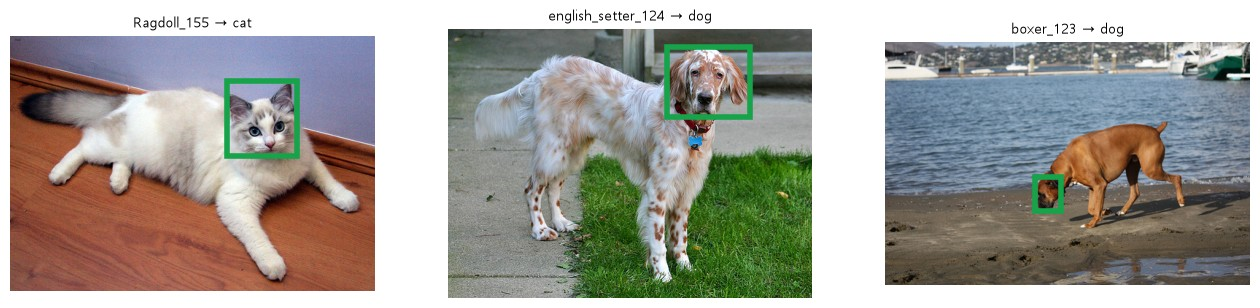

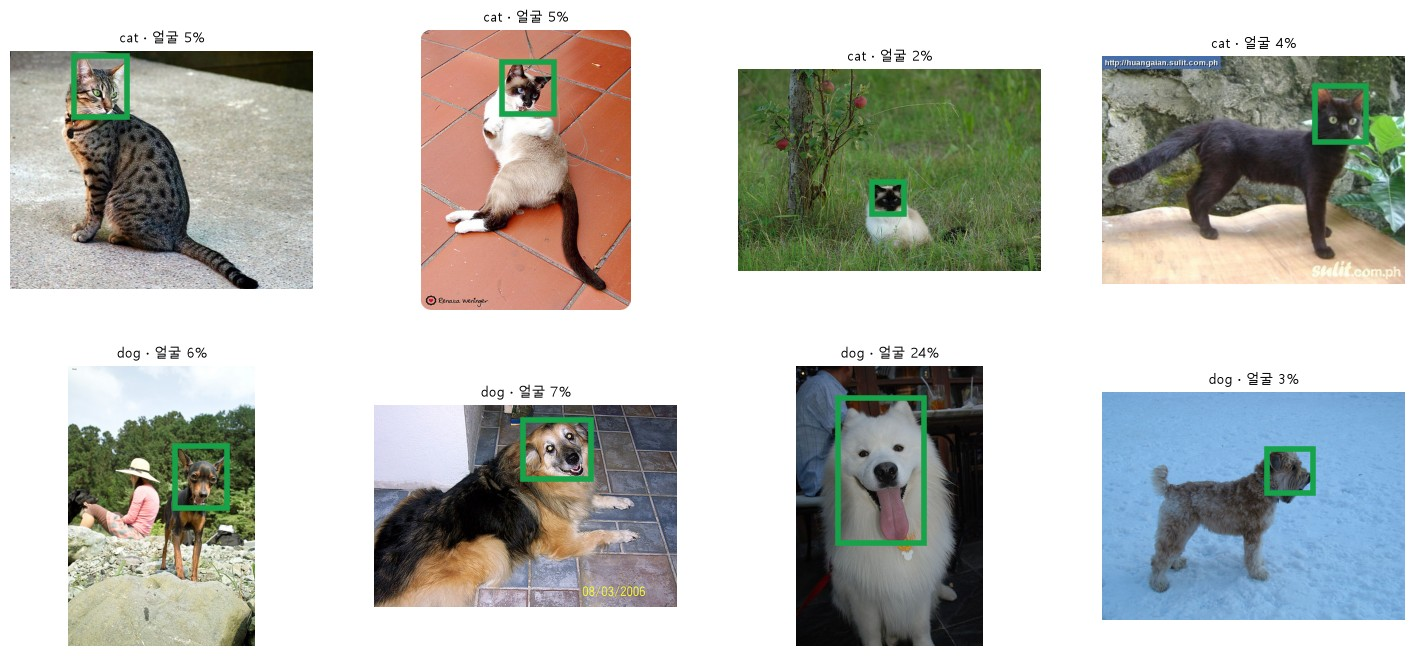

얼굴 비율: ['5%', '5%', '2%', '4%', '6%', '7%', '24%', '3%']


In [3]:
# 왜 · 고양이 · 개 사진에서 정답 박스가 어디를 가리키는지 먼저 보기 위해
examples = ["Ragdoll_155", "english_setter_124", "boxer_123"]              # 미션 예시 사진 3장
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))                          # 3칸
for stem, ax in zip(examples, axes):                                       # 사진마다
    boxes, names = read_voc(XMLS / f"{stem}.xml")                          # XML 읽기 (자세히는 3장)
    draw(load_image(stem), gt=boxes, title=f"{stem} → {names[0]}", ax=ax)  # 정답 박스
plt.show()                                                                 # 그림 출력

# 왜 · 여러 사진에서도 정답이 늘 머리라는 것을 확인하기 위해
more = ["Egyptian_Mau_116", "Siamese_206", "Birman_137", "Bombay_148",  # 8장 더
        "miniature_pinscher_107", "keeshond_134", "samoyed_187", "wheaten_terrier_114"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))                         # 2줄 × 4칸
ratios = []  # 사진 넓이 중 얼굴 박스 비율
for stem, ax in zip(more, axes.flat):                                   # 사진마다
    boxes, names = read_voc(XMLS / f"{stem}.xml")                       # 정답
    img = load_image(stem)                                              # 사진
    x1, y1, x2, y2 = boxes[0]                                           # 첫 박스
    ratio = (x2 - x1) * (y2 - y1) / (img.size[0] * img.size[1])         # 얼굴 박스 ÷ 사진
    ratios.append(ratio)                                                # 기록
    draw(img, gt=boxes, title=f"{names[0]} · 얼굴 {ratio:.0%}", ax=ax)  # 비율을 제목에
plt.show()                                                              # 그림 출력
print("얼굴 비율:", [f"{r:.0%}" for r in ratios])                       # 사진마다 다름

**결과** · 예측 정답은 대부분 `2% ~ 7%` — 작은 물체, 한 장만 24%

- `얼굴 비율: ['5%', '5%', '2%', '4%', '6%', '7%', '24%', '3%']` — 사진마다 얼굴 크기가 다름 (samoyed만 크게)
- 결과물 = 사진마다 종류 + 박스 + 확신 · 종류 2개(고양이 얼굴 · 개 얼굴) · 모델 SSD

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>분류 정답</td><td>사진 한 장 = 이름 하나</td><td>무엇인지만</td></tr>
<tr><td>탐지 정답</td><td>사진 + 박스 N개 + 이름</td><td>무엇 · 어디에</td></tr>
<tr><td>박스 비율</td><td>얼굴 넓이 ÷ 사진 넓이</td><td>작은 물체인지 판단</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 정답 박스는 몸 전체가 아니라 **머리(얼굴)** → 3장에서 XML로 확인

> ✅ **한 줄 정리** · 탐지의 정답은 사진마다 물체를 감싼 박스와 이름이며, 얼굴 박스는 대부분 사진의 몇 %뿐이다.

**딥러닝 코드에서는**

- 미션 = 사진마다 고양이 · 개 얼굴의 종류 + 박스 + 확신을 내는 SSD

### 1-2. `A` 분류 모델로 위치를 찾을 수 있을까 · `resnet18()` · `topk()` <sub>원본 D1-1 · 셀 12 ~ 16</sub>

> 🎯 **개 + 사람 사진을 분류 모델에 넣으면 무엇을 알려 주고, 무엇을 못 알려 주는가?**

💡 **쉽게 말하면**

- 분류 모델은 **사진 전체에 이름표 하나를 붙이는 사람**.
- 무엇이 있는지는 말해도 어디에 · 몇 개는 답할 칸이 없음.

**실행 흐름**

1. 개 + 사람 사진
2. ImageNet ResNet18 → 1000칸 확률
3. 상위 5개
4. 'person' 이름이 있나

**먼저 예측** · 1000칸 확률의 합과, 사람이 답에 나올지는? — 답은 코드 실행 결과 아래에

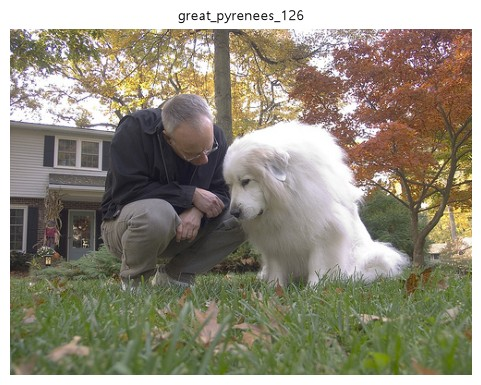

출력 모양: (1000,) · 확률 합: 1.0
Great Pyrenees   0.957
Samoyed          0.025
kuvasz           0.013
Pekinese         0.001
Pomeranian       0.001
이름 수: 1000
'person'이 목록에 있나? False


In [4]:
from torchvision.models import ResNet18_Weights, resnet18  # ImageNet 분류 모델

# 왜 · 물체가 둘 이상인 사진으로 분류 모델의 한계를 보기 위해
pair = load_image("great_pyrenees_126")  # 개 + 사람 사진
draw(pair, title="great_pyrenees_126")   # 사진 보기
plt.show()                               # 그림 출력

# 왜 · 분류 모델은 '무엇'만 알려 주고 위치는 주지 않는다는 것을 확인하기 위해
cls_w = ResNet18_Weights.IMAGENET1K_V1                   # ImageNet 1000개 이름으로 학습된 가중치
classifier = resnet18(weights=cls_w).eval()              # 평가 모드
x = cls_w.transforms()(pair).unsqueeze(0)                # 사진 → (1, 3, 224, 224)
with torch.no_grad():                                    # 예측만
    prob = classifier(x).softmax(dim=1)[0]               # 1000칸 확률
# 사진 한 장 = 1000칸
print("출력 모양:", tuple(prob.shape), "· 확률 합:", round(prob.sum().item(), 3))
top = prob.topk(5)                                       # 상위 5개
for p, i in zip(top.values, top.indices):                # 확률 · 번호
    print(f"{cls_w.meta['categories'][i]:16s} {p:.3f}")  # 이름 · 확률

# 왜 · 분류 모델이 고르는 이름이 몇 개인지 확인하기 위해
names_1000 = cls_w.meta["categories"]                     # 1000개 이름
print("이름 수:", len(names_1000))                        # 1000
print("'person'이 목록에 있나?", "person" in names_1000)  # 사람은 답할 수 없음

**결과** · 예측 정답은 합 `1.0` · 사람은 나올 수 없음 (`False`)

- `출력 모양: (1000,) · 확률 합: 1.0` — 사진 한 장 → 1000칸 확률 하나
- `Great Pyrenees   0.957` — 개 품종 하나에 확률 대부분
- `'person'이 목록에 있나? False` — 학습한 이름표에 없는 물체는 답할 수 없음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>분류 (ResNet18)</td><td>사진 → 이름 하나 + 확률</td><td>무엇인지만 필요할 때</td></tr>
<tr><td>탐지 (SSD)</td><td>사진 → 박스 N개 + 이름 + 확신</td><td>무엇 · 어디에 · 몇 개</td></tr>
<tr><td>ImageNet 1000</td><td>물건 · 동물 이름 (사람 없음)</td><td>분류 사전학습</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 확률은 '사진 전체가 이 이름일 확률' → 물체 개수 · 위치가 아님

> ✅ **한 줄 정리** · 분류는 사진 한 장에 이름 하나를 답하므로, 여러 물체의 위치까지 알려면 탐지 모델이 필요하다.

**딥러닝 코드에서는**

- 분류: `logits.argmax(dim=1)` · 탐지: `model(images)[i]["boxes"]`

### 1-3. `B` 창문 옮겨 대 보기 · `crop()` <sub>원본 D1-1 · 셀 17 ~ 21</sub>

> 🎯 **사진을 창문으로 잘라 분류하면 위치를 찾을 수 있는가?**

💡 **쉽게 말하면**

- 창문마다 분류하면 **어디에 무엇이**는 알 수 있음.
- 하지만 크기 · 모양 · 위치를 바꿔 가며 수천 번 해야 함.

**실행 흐름**

1. 224×224 창문 3개 분류
2. 창문 크기 3 × 모양 3 · 16픽셀씩 옮긴 창문 수
3. 분류 한 번 시간 × 창문 수

**먼저 예측** · 500×375 사진에 창문은 몇 개일까? — 답은 코드 실행 결과 아래에

['mobile home 0.05', 'Great Pyrenees 0.98', 'Angora 0.62']


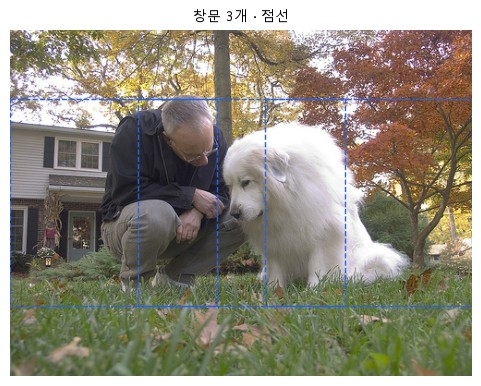

사진 크기: (500, 375) → 창문 수: 2975


분류 한 번 7407ms × 창문 2975개 ≈ 22035초 (컴퓨터마다 다름)


In [5]:
# 왜 · 창문 세 곳을 잘라 분류하면 위치를 짐작할 수 있는지 보기 위해
windows = [[0, 75, 224, 299], [138, 75, 362, 299], [276, 75, 500, 299]]          # 224×224 창문 3개
answers = []                                                                     # 창문마다 답
for box in windows:                                                              # 창문마다
    crop = pair.crop(box)                                                        # 창문 안만 잘라서
    with torch.no_grad():                                                        # 예측만
        p = classifier(cls_w.transforms()(crop).unsqueeze(0)).softmax(dim=1)[0]  # 분류
    answers.append(f"{cls_w.meta['categories'][p.argmax()]} {p.max():.2f}")      # 1등 이름 · 확률
print(answers)                                                                   # 창문 3개의 답
draw(pair, cand=windows, title="창문 3개 · 점선")                                # 창문 그림
plt.show()                                                                       # 그림 출력

# 왜 · 창문 크기 · 간격에 따라 분류를 몇 번 해야 하는지 세기 위해
W_img, H_img = pair.size                                            # 사진 크기
count = 0                                                           # 창문 수
for size in (64, 128, 256):                                         # 창문 크기 3가지
    for ratio in (0.5, 1, 2):                                       # 모양 3가지 (세로 ÷ 가로)
        w, h = int(size / ratio ** 0.5), int(size * ratio ** 0.5)   # 넓이는 같고 모양만 다름
        count += ((W_img - w) // 16 + 1) * ((H_img - h) // 16 + 1)  # 16픽셀씩 옮김
print("사진 크기:", pair.size, "→ 창문 수:", count)                 # 2975개

with torch.no_grad():                                                          # 시간 재기
    classifier(x)                                                              # 한 번 데워 두기
    t = time.perf_counter()                                                    # 시작
    classifier(x)                                                              # 분류 한 번
one = time.perf_counter() - t                                                  # 한 번 시간
print(f"분류 한 번 {one * 1000:.0f}ms × 창문 {count}개 ≈ {one * count:.0f}초"  # 사진 한 장
      " (컴퓨터마다 다름)")

**결과** · 예측 정답은 `2975`개 — 사진 한 장에 분류를 수천 번

- `['mobile home 0.05', 'Great Pyrenees 0.98', 'Angora 0.62']` — 가운데 창문만 개를 맞힘
- `사진 크기: (500, 375) → 창문 수: 2975` — 크기 3 × 모양 3 × 위치마다
- 시간 줄 = 분류 한 번 × 2975 (ms 값은 컴퓨터마다 다름)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>창문마다 분류</td><td>느림 · 수천 번</td><td>원리 이해용</td></tr>
<tr><td>탐지 모델</td><td>한 번에 박스 여러 개</td><td>실제 사용 (기본)</td></tr>
<tr><td>R-CNN (6장)</td><td>후보 수천 개마다 CNN</td><td>탐지의 시작</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 창문 크기 · 모양을 안 맞추면 물체를 잘라 먹어 틀린 답 (오른쪽 창문의 Angora)

> ✅ **한 줄 정리** · 창문을 옮겨 가며 분류하면 위치를 찾을 수는 있지만 사진 한 장에 수천 번 계산해야 한다.

**딥러닝 코드에서는**

- 이 비효율을 줄인 것이 Fast · Faster R-CNN과 SSD · YOLO (6 · 8장)

---
## 2. 탐지 모델 처음 돌려 보기

> **이 장의 흐름**
>
> - 1장의 한계 → COCO SSD
> - 출력 세 가지 · 200줄 · 점수 거르기

<img src="images/pfo1_output.png" alt="200줄 출력 → 점수 0.5 초과만 남김" width="763">

**파이프라인 위치** · ④ 모델 — boxes · scores · labels

### 2-1. `A` 탐지 모델 불러오기 · 입력 모양 · `ssd300_vgg16()` · `det_w.transforms()` <sub>원본 D1-2 · 셀 22 ~ 25</sub>

> 🎯 **COCO로 학습된 SSD는 몇 칸의 이름을 알고, 사진은 어떤 모양으로 넣는가?**

💡 **쉽게 말하면**

- SSD는 **COCO 80종 + 빈 번호 + 배경 = 91칸**을 아는 모델.
- 사진은 0~1 텐서로 바꾸고, 크기는 그대로 넣음 (안에서 300×300으로 맞춤).

**실행 흐름**

1. COCO 가중치로 SSD 불러오기
2. 이름 수 · cat · dog 있나
3. 사진 → 텐서 · 모양 · 값 범위

**먼저 예측** · COCO 이름 0번은? — 답은 코드 실행 결과 아래에

In [6]:
from torchvision.models.detection import SSD300_VGG16_Weights, ssd300_vgg16  # 탐지 모델

# 왜 · 완성된 탐지 모델과 그 입력 변환을 함께 불러오기 위해
det_w = SSD300_VGG16_Weights.COCO_V1                      # COCO 데이터로 학습된 가중치
detector = ssd300_vgg16(weights=det_w).eval()             # 처음 한 번은 내려받기 (약 136MB)
COCO = det_w.meta["categories"]                           # 번호 → 이름
print("COCO 이름 수:", len(COCO), "· 앞 3개:", COCO[:3])  # 0번 = 배경
print("'cat' 있나?", "cat" in COCO, "· 'dog' 있나?", "dog" in COCO)  # 둘 다 있음

# 왜 · 탐지 모델 입력 모양이 어떻게 바뀌는지 확인하기 위해
cat_img = load_image("Abyssinian_173")                  # 고양이 한 마리 사진
x = det_w.transforms()(cat_img)                         # PIL 사진 → 0~1 텐서 (크기는 그대로)
print("사진 크기 (가로, 세로):", cat_img.size)          # PIL은 (가로, 세로)
print("텐서 모양 (채널, 세로, 가로):", tuple(x.shape))  # 텐서는 (C, H, W)
print("값 범위:", round(x.min().item(), 2), "~", round(x.max().item(), 2))  # 0 ~ 1

COCO 이름 수: 91 · 앞 3개: ['__background__', 'person', 'bicycle']
'cat' 있나? True · 'dog' 있나? True
사진 크기 (가로, 세로): (400, 267)
텐서 모양 (채널, 세로, 가로): (3, 267, 400)
값 범위: 0.0 ~ 1.0


**결과** · 예측 정답은 `__background__` — 0번은 배경

- `COCO 이름 수: 91 · 앞 3개: ['__background__', 'person', 'bicycle']` — 0번 = 배경 자리
- `'cat' 있나? True · 'dog' 있나? True` — 고양이 · 개는 알지만 '얼굴'은 아님
- `텐서 모양 (채널, 세로, 가로): (3, 267, 400)` — PIL (가로, 세로) → 텐서 (C, H, W)
- `값 범위: 0.0 ~ 1.0` — 정수 픽셀 → 0~1 실수

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>ImageNet 분류 가중치</td><td>1000칸 · 배경 없음</td><td>분류</td></tr>
<tr><td>COCO 탐지 가중치</td><td>91칸 · 0 = 배경</td><td>탐지</td></tr>
<tr><td><code>weights.transforms()</code></td><td>그 가중치에 맞는 입력 변환</td><td>입력 준비 (기본)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - PIL 크기는 (가로, 세로), 텐서는 (채널, 세로, 가로) → 순서가 반대

> ✅ **한 줄 정리** · COCO SSD는 배경 포함 91칸을 알고, 사진은 0~1 텐서 (C, H, W)로 넣는다.

**딥러닝 코드에서는**

- `x = det_w.transforms()(img)` → `model([x])`

### 2-2. `A` 출력 200줄 읽기 · `out["boxes"]` · `out["scores"]` <sub>원본 D1-2 · 셀 26 ~ 30</sub>

> 🎯 **고양이 한 마리 사진인데 모델이 낸 박스는 몇 줄인가?**

💡 **쉽게 말하면**

- 탐지 모델은 **사진 위에 포스트잇을 많이 붙이는 사람**.
- 확신이 낮은 것까지 최대 200개를 일단 붙임.

**실행 흐름**

1. 사진 목록 → 사진마다 dict
2. boxes · scores · labels 모양
3. 앞 5줄 · 0.5 넘는 줄 · 이름 종류
4. 0.5 이상만 그림

**먼저 예측** · 고양이 한 마리 사진의 출력 줄 수는? — 답은 코드 실행 결과 아래에

열쇠: ['boxes', 'scores', 'labels']
boxes   모양 (200, 4)
scores  모양 (200,)
labels  모양 (200,)
번호 17 → cat        점수 0.996  박스 [40, 29, 358, 247]
번호 65 → bed        점수 0.098  박스 [46, 136, 387, 251]
번호 20 → sheep      점수 0.077  박스 [293, 115, 351, 136]
번호 20 → sheep      점수 0.070  박스 [322, 119, 352, 134]
번호 63 → couch      점수 0.064  박스 [46, 136, 387, 251]
점수 0.5 넘는 줄: 1 / 200
최대 개수 설정: 200
박스 x 최댓값: 400 · 사진 가로: 400
이름 종류 수: 16
많이 나온 이름: [('person', 130), ('sheep', 17), ('cat', 13), ('book', 12), ('chair', 8), ('tie', 8)]
person 줄 중 가장 높은 점수: 0.041


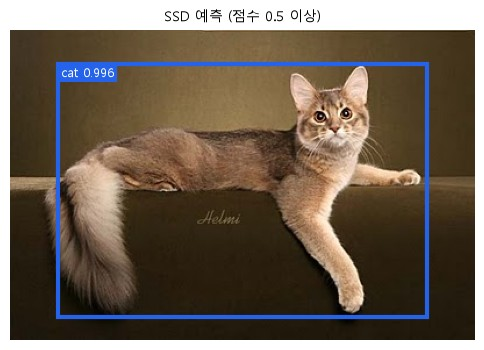

In [7]:
from collections import Counter  # 이름 세기

with torch.no_grad():                       # 예측만
    out = detector([x])[0]                  # 사진 목록을 넣고 → 사진마다 결과 dict
print("열쇠:", list(out.keys()))            # boxes · scores · labels
for k, v in out.items():                    # 열쇠마다
    print(f"{k:7s} 모양 {tuple(v.shape)}")  # 줄 수

# 왜 · 출력 한 줄이 박스 · 이름 · 점수 묶음이라는 것을 읽기 위해
for b, lb, s in zip(out["boxes"][:5], out["labels"][:5], out["scores"][:5]):             # 앞 5줄
    xyxy = [round(v) for v in b.tolist()]                                                # 정수로
    print(f"번호 {lb.item():>2} → {COCO[lb]:10s} 점수 {s:.3f}  박스 {xyxy}")             # 한 줄
print("점수 0.5 넘는 줄:", (out["scores"] > 0.5).sum().item(), "/", len(out["scores"]))  # 1 / 200
print("최대 개수 설정:", detector.detections_per_img)                                    # 200
# 원본 크기
print("박스 x 최댓값:", round(out["boxes"][:, 2].max().item()), "· 사진 가로:", cat_img.size[0])

# 왜 · 출력 200줄에 어떤 이름이 섞여 있는지 세기 위해
names_200 = [COCO[lb] for lb in out["labels"]]               # 200줄의 이름
print("이름 종류 수:", len(set(names_200)))                  # 몇 종류
print("많이 나온 이름:", Counter(names_200).most_common(6))  # 상위 6개
is_person = out["labels"] == COCO.index("person")            # person 줄
print("person 줄 중 가장 높은 점수:", round(out["scores"][is_person].max().item(), 3))  # 낮음

# 왜 · 점수로 거르면 남는 박스가 어떻게 되는지 그림으로 보기 위해
keep = out["scores"] > 0.5  # 점수 0.5 초과만
# 이름표
labels = [f"{COCO[lb]} {s:.3f}" for lb, s in zip(out["labels"][keep], out["scores"][keep])]
draw(cat_img, pred=out["boxes"][keep], labels=labels, title="SSD 예측 (점수 0.5 이상)")  # 그림
plt.show()                  # 그림 출력

**결과** · 예측 정답은 `200`줄 — 그중 0.5를 넘는 줄은 `1`줄

- `boxes   모양 (200, 4)` — 박스 200개 × 숫자 4개
- `번호 17 → cat        점수 0.996  박스 [40, 29, 358, 247]` — 1등 = 고양이 · 박스는 몸 전체
- `점수 0.5 넘는 줄: 1 / 200` — 기준값이 결과 개수를 정함
- `박스 x 최댓값: 400 · 사진 가로: 400` — 박스는 원본 사진 크기 기준 픽셀
- `많이 나온 이름: [('person', 130), ('sheep', 17), ('cat', 13), ('book', 12), ('chair', 8), ('tie', 8)]` — 낮은 점수 줄에는 엉뚱한 이름이 많음
- `person 줄 중 가장 높은 점수: 0.041` — 사람은 없다고 거의 확신

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>boxes</td><td>[N, 4] xyxy 픽셀</td><td>그림 · IoU</td></tr>
<tr><td>scores</td><td>[N] 높은 순 · 신뢰도</td><td>거르기</td></tr>
<tr><td>labels</td><td>[N] COCO 번호</td><td>이름 찾기 <code>COCO[l]</code></td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 사진 하나여도 목록 `[x]`로 넣고 `[0]`으로 꺼냄 (분류처럼 `model(x)`는 에러)

> ✅ **한 줄 정리** · 탐지 모델은 사진마다 boxes · scores · labels를 같은 순서로 최대 200줄 내고, 점수로 걸러서 쓴다.

**딥러닝 코드에서는**

- `for b, s, l in zip(out["boxes"], out["scores"], out["labels"])`

### 2-3. `B` 사진 3장 · 개 + 사람 사진 · `draw(pred=)` <sub>원본 D1-2 · 셀 31 ~ 35</sub>

> 🎯 **같은 모델로 다른 사진과 개 + 사람 사진을 예측하면?**

💡 **쉽게 말하면**

- 분류 모델은 개 하나만 답했지만, 탐지 모델은 **개와 사람을 각각 박스로** 답함.

**실행 흐름**

1. 미션 사진 3장 예측
2. 개 + 사람 사진 예측
3. 0.5 넘는 줄

**먼저 예측** · 개 + 사람 사진에서 0.5를 넘는 줄은 몇 개? — 답은 코드 실행 결과 아래에

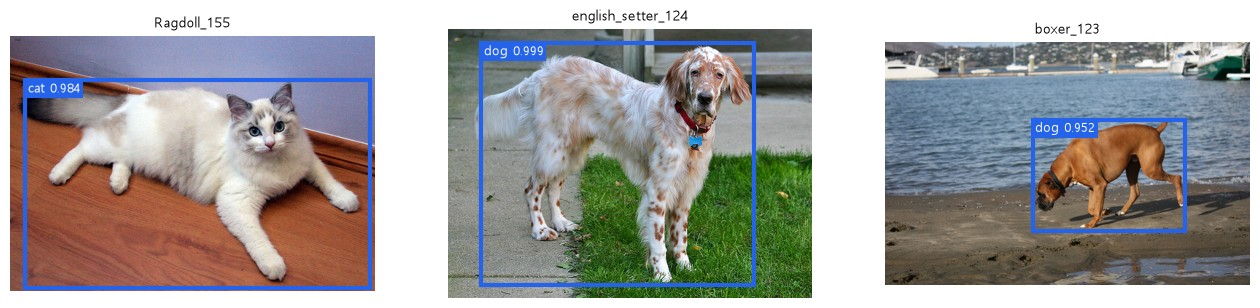

전체 200 줄 · 0.5 넘는 줄: ['dog 0.976', 'person 0.962']


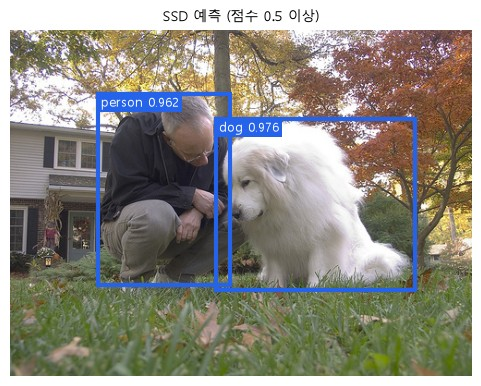

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))     # 미션 사진 3장
for stem, ax in zip(examples, axes):                  # 사진마다
    img = load_image(stem)                            # 사진
    with torch.no_grad():                             # 예측만
        o = detector([det_w.transforms()(img)])[0]    # 예측
    # 왜 · 점수 0.5 초과 박스만 남겨 미션 사진 3장에서 모델이 무엇을 박스로 내는지 보기 위해
    k = o["scores"] > 0.5                             # 0.5 초과만
    draw(img, pred=o["boxes"][k], ax=ax, title=stem,  # 예측 박스
         labels=[f"{COCO[lb]} {s:.3f}" for lb, s in zip(o["labels"][k], o["scores"][k])])
plt.show()                                            # 그림 출력

with torch.no_grad():                                             # 개 + 사람 사진
    # 왜 · 개와 사람이 함께 있는 사진에서 물체마다 박스가 따로 나오는지 확인하기 위해
    out2 = detector([det_w.transforms()(pair)])[0]                # 예측
keep2 = out2["scores"] > 0.5                                      # 0.5 초과만
# 이름표
labels2 = [f"{COCO[lb]} {s:.3f}" for lb, s in zip(out2["labels"][keep2], out2["scores"][keep2])]
print("전체", len(out2["scores"]), "줄 · 0.5 넘는 줄:", labels2)  # 개와 사람을 둘 다
draw(pair, pred=out2["boxes"][keep2], labels=labels2, title="SSD 예측 (점수 0.5 이상)")  # 그림
plt.show()                                                        # 그림 출력

**결과** · 예측 정답은 `2`개 — dog · person

- `전체 200 줄 · 0.5 넘는 줄: ['dog 0.976', 'person 0.962']` — 분류(1-2)가 못 한 '사람'까지 찾음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>분류 결과</td><td>Great Pyrenees 하나</td><td>1-2</td></tr>
<tr><td>탐지 결과</td><td>dog + person 각각 박스</td><td>여러 물체</td></tr>
<tr><td>탐지 출력 3가지</td><td>boxes · scores · labels</td><td>모든 탐지 모델 공통</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 박스는 몸 전체 → 우리 미션의 머리 박스와는 다름 (4장 IoU)

> ✅ **한 줄 정리** · 탐지 모델은 한 사진의 여러 물체를 각각 박스 · 이름 · 점수로 답한다.

**딥러닝 코드에서는**

- 한 사진에 여러 클래스 → 4장에서 클래스별 NMS

---
## 3. 박스 숫자 4개 · XML

> **이 장의 흐름**
>
> - 2장의 박스 숫자를 정답 XML과 같은 약속으로 읽음
> - 표기 · 크기 · 뒤집기 · 파일 이름 규칙

<img src="images/od1_box_formats.png" alt="같은 박스를 적는 세 가지 표기" width="638">

**파이프라인 위치** · ① 데이터 준비 · ③ 전처리

### 3-1. `A` XML 원문 · 읽기 · `ET.parse()` · `findtext()` · `iter()` <sub>원본 D1-3 · 셀 36 ~ 43</sub>

> 🎯 **XML 정답 파일에서 사진 크기 · 이름 · 박스를 어떻게 꺼내는가?**

💡 **쉽게 말하면**

- XML은 **태그로 칸을 나눈 정답지**.
- `<object>` 하나가 물체 하나, 그 안 `<bndbox>`에 박스 네 숫자.

**실행 흐름**

1. 원문 출력
2. filename · size · object
3. read_voc 도우미
4. README의 xmls 설명 · 개 예시 · 그림

**먼저 예측** · Abyssinian_173 박스의 네 숫자와 이름은? — 답은 코드 실행 결과 아래에

<annotation>
  <folder>OXIIIT</folder>
  <filename>Abyssinian_173.jpg</filename>
  <source>
    <database>OXFORD-IIIT Pet Dataset</database>
    <annotation>OXIIIT</annotation>
    <image>flickr</image>
  </source>
  <size>
    <width>400</width>
    <height>267</height>
    <depth>3</depth>
  </size>
  <segmented>0</segmented>
  <object>
    <name>cat</name>
    <pose>Frontal</pose>
    <truncated>0</truncated>
    <occluded>0</occluded>
    <bndbox>
      <xmin>241</xmin>
      <ymin>31</ymin>
      <xmax>310</xmax>
      <ymax>102</ymax>
    </bndbox>
    <difficult>0</difficult>
  </object>
</annotation>
filename : Abyssinian_173.jpg
size     : 400 × 267
name     : cat
bndbox   : [241, 31, 310, 102]
실제 사진 크기: (400, 267)
[[241.0, 31.0, 310.0, 102.0]] ['cat']
['xmls/ Head bounding box annotations in PASCAL VOC Format']
[[300.0, 24.0, 414.0, 121.0]] ['dog']


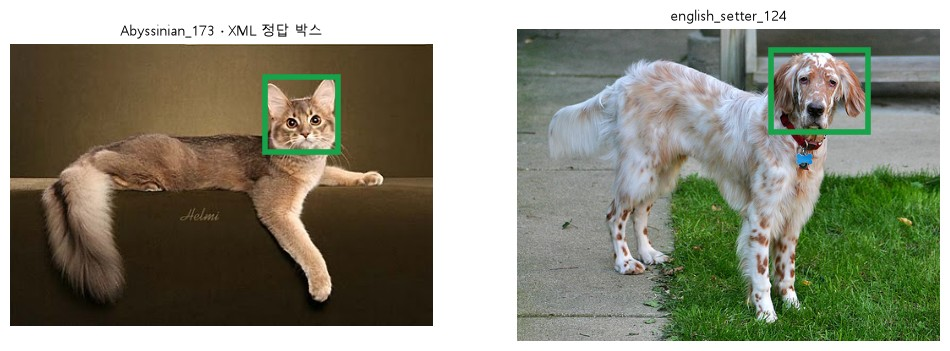

In [9]:
# 왜 · 정답 XML 원문 구조를 직접 열어 보기 위해
xml_path = XMLS / "Abyssinian_173.xml"        # 정답 파일 하나
root = ET.parse(xml_path).getroot()           # XML 열기
ET.indent(root)                               # 한 줄짜리 원문을 보기 좋게 줄바꿈
print(ET.tostring(root, encoding="unicode"))  # 원문

# 왜 · 필요한 정답 값을 태그 이름으로 꺼내는 법을 익히기 위해
print("filename :", root.findtext("filename"))  # 짝이 되는 사진
print("size     :", root.findtext("size/width"), "×", root.findtext("size/height"))  # 사진 크기
for obj in root.iter("object"):                 # 물체 하나 = object 하나
    bb = obj.find("bndbox")                     # 박스
    print("name     :", obj.findtext("name"))   # 이름
    print("bndbox   :", [int(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")])  # 네 숫자
print("실제 사진 크기:", cat_img.size)          # XML 크기와 같은지

# 왜 · 직접 읽은 값과 함수 결과가 같은지 확인하기 위해
boxes, names = read_voc(xml_path)      # 위 과정을 묶어 둔 도우미
print(boxes, names)                    # 박스 목록 · 이름 목록
readme = (ANN / "README").read_text()  # 데이터 설명서
# xmls 설명
print([" ".join(line.split()) for line in readme.splitlines() if line.startswith("xmls")])

# 왜 · 개 사진에서도 같은 함수가 통하는지 확인하기 위해
dog_boxes, dog_names = read_voc(XMLS / "english_setter_124.xml")             # 두 번째 예: 개
print(dog_boxes, dog_names)                                                  # 개 머리 박스
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))                            # 2칸
draw(cat_img, gt=boxes, title="Abyssinian_173 · XML 정답 박스", ax=axes[0])  # 고양이
draw(load_image("english_setter_124"), gt=dog_boxes, title="english_setter_124", ax=axes[1])  # 개
plt.show()                                                                   # 그림 출력

**결과** · 예측 정답은 `[241, 31, 310, 102]` · `cat` — 몸이 아니라 **머리** 박스

- `filename : Abyssinian_173.jpg` — 짝이 되는 사진
- `size     : 400 × 267` — 사진 크기 = 실제 사진과 같음
- `bndbox   : [241, 31, 310, 102]` — xmin · ymin · xmax · ymax
- `['xmls/ Head bounding box annotations in PASCAL VOC Format']` — README: 머리 박스 · VOC 형식
- `[[300.0, 24.0, 414.0, 121.0]] ['dog']` — 개도 머리 박스

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>findtext()</code></td><td>글자 하나</td><td>filename · name</td></tr>
<tr><td><code>find()</code></td><td>태그 하나</td><td>bndbox</td></tr>
<tr><td><code>iter("object")</code></td><td>같은 태그 모두</td><td>물체 여러 개</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `findtext`는 문자열 → 계산 전 `float()` · `int()`

> ✅ **한 줄 정리** · XML은 `ET.parse`로 읽고 물체마다 `<object>`의 name과 bndbox 네 숫자를 꺼내며, 이 데이터의 정답은 머리 박스다.

**딥러닝 코드에서는**

- 탐지 Dataset의 `__getitem__` 안에서 `read_voc(stem)` (객체탐지-2 1-2)

### 3-2. `A` 숫자를 잘못 읽으면 · 박스로 자르기 · `crop()` · `arr[y1:y2, x1:x2]` <sub>원본 D1-3 · 셀 44 ~ 48</sub>

> 🎯 **뒤 두 숫자를 너비 · 높이로 잘못 읽으면, 그리고 박스로 사진을 자를 때 순서는?**

💡 **쉽게 말하면**

- 박스 표기를 섞어 읽으면 **엉뚱한 집 주소**가 됨.
- PIL은 (가로, 세로), 배열은 (세로, 가로) 순서.

**실행 흐름**

1. xywh로 잘못 읽은 박스 · 그림
2. PIL crop
3. 배열 슬라이싱 · 모양 비교

**먼저 예측** · 310 · 102를 너비 · 높이로 읽으면 박스 오른쪽 끝은? — 답은 코드 실행 결과 아래에

xyxy로 읽음      : [241.0, 31.0, 310.0, 102.0]
xywh로 잘못 읽음 : [241.0, 31.0, 551.0, 133.0] · 사진 너비 400


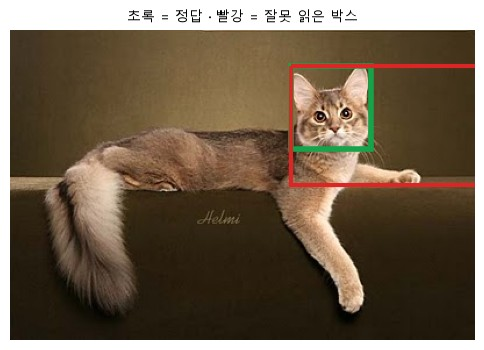

사진 배열 모양: (267, 400, 3)
crop 크기 (가로, 세로): (69, 71) · 배열 조각 모양: (71, 69, 3)


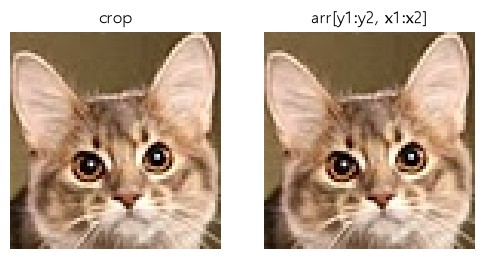

In [10]:
x1, y1, x2, y2 = boxes[0]                                                  # xyxy 네 숫자
wrong = [x1, y1, x1 + x2, y1 + y2]  # 310, 102를 너비 · 높이로 읽은 경우
print("xyxy로 읽음      :", boxes[0])                                      # 올바른 박스
print("xywh로 잘못 읽음 :", wrong, "· 사진 너비", cat_img.size[0])         # 사진 밖으로 나감
ax = draw(cat_img, gt=boxes, title="초록 = 정답 · 빨강 = 잘못 읽은 박스")  # 정답
_box(ax, wrong, "#dc2626", lw=3)                                           # 잘못 읽은 박스
plt.show()                                                                 # 그림 출력

# 왜 · PIL과 배열의 좌표 순서 차이를 박스 자르기로 확인하기 위해
x1, y1, x2, y2 = [int(v) for v in boxes[0]]     # 정수로
face = cat_img.crop((x1, y1, x2, y2))           # PIL crop = (왼, 위, 오른, 아래) = xyxy 그대로
arr = np.array(cat_img)                         # 배열 모양 = (세로, 가로, 채널)
face_arr = arr[y1:y2, x1:x2]                    # 배열은 [행 = y, 열 = x] → y가 먼저
print("사진 배열 모양:", arr.shape)             # (267, 400, 3)
print("crop 크기 (가로, 세로):", face.size, "· 배열 조각 모양:", face_arr.shape)  # 순서가 반대
fig, axes = plt.subplots(1, 2, figsize=(6, 3))  # 같은 얼굴 두 방법
axes[0].imshow(face)                            # crop 결과
axes[0].set_title("crop")                       # 제목
axes[1].imshow(face_arr)                        # 배열 조각
axes[1].set_title("arr[y1:y2, x1:x2]")          # 제목
for a in axes:                                  # 두 칸
    a.axis("off")                               # 눈금 숨김
plt.show()                                      # 그림 출력

**결과** · 예측 정답은 `551` — 사진 너비 400을 넘음

- `xywh로 잘못 읽음 : [241.0, 31.0, 551.0, 133.0] · 사진 너비 400` — 사진 밖으로 나감 (빨강)
- `사진 배열 모양: (267, 400, 3)` — (세로, 가로, 채널)
- `crop 크기 (가로, 세로): (69, 71) · 배열 조각 모양: (71, 69, 3)` — 같은 얼굴 · 순서가 반대

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>img.crop((x1, y1, x2, y2))</code></td><td>xyxy 그대로</td><td>PIL 사진</td></tr>
<tr><td><code>arr[y1:y2, x1:x2]</code></td><td>y가 먼저</td><td>numpy 배열 · 텐서</td></tr>
<tr><td>xywh로 읽기</td><td>형식이 다르면 엉뚱한 박스</td><td>형식 확인 후에만</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - matplotlib `Rectangle((x, y), w, h)`는 xywh로 받음 → xyxy를 그릴 때 너비 · 높이로 바꿈

> ✅ **한 줄 정리** · 박스 형식을 먼저 확인하고, 배열로 자를 때는 y(행)가 먼저다.

**딥러닝 코드에서는**

- `img_tensor[:, y1:y2, x1:x2]` — 텐서는 (C, H, W)

### 3-3. `A` 같은 박스 · 세 가지 표기 · `box_convert()` <sub>원본 D1-3 · 셀 49 · 50</sub>

> 🎯 **같은 박스를 숫자 네 개로 적는 방법은 몇 가지인가?**

💡 **쉽게 말하면**

- 두 모서리(xyxy) · 모서리 + 크기(xywh) · 가운데 + 크기(cxcywh).
- 모두 같은 박스를 가리킴.

**실행 흐름**

1. xyxy
2. xywh · cxcywh 변환
3. 얼굴 넓이 비율

**먼저 예측** · xywh로 바꾸면 너비 · 높이는? — 답은 코드 실행 결과 아래에

In [11]:
from torchvision.ops import box_convert  # 박스 표기 바꾸기

# 왜 · 같은 박스를 세 표기로 바꿔 숫자 차이를 보기 위해
b = torch.tensor(boxes)                                      # 모양 [박스 수, 4]
print("xyxy  :", b.tolist())                                 # 두 모서리
print("xywh  :", box_convert(b, "xyxy", "xywh").tolist())    # 왼쪽 위 + 너비 · 높이
print("cxcywh:", box_convert(b, "xyxy", "cxcywh").tolist())  # 가운데 점 + 너비 · 높이

# 왜 · 0~1 비율 표기는 사진 크기로 나눈 값이라는 것을 확인하기 위해
W_img, H_img = cat_img.size                                                     # 사진 크기
w, h = b[0, 2] - b[0, 0], b[0, 3] - b[0, 1]                                     # 얼굴 너비 · 높이
print(f"얼굴 넓이 = {w:.0f} × {h:.0f} → 사진의 {w * h / (W_img * H_img):.1%}")  # 작은 얼굴

xyxy  : [[241.0, 31.0, 310.0, 102.0]]
xywh  : [[241.0, 31.0, 69.0, 71.0]]
cxcywh: [[275.5, 66.5, 69.0, 71.0]]
얼굴 넓이 = 69 × 71 → 사진의 4.6%


**결과** · 예측 정답은 `69` · `71`

- `xywh  : [[241.0, 31.0, 69.0, 71.0]]` — 왼쪽 위 + 너비 · 높이
- `cxcywh: [[275.5, 66.5, 69.0, 71.0]]` — 가운데 241 + 69 ÷ 2 = 275.5
- `얼굴 넓이 = 69 × 71 → 사진의 4.6%` — 작은 물체

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>xyxy</td><td>두 모서리</td><td>torchvision · VOC XML</td></tr>
<tr><td>xywh</td><td>왼쪽 위 + 크기</td><td>COCO JSON · matplotlib</td></tr>
<tr><td>cxcywh</td><td>가운데 + 크기</td><td>YOLO (0~1로 나눔)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 형식을 확인하지 않고 섞으면 에러 없이 틀린 박스

> ✅ **한 줄 정리** · 박스는 xyxy · xywh · cxcywh 중 어느 형식인지 먼저 확인하고, 다르면 `box_convert`로 바꾼다.

**딥러닝 코드에서는**

- `box_convert(b, "xywh", "xyxy")` — COCO 정답을 torchvision에 넣기 전

### 3-4. `A` 크기 바꾸기 · 좌우 뒤집기와 박스 · `resize()` · `ImageOps.mirror()` <sub>원본 D1-3 · 셀 51 ~ 55</sub>

> 🎯 **사진을 300×300으로 줄이거나 좌우로 뒤집으면 박스 숫자는?**

💡 **쉽게 말하면**

- 박스는 **사진에 붙은 스티커 위치**.
- 사진을 늘리면 같은 비율로, 거울에 비추면 왼쪽 · 오른쪽 변이 바뀜.

**실행 흐름**

1. 가로 · 세로 배율 따로 곱하기
2. W - x만 한 박스 vs 변을 바꾼 박스
3. 그림 3칸

**먼저 예측** · 좌우로 뒤집은 뒤 `W - x`만 하면 무엇이 문제일까? — 답은 코드 실행 결과 아래에

가로 배율 0.750 · 세로 배율 1.124
그대로 둔 박스: [241.0, 31.0, 310.0, 102.0]
배율 곱한 박스: [180.8, 34.8, 232.5, 114.6]
W - x만 한 박스 : [159.0, 31.0, 90.0, 102.0] → xmin < xmax ? False
변을 바꾼 박스  : [90.0, 31.0, 159.0, 102.0] → xmin < xmax ? True


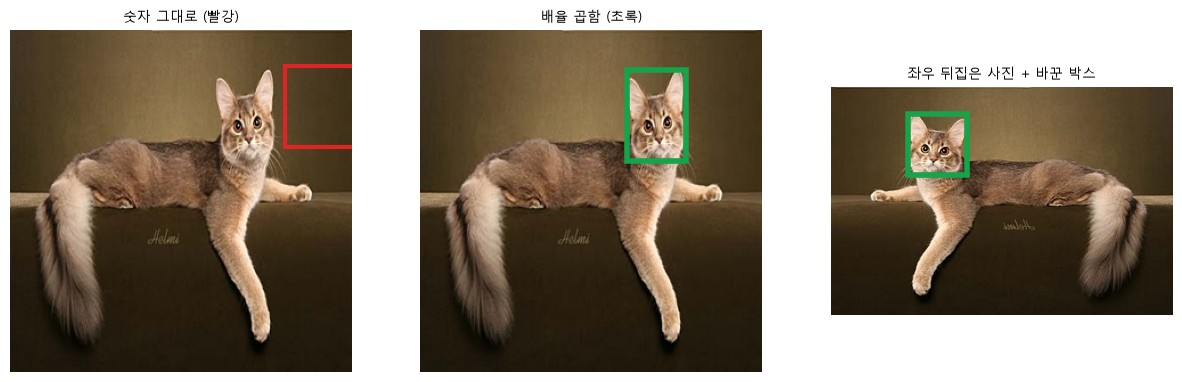

In [12]:
from PIL import ImageOps  # 좌우 뒤집기

# 왜 · 사진 크기를 바꾸면 박스도 같은 배율로 바꿔야 한다는 것을 보이기 위해
small = cat_img.resize((300, 300))                              # SSD 입력 크기
sx, sy = 300 / cat_img.size[0], 300 / cat_img.size[1]           # 가로 · 세로 배율
x1, y1, x2, y2 = boxes[0]                                       # 원래 박스
scaled = [x1 * sx, y1 * sy, x2 * sx, y2 * sy]                   # x는 가로 배율 · y는 세로 배율
print(f"가로 배율 {sx:.3f} · 세로 배율 {sy:.3f}")               # 배율이 다름
print("그대로 둔 박스:", boxes[0])                              # 틀린 박스
print("배율 곱한 박스:", [round(v, 1) for v in scaled])         # 맞는 박스
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))               # 3칸
_box(draw(small, title="숫자 그대로 (빨강)", ax=axes[0]), boxes[0], "#dc2626")  # 어긋남
draw(small, gt=[scaled], title="배율 곱함 (초록)", ax=axes[1])  # 맞음

# 왜 · 좌우 뒤집기에서 박스 두 변을 맞바꿔야 한다는 것을 보이기 위해
flipped = ImageOps.mirror(cat_img)                                           # 좌우 뒤집기
W_img = cat_img.size[0]                                                      # 사진 폭
naive = [W_img - x1, y1, W_img - x2, y2]                                     # x만 W - x로 바꿈
fixed = [W_img - x2, y1, W_img - x1, y2]  # 뒤집히면 왼쪽 · 오른쪽 변이 서로 바뀜
print("W - x만 한 박스 :", naive, "→ xmin < xmax ?", naive[0] < naive[2])    # 순서가 뒤집힘
print("변을 바꾼 박스  :", fixed, "→ xmin < xmax ?", fixed[0] < fixed[2])    # 올바름
draw(flipped, gt=[fixed], title="좌우 뒤집은 사진 + 바꾼 박스", ax=axes[2])  # 그림
plt.show()                                                                   # 그림 출력

**결과** · 예측 정답은 xmin이 xmax보다 커짐 (`159 > 90`)

- `가로 배율 0.750 · 세로 배율 1.124` — 300 ÷ 400 · 300 ÷ 267 → 배율이 다름
- `배율 곱한 박스: [180.8, 34.8, 232.5, 114.6]` — x는 0.75배 · y는 1.124배
- `W - x만 한 박스 : [159.0, 31.0, 90.0, 102.0] → xmin < xmax ? False` — 모서리 순서가 뒤집힘
- `변을 바꾼 박스  : [90.0, 31.0, 159.0, 102.0] → xmin < xmax ? True` — 400 - 310 = 90 · 400 - 241 = 159

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>크기 바꾸기</td><td>x · y에 각각 배율</td><td>입력 크기 맞추기</td></tr>
<tr><td>좌우 뒤집기</td><td><code>W - x</code> 후 두 변 맞바꿈</td><td>증강</td></tr>
<tr><td><code>transforms.v2</code></td><td>사진 + 박스를 함께</td><td>실전 (객체탐지-2 2-1)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 사진만 바꾸고 박스를 그대로 두면 에러 없이 정답이 틀어짐

> ✅ **한 줄 정리** · 크기를 바꾸면 x · y에 각각의 배율을 곱하고, 좌우로 뒤집으면 `W - x` 후 두 변을 맞바꾼다.

**딥러닝 코드에서는**

- `v2.RandomHorizontalFlip(0.5)(img, target)`

### 3-5. `B` 파일 이름과 XML name · `stem[0].isupper()` <sub>원본 D1-3 · 셀 56 ~ 59</sub>

> 🎯 **파일 이름 첫 글자 대문자 = 고양이 규칙은 XML 이름과 맞는가?**

💡 **쉽게 말하면**

- Oxford Pet은 **고양이 품종은 대문자, 개 품종은 소문자**로 시작.
- XML의 cat · dog와 전부 맞는지 셈.

**실행 흐름**

1. 4장 예시: 첫 글자 · 품종 · XML name
2. XML 전부 규칙 대조

**먼저 예측** · 규칙과 맞는 XML은 몇 개? — 답은 코드 실행 결과 아래에

In [13]:
# 왜 · 파일 이름 첫 글자와 XML 이름의 관계를 사진 몇 장으로 확인하기 위해
for stem in ["Abyssinian_173", "Ragdoll_155", "english_setter_124", "boxer_123"]:  # 4장
    breed = stem.rsplit("_", 1)[0]  # 파일명 = 품종_번호
    _, names = read_voc(XMLS / f"{stem}.xml")                                      # XML 이름
    print(f"{stem:20s} 첫 글자 {stem[0]} · 품종 {breed:16s} → xml name {names}")   # 비교

# 왜 · 그 규칙이 XML 전체에서도 맞는지 세어 보기 위해
match, total = 0, 0                                       # 규칙이 맞는 수 · 전체
for p in XMLS.glob("*.xml"):                              # XML 전부
    _, names = read_voc(p)                                # 이름
    rule = "cat" if p.stem[0].isupper() else "dog"        # 대문자 = 고양이 · 소문자 = 개
    match += all(n == rule for n in names)                # 규칙과 같은가
    total += 1                                            # 전체 수
print(f"규칙과 xml name이 맞는 파일: {match} / {total}")  # 모두 맞음

Abyssinian_173       첫 글자 A · 품종 Abyssinian       → xml name ['cat']
Ragdoll_155          첫 글자 R · 품종 Ragdoll          → xml name ['cat']
english_setter_124   첫 글자 e · 품종 english_setter   → xml name ['dog']
boxer_123            첫 글자 b · 품종 boxer            → xml name ['dog']


규칙과 xml name이 맞는 파일: 3686 / 3686


**결과** · 예측 정답은 `3686 / 3686` — 전부

- `Abyssinian_173       첫 글자 A · 품종 Abyssinian       → xml name ['cat']` — 대문자 = 고양이
- `english_setter_124   첫 글자 e · 품종 english_setter   → xml name ['dog']` — 소문자 = 개
- `규칙과 xml name이 맞는 파일: 3686 / 3686` — 규칙이 정답과 일치

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>XML name</td><td>정답 그대로</td><td>라벨 (기본)</td></tr>
<tr><td>파일 이름 규칙</td><td>대문자 = cat</td><td>XML이 없는 사진의 종류 짐작</td></tr>
<tr><td>품종 = 이름에서 번호 떼기</td><td><code>rsplit("_", 1)[0]</code></td><td>층화 분할 (객체탐지-2 1-1)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 규칙은 확인한 뒤에만 씀 → 전부 맞는지 먼저 셈

> ✅ **한 줄 정리** · Oxford Pet은 파일 이름 첫 글자로 고양이 · 개를 구분할 수 있고, XML 이름과 모두 일치한다.

**딥러닝 코드에서는**

- `breed = stem.rsplit("_", 1)[0]` — 품종 비율을 지키는 분할에 씀

---
## 4. IoU

> **이 장의 흐름**
>
> - 3장에서 예측과 정답을 같은 형식으로
> - 겹친 넓이 ÷ 합친 넓이 · 실제 사진

<img src="images/od1_iou.png" alt="IoU = 겹친 넓이 ÷ 합친 넓이" width="744">

**파이프라인 위치** · ⑥ 평가 — 박스 하나

### 4-1. `A` IoU 손계산 · box_iou · `box_iou()` <sub>원본 D1-4 · 셀 60 ~ 67</sub>

> 🎯 **예측 박스가 정답과 얼마나 맞았는지 숫자 하나로 어떻게 재는가?**

💡 **쉽게 말하면**

- IoU는 **겹친 넓이 ÷ 합친 넓이**.
- 너무 커도 · 너무 작아도 낮아짐.

**실행 흐름**

1. 겹친 가로 · 세로 · 넓이
2. 합친 넓이 · IoU
3. box_iou로 예측 4개 한 번에

**먼저 예측** · 한 변 100인 정답을 오른쪽으로 50 밀면 IoU는? — 답은 코드 실행 결과 아래에

In [14]:
from torchvision.ops import box_iou  # 박스 표의 IoU

# 왜 · IoU 공식을 손으로 따라가며 계산하기 위해
gt = [100, 100, 200, 200]                              # 정답 박스 (xmin, ymin, xmax, ymax)
pred = [150, 100, 250, 200]                            # 예측 박스: 오른쪽으로 반만 밀림
w = min(gt[2], pred[2]) - max(gt[0], pred[0])          # 겹친 부분 가로
h = min(gt[3], pred[3]) - max(gt[1], pred[1])          # 겹친 부분 세로
inter = max(w, 0) * max(h, 0)                          # 안 겹치면 0
area_gt = (gt[2] - gt[0]) * (gt[3] - gt[1])            # 정답 넓이
area_pred = (pred[2] - pred[0]) * (pred[3] - pred[1])  # 예측 넓이
union = area_gt + area_pred - inter                    # 겹친 부분은 한 번만
print("겹친 넓이:", inter)                             # 5000
print("합친 넓이:", union)                             # 15000
print("IoU      :", round(inter / union, 2))           # 0.33

# 왜 · 손계산 결과를 box_iou로 검증하기 위해
gt_t = torch.tensor([gt], dtype=torch.float)          # 정답 1개
preds = torch.tensor([[110, 100, 210, 200],           # A 조금 밀기
                      [150, 100, 250, 200],           # B 반만 밀기
                      [79.3, 79.3, 220.7, 220.7],     # C 넓이 두 배
                      [114.6, 114.6, 185.4, 185.4]])  # D 넓이 반
print(box_iou(gt_t, preds).round(decimals=2))         # 행 = 정답, 열 = 예측

겹친 넓이: 5000
합친 넓이: 15000
IoU      : 0.33
tensor([[0.8200, 0.3300, 0.5000, 0.5000]])


**결과** · 예측 정답은 `0.33` — 5000 ÷ 15000

- `겹친 넓이: 5000` — 50 × 100 = 5000
- `합친 넓이: 15000` — 10000 + 10000 - 5000 = 15000
- `IoU      : 0.33` — 반만 겹쳐도 1/3
- `tensor([[0.8200, 0.3300, 0.5000, 0.5000]])` — 조금 밀기 · 반 밀기 · 넓이 2배 · 넓이 반

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>손계산</td><td>식 확인</td><td>원리</td></tr>
<tr><td><code>box_iou(A, B)</code></td><td>N × M 표</td><td>실제 계산 (기본)</td></tr>
<tr><td>넓이 2배 · 반</td><td>감싸도 · 쏙 들어가도 0.5</td><td>크기 오차 이해</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 안 겹치면 가로 · 세로가 음수 → `max(·, 0)` 필수

> ✅ **한 줄 정리** · IoU는 겹친 넓이 ÷ 합친 넓이(0 ~ 1)이고, 위치가 밀려도 크기가 달라도 낮아진다.

**딥러닝 코드에서는**

- `box_iou(pred_boxes, gt_boxes)` → (예측 수, 정답 수) 표

### 4-2. `A` 같은 10픽셀, 다른 결과 · `box_iou()` <sub>원본 D1-4 · 셀 68 ~ 70</sub>

> 🎯 **같은 10픽셀을 밀어도 IoU는 왜 다르게 떨어지는가?**

💡 **쉽게 말하면**

- IoU는 **비율**이라 큰 박스의 10픽셀은 작은 흠, 작은 박스의 10픽셀은 절반이 사라지는 것.

**실행 흐름**

1. 한 변 100 · 20 박스
2. 오른쪽으로 10픽셀
3. IoU 비교

**먼저 예측** · 한 변 20인 박스를 10픽셀 밀면 IoU는? — 답은 코드 실행 결과 아래에

In [15]:
# 왜 · 같은 10픽셀 오차도 박스 크기에 따라 IoU가 달라지는 것을 보이기 위해
big = torch.tensor([[100, 100, 200, 200]], dtype=torch.float)    # 한 변 100 박스
small = torch.tensor([[100, 100, 120, 120]], dtype=torch.float)  # 한 변 20 박스
shift = torch.tensor([10, 0, 10, 0])                             # 오른쪽으로 10픽셀
print("큰 박스   10픽셀 밀기 → IoU", round(box_iou(big, big + shift).item(), 2))  # 10%만 밀림
print("작은 박스 10픽셀 밀기 → IoU", round(box_iou(small, small + shift).item(), 2))  # 절반이 밀림

큰 박스   10픽셀 밀기 → IoU 0.82
작은 박스 10픽셀 밀기 → IoU 0.33


**결과** · 예측 정답은 `0.33`

- `큰 박스   10픽셀 밀기 → IoU 0.82` — 10픽셀 = 한 변의 10%
- `작은 박스 10픽셀 밀기 → IoU 0.33` — 10픽셀 = 한 변의 절반

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>큰 물체</td><td>픽셀 오차에 덜 민감</td><td>AP 높음</td></tr>
<tr><td>작은 물체</td><td>픽셀 오차에 매우 민감</td><td>AP 낮음 (크기별 AP)</td></tr>
<tr><td>IoU</td><td>비율</td><td>크기가 달라도 같은 기준</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 작은 얼굴일수록 같은 오차에 IoU가 크게 떨어짐 → 놓치기 쉬움 (객체탐지-2 6-2)

> ✅ **한 줄 정리** · IoU는 크기에 대한 비율이라 작은 물체일수록 같은 픽셀 오차에 크게 떨어진다.

**딥러닝 코드에서는**

- COCO 평가의 `map_small` · `map_large`가 따로 있는 이유

### 4-3. `A` 실제 사진: 모델 박스 vs 정답 박스 · `area()` · `overlap()` <sub>원본 D1-4 · 셀 71 ~ 80</sub>

> 🎯 **신뢰도 0.99 박스의 IoU가 0.16인 이유와 0.76인 사진의 차이는?**

💡 **쉽게 말하면**

- COCO 모델은 **몸 전체**에 박스를 치도록 배웠고, 우리 정답은 **머리**.
- 얼굴이 사진을 거의 채우면 몸 박스 ≈ 머리 박스라 우연히 높음.

**실행 흐름**

1. 두 사진 예측 · 정답 · IoU
2. 그림 2칸
3. 넓이 배수 · 정답이 예측 안에 든 비율

**먼저 예측** · Russian_Blue_123의 예측 넓이는 정답의 몇 배? — 답은 코드 실행 결과 아래에

[Russian_Blue_123] 예측: cat 0.99 [154, 82, 328, 354]
[Russian_Blue_123] 정답: ['cat'] [[246.0, 82.0, 334.0, 176.0]]
[Russian_Blue_123] IoU: [0.16]


[Birman_164] 예측: cat 0.97 [5, 2, 349, 313]
[Birman_164] 정답: ['cat'] [[45.0, 10.0, 315.0, 309.0]]
[Birman_164] IoU: [0.76]


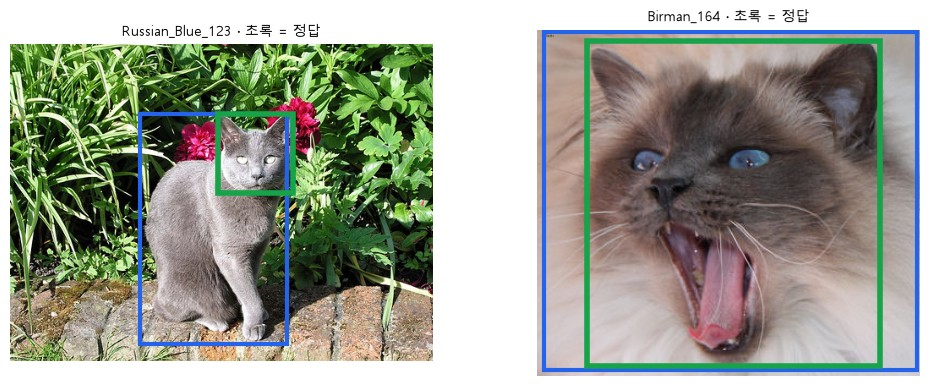

Russian_Blue_123  예측 넓이 = 정답의 5.7배 · 정답이 예측 안에 0.93 · IoU 0.16
Birman_164        예측 넓이 = 정답의 1.3배 · 정답이 예측 안에 1.00 · IoU 0.76


In [16]:
# 왜 · 넓이 · 겹침을 직접 계산해 IoU와 '정답 안에 든 비율'을 비교하기 위해
def area(b):                              # 박스 넓이
    return (b[2] - b[0]) * (b[3] - b[1])  # 너비 × 높이


def overlap(a, b):                         # 겹친 넓이
    w = min(a[2], b[2]) - max(a[0], b[0])  # 겹친 가로
    h = min(a[3], b[3]) - max(a[1], b[1])  # 겹친 세로
    return max(w, 0) * max(h, 0)           # 음수면 0


# 왜 · 실제 사진에서 모델 박스와 정답 박스를 모아 비교하기 위해
rows = []  # (사진, 예측 박스, 정답 박스)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))                           # 두 사진
for stem, ax in zip(["Russian_Blue_123", "Birman_164"], axes):              # 사진마다
    img = load_image(stem)                                                  # 사진
    gt_boxes, gt_names = read_voc(XMLS / f"{stem}.xml")                     # 머리 정답
    with torch.no_grad():                                                   # 예측만
        o = detector([det_w.transforms()(img)])[0]                          # SSD 예측
    keep = o["scores"] > 0.5  # 점수 높은 것만 (점수의 뜻은 5장)
    pred_boxes = o["boxes"][keep]                                           # 남은 박스
    for b, lb, s in zip(pred_boxes, o["labels"][keep], o["scores"][keep]):  # 예측마다
        # 몸 박스
        print(f"[{stem}] 예측:", COCO[lb], round(s.item(), 2), [round(v) for v in b.tolist()])
    print(f"[{stem}] 정답:", gt_names, gt_boxes)                            # 머리 박스
    iou = box_iou(pred_boxes, torch.tensor(gt_boxes, dtype=torch.float))    # 예측 × 정답
    print(f"[{stem}] IoU:", [round(v, 2) for v in iou.flatten().tolist()])  # 겹침
    draw(img, gt=gt_boxes, pred=pred_boxes.tolist(), title=f"{stem} · 초록 = 정답", ax=ax)  # 그림
    rows.append((stem, pred_boxes[0].tolist(), gt_boxes[0]))                # 아래 비교용
plt.show()                                                                  # 그림 출력

# 왜 · 정답이 머리라 몸 박스는 IoU가 낮게 나오는 이유를 숫자로 보기 위해
for name, p, g in rows:                                                 # 왜 0.16과 0.76인가
    inside = overlap(p, g) / area(g)                                    # 정답 중 예측 안에 든 비율
    iou_v = overlap(p, g) / (area(p) + area(g) - overlap(p, g))         # IoU
    print(f"{name:17s} 예측 넓이 = 정답의 {area(p) / area(g):.1f}배 ·"  # 넓이 배수 · 포함 · IoU
          f" 정답이 예측 안에 {inside:.2f} · IoU {iou_v:.2f}")

**결과** · 예측 정답은 `5.7`배 — IoU 0.16

- `[Russian_Blue_123] IoU: [0.16]` — 몸 박스 vs 머리 정답
- `[Birman_164] IoU: [0.76]` — 얼굴이 사진을 채움
- `Russian_Blue_123  예측 넓이 = 정답의 5.7배 · 정답이 예측 안에 0.93 · IoU 0.16` — 머리를 감싸도 너무 큼
- `Birman_164        예측 넓이 = 정답의 1.3배 · 정답이 예측 안에 1.00 · IoU 0.76` — 크기가 비슷

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>정답이 예측 안에 든 비율</td><td>크게 치면 1</td><td>IoU 대신 쓰지 않음</td></tr>
<tr><td>IoU</td><td>크기 차이도 벌점</td><td>평가 기준 (기본)</td></tr>
<tr><td>정답 정의 확인</td><td>머리 vs 몸 전체</td><td>평가 전 필수</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 신뢰도는 모델의 확신이지 정답과의 겹침이 아님 → 0.99도 IoU 0.16일 수 있음

> ✅ **한 줄 정리** · 정답의 정의가 다르면 확신이 높아도 IoU가 낮고, 구도에 따라 우연히 높게 겹칠 수 있다.

**딥러닝 코드에서는**

- 우리 정답(머리)으로 다시 학습해야 하는 이유 (객체탐지-2)

---
## 5. 신뢰도 · NMS · 한 줄로

> **이 장의 흐름**
>
> - 200줄 · NMS 직전 후보
> - 점수로 거르기 → 클래스별 NMS → 최종 박스

<img src="images/od1_nms.png" alt="NMS: 1등을 남기고 많이 겹친 후보를 지우기를 반복" width="763">

**파이프라인 위치** · ④ 모델 출력 정리

### 5-1. `A` 신뢰도와 임곗값 · `scores > thr` <sub>원본 D1-5 · 셀 81 ~ 86</sub>

> 🎯 **신뢰도 임곗값을 바꾸면 결과 박스 수는 어떻게 바뀌는가?**

💡 **쉽게 말하면**

- 신뢰도는 **모델이 손을 드는 자신감**.
- 정확도가 아니고, 기준값은 목적에 따라 정함.

**실행 흐름**

1. 버먼 고양이 200줄 · 앞 5줄
2. 기준 0.5 · 0.25 · 0.01
3. 4장 두 사진의 신뢰도 vs IoU

**먼저 예측** · 신뢰도 > 0.01로 거르면 몇 개가 남을까? — 답은 코드 실행 결과 아래에

In [17]:
# 왜 · 신뢰도 임곗값에 따라 남는 박스 수가 바뀌는 것을 보기 위해
stem = "Birman_151"                                               # 버먼 고양이
img = load_image(stem)                                            # 사진
with torch.no_grad():                                             # 예측만
    out = detector([det_w.transforms()(img)])[0]                  # 200줄
print("출력 박스 수:", len(out["scores"]))                        # 200
for lb, s in zip(out["labels"][:5], out["scores"][:5]):           # 앞 5줄
    print(f"  {COCO[lb]:12s} {s:.3f}")                            # 이름 · 신뢰도
for thr in [0.5, 0.25, 0.01]:                                     # 기준 세 가지
    print(f"점수 > {thr}: {int((out['scores'] > thr).sum())}개")  # 남는 수

# 왜 · 다른 사진에서도 같은 경향인지 확인하기 위해
for st in ["Russian_Blue_123", "Birman_164"]:         # 4장의 두 사진
    im = load_image(st)                               # 사진
    g, _ = read_voc(XMLS / f"{st}.xml")               # 정답
    with torch.no_grad():                             # 예측만
        o = detector([det_w.transforms()(im)])[0]     # 예측
    top_box, top_s = o["boxes"][:1], o["scores"][0]   # 점수 1등 박스
    iou_v = box_iou(top_box, torch.tensor(g)).item()  # 정답과 겹침
    # 다른 숫자
    print(f"{st:17s} {COCO[o['labels'][0]]} 신뢰도 {top_s:.2f} · 정답과 IoU {iou_v:.2f}")

출력 박스 수: 200
  cat          0.845
  cat          0.344
  suitcase     0.266
  book         0.094
  book         0.093
점수 > 0.5: 1개
점수 > 0.25: 3개
점수 > 0.01: 200개


Russian_Blue_123  cat 신뢰도 0.99 · 정답과 IoU 0.16


Birman_164        cat 신뢰도 0.97 · 정답과 IoU 0.76


**결과** · 예측 정답은 `200`개 전부

- `점수 > 0.5: 1개` — 엄격 → 고양이 하나
- `점수 > 0.25: 3개` — 느슨 → suitcase까지
- `점수 > 0.01: 200개` — 모델 안 하한과 같음
- `Russian_Blue_123  cat 신뢰도 0.99 · 정답과 IoU 0.16` — 확신 높아도 겹침은 낮음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>임곗값 높게</td><td>적게 · 확실한 것만</td><td>오탐이 비쌀 때</td></tr>
<tr><td>임곗값 낮게</td><td>많이 · 틀린 것도</td><td>놓치면 안 될 때</td></tr>
<tr><td>AP 계산</td><td>자르지 않고 전부</td><td>평가 (평가지표 보충 5-1)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 신뢰도 = 박스가 그 물체일 가능성에 대한 모델의 확신 · 정확도 아님

> ✅ **한 줄 정리** · 신뢰도 임곗값은 결과에 남길 박스를 정하는 기준이며, 신뢰도가 높아도 정답과 잘 겹친다는 보장은 없다.

**딥러닝 코드에서는**

- `keep = out["scores"] > 0.5`

### 5-2. `A` NMS 직전 후보 꺼내 보기 · `copy.deepcopy()` · `nms_thresh` <sub>원본 D1-5 · 셀 87 ~ 89</sub>

> 🎯 **모델 출력 전, NMS 직전에는 후보가 몇 개 있었는가?**

💡 **쉽게 말하면**

- 모델 속에는 **편집 전 원고**(NMS 직전 후보)가 있음.
- 같은 고양이에 박스가 여러 개 겹쳐 있음.

**실행 흐름**

1. 복사본의 NMS · 200개 제한 끄기
2. 0.3 넘는 후보 수 비교
3. cat 후보 점수 · 1등과 IoU

**먼저 예측** · NMS 직전 0.3 넘는 후보는 몇 개? — 답은 코드 실행 결과 아래에

In [18]:
import copy  # 모델 복사

# 왜 · 원본 모델은 그대로 두고 NMS 전 후보만 꺼내 보기 위해
raw = copy.deepcopy(detector)                   # 원래 모델은 그대로, 복사본만 바꿈
raw.nms_thresh = 1.0                            # IoU > 1.0인 경우는 없음 → NMS가 아무것도 안 지움
raw.detections_per_img = 10**6                  # 최대 200개 제한도 풂
with torch.no_grad():                           # 예측만
    before = raw([det_w.transforms()(img)])[0]  # NMS 직전 후보
thr = 0.3                                       # 볼 점수 기준
print("NMS 직전 (점수 > 0.3):", int((before["scores"] > thr).sum()), "개")  # 많음
print("NMS 후 (점수 > 0.3):", int((out["scores"] > thr).sum()), "개")  # 적음

# 왜 · 고양이 후보만 골라 NMS 전후를 비교하기 위해
label_id = COCO.index("cat")                                                  # cat 번호
sel = (before["labels"] == label_id) & (before["scores"] > thr)               # cat 후보만
b, s = before["boxes"][sel], before["scores"][sel]                            # 점수 높은 순
print("cat 후보 점수:", [round(v, 2) for v in s.tolist()])                    # 5개
print("1등과 IoU   :", [round(v, 2) for v in box_iou(b[:1], b)[0].tolist()])  # 많이 겹침

NMS 직전 (점수 > 0.3): 5 개
NMS 후 (점수 > 0.3): 2 개
cat 후보 점수: [0.84, 0.83, 0.82, 0.8, 0.34]
1등과 IoU   : [1.0, 0.93, 0.81, 0.85, 0.39]


**결과** · 예측 정답은 `5`개 → NMS 뒤 `2`개

- `NMS 직전 (점수 > 0.3): 5 개` — 같은 고양이에 겹친 후보
- `NMS 후 (점수 > 0.3): 2 개` — 모델 출력
- `cat 후보 점수: [0.84, 0.83, 0.82, 0.8, 0.34]` — 비슷한 점수 넷
- `1등과 IoU   : [1.0, 0.93, 0.81, 0.85, 0.39]` — 0.83 · 0.82 · 0.8은 1등과 많이 겹침

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>nms_thresh = 1.0</code></td><td>아무것도 안 지움</td><td>NMS 전 후보 보기</td></tr>
<tr><td><code>detections_per_img</code></td><td>최대 개수 제한</td><td>기본 200</td></tr>
<tr><td><code>copy.deepcopy</code></td><td>원래 모델은 그대로</td><td>설정 실험</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 원래 모델의 설정을 바꾸지 말고 복사본에서 실험

> ✅ **한 줄 정리** · 모델 출력은 NMS로 정리된 결과이고, NMS 직전에는 같은 물체에 겹친 후보가 여러 개 있다.

**딥러닝 코드에서는**

- torchvision: `model.nms_thresh` · `model.score_thresh` · `model.detections_per_img`

### 5-3. `A` NMS 한 단계씩 · `nms()` <sub>원본 D1-5 · 셀 90 ~ 96</sub>

> 🎯 **NMS는 어떤 순서로 겹친 박스를 지우는가?**

💡 **쉽게 말하면**

- **단체 사진에서 같은 사람이 여러 번 찍힌 것 지우기**.
- 1등을 남기고, 1등과 많이 겹친 것을 지운 뒤, 남은 것 중 1등으로 반복.

**실행 흐름**

1. 장난감 후보 6개 · nms(0.5)
2. 버먼 고양이 후보 5개를 손으로 한 단계씩
3. 모델 출력과 비교

**먼저 예측** · IoU 기준 0.5로 NMS를 하면 6개 중 몇 개가 남을까? — 답은 코드 실행 결과 아래에

In [19]:
from torchvision.ops import nms  # 클래스를 모르는 NMS

# 같은 클래스라고 가정한 장난감 후보 (nms는 클래스를 받지 않음)
# 왜 · 작은 예로 NMS가 무엇을 지우는지 손으로 따라가기 위해
boxes = torch.tensor([[100, 100, 200, 200], [105, 102, 205, 198], [98, 95, 195, 205],  # 물체 1 근처
                      [110, 110, 210, 210], [90, 100, 190, 200],
                      [400, 100, 480, 220]], dtype=torch.float)  # 물체 2
scores = torch.tensor([0.95, 0.90, 0.85, 0.80, 0.70, 0.88])      # 점수
print("0번과 IoU:", [round(v, 2) for v in box_iou(boxes[:1], boxes)[0].tolist()])  # 겹침 정도
keep = nms(boxes, scores, iou_threshold=0.5)                     # 0.5 넘게 겹치면 지움
print("남은 번호:", keep.tolist())                               # 물체마다 하나

# 왜 · NMS를 한 단계씩 직접 실행해 라이브러리 결과와 맞춰 보기 위해
remain = list(range(len(s)))                      # 버먼 고양이 NMS 직전 cat 후보 5개 (점수 순)
step = 1                                          # 단계 번호
while remain:                                     # 후보가 남아 있는 동안
    top = remain[0]                               # 남은 것 중 1등
    ious = box_iou(b[top:top + 1], b[remain])[0]  # 1등과 남은 후보의 IoU
    gone = [i for i, v in zip(remain, ious.tolist()) if i != top and v > 0.45]  # 지울 후보
    # 한 단계
    print(f"{step}단계: {s[top]:.2f} 남김 · 지움 {[round(s[i].item(), 2) for i in gone]}")
    remain = [i for i in remain if i != top and i not in gone]  # 남은 후보
    step += 1                                     # 다음 단계

# 왜 · 실제 사진에서 모델 안 NMS 결과와 직접 NMS 결과를 비교하기 위해
sel_a = (out["labels"] == label_id) & (out["scores"] > thr)  # 모델 출력(NMS 뒤)의 cat
b_a = out["boxes"][sel_a]                                    # 남은 박스
# 직접 한 결과와 같음
print("NMS 뒤 cat 점수:", [round(v, 2) for v in out["scores"][sel_a].tolist()])
print("둘 사이 IoU    :", [round(v, 2) for v in box_iou(b_a[:1], b_a)[0].tolist()])  # 0.45 미만

0번과 IoU: [1.0, 0.87, 0.85, 0.68, 0.82, 0.0]
남은 번호: [0, 5]
1단계: 0.84 남김 · 지움 [0.83, 0.82, 0.8]
2단계: 0.34 남김 · 지움 []
NMS 뒤 cat 점수: [0.84, 0.34]
둘 사이 IoU    : [1.0, 0.39]


**결과** · 예측 정답은 `2`개 (0번 · 5번)

- `남은 번호: [0, 5]` — 물체 1에서 하나 · 물체 2에서 하나
- `1단계: 0.84 남김 · 지움 [0.83, 0.82, 0.8]` — 1등과 0.45 넘게 겹친 셋을 지움
- `2단계: 0.34 남김 · 지움 []` — 남은 하나
- `NMS 뒤 cat 점수: [0.84, 0.34]` — 손으로 한 결과 = 모델 출력

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>손으로 반복</td><td>원리 확인</td><td>이해</td></tr>
<tr><td><code>nms(boxes, scores, iou)</code></td><td>클래스 구분 없음</td><td>한 클래스</td></tr>
<tr><td><code>batched_nms</code></td><td>클래스별</td><td>여러 클래스 (5-4)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `nms()`는 클래스를 모름 → 고양이 박스가 개 박스를 지울 수 있음

> ✅ **한 줄 정리** · NMS는 점수 1등을 남기고 그와 IoU가 기준을 넘는 후보를 지우는 일을 반복한다.

**딥러닝 코드에서는**

- ultralytics YOLO는 `predict(iou=...)`로 NMS 기준 조절

### 5-4. `B` NMS 기준 · NMS가 못 하는 것 · `batched_nms()` <sub>원본 D1-5 · 셀 97 ~ 103</sub>

> 🎯 **NMS 기준을 바꾸면, 그리고 몸과 머리 박스처럼 다른 박스는 NMS가 정리하는가?**

💡 **쉽게 말하면**

- NMS 기준이 낮을수록 **조금만 겹쳐도 지움**.
- 몸 vs 머리는 IoU가 낮아 둘 다 남음.

**실행 흐름**

1. 기준 0.3 · 0.45 · 0.7
2. 몸 vs 머리 IoU · nms
3. 같은 박스 · 같은 클래스 vs 다른 클래스

**먼저 예측** · 같은 고양이의 몸 박스와 머리 박스는 NMS(0.5) 뒤 몇 개? — 답은 코드 실행 결과 아래에

In [20]:
from torchvision.ops import batched_nms  # 클래스별 NMS

# 왜 · NMS 기준을 바꾸면 남는 박스 수가 어떻게 바뀌는지 보기 위해
cand = before["scores"] > thr            # NMS 직전 후보 중 점수 > 0.3
for t in [0.3, 0.45, 0.7]:               # NMS 기준 세 가지
    # 정리
    keep = batched_nms(before["boxes"][cand], before["scores"][cand], before["labels"][cand], t)
    kept = before["scores"][cand][keep]  # 남은 점수
    print(f"NMS 기준 {t}: 남은 점수 {[round(v, 2) for v in kept.tolist()]}")  # 기준마다

# 왜 · 몸 박스 · 머리 박스처럼 덜 겹치는 중복은 NMS가 못 지운다는 것을 보이기 위해
body = [100, 100, 200, 300]                                         # 고양이 몸 전체 박스
head = [100, 100, 200, 170]                                         # 같은 고양이 머리 박스
b2 = torch.tensor([body, head], dtype=torch.float)                  # 두 박스
s2 = torch.tensor([0.9, 0.8])                                       # 점수
print("몸 vs 머리 IoU:", round(box_iou(b2[:1], b2[1:]).item(), 2))  # 0.35
print("NMS(0.5) 뒤 남은 번호:", nms(b2, s2, 0.5).tolist())          # 둘 다 남음

# 왜 · 클래스가 다르면 같은 자리 박스도 남는다는 것을 보이기 위해
same = torch.tensor([[0, 0, 10, 10], [0, 0, 10, 10]], dtype=torch.float)  # 완전히 같은 박스 2개
sc = torch.tensor([0.9, 0.6])                                                     # 점수
print("같은 클래스:", batched_nms(same, sc, torch.tensor([1, 1]), 0.5).tolist())  # 하나 지움
print("다른 클래스:", batched_nms(same, sc, torch.tensor([1, 2]), 0.5).tolist())  # 둘 다 남음

NMS 기준 0.3: 남은 점수 [0.84]
NMS 기준 0.45: 남은 점수 [0.84, 0.34]
NMS 기준 0.7: 남은 점수 [0.84, 0.34]
몸 vs 머리 IoU: 0.35
NMS(0.5) 뒤 남은 번호: [0, 1]
같은 클래스: [0]
다른 클래스: [0, 1]


**결과** · 예측 정답은 `2`개 — IoU 0.35라 둘 다 남음

- `NMS 기준 0.3: 남은 점수 [0.84]` — 엄격 → 0.34까지 지움
- `NMS 기준 0.45: 남은 점수 [0.84, 0.34]` — 기본값
- `몸 vs 머리 IoU: 0.35` — 많이 겹치지 않음
- `NMS(0.5) 뒤 남은 번호: [0, 1]` — 물체 하나에 박스 하나를 보장하지 않음
- `같은 클래스: [0]` — 완전히 같은 박스 → 하나 지움
- `다른 클래스: [0, 1]` — 클래스가 다르면 둘 다 남음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>NMS 기준 낮음 (0.3)</td><td>조금만 겹쳐도 지움</td><td>물체끼리 떨어져 있을 때</td></tr>
<tr><td>NMS 기준 높음 (0.7)</td><td>많이 겹쳐야 지움</td><td>물체끼리 붙어 있을 때</td></tr>
<tr><td><code>batched_nms</code></td><td>클래스별로</td><td>여러 클래스 (기본)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 정리 순서: 점수로 거르기 → 클래스별로 많이 겹친 것 지우기

> ✅ **한 줄 정리** · NMS는 같은 클래스에서 많이 겹친 후보만 지우므로 물체 하나에 박스 하나를 보장하지 않는다.

**딥러닝 코드에서는**

- `batched_nms(boxes, scores, labels, 0.45)`

### 5-5. `A` 한 줄로 잇기 · 사진에서 최종 박스까지 · `detect()` <sub>원본 D1-6 · 셀 104 ~ 110</sub>

> 🎯 **후보 → 점수 거르기 → NMS를 한 함수로 이으면 각 단계에 몇 개가 남는가?**

💡 **쉽게 말하면**

- 탐지 = **후보 만들기 → 정리하기(점수 · NMS) → 비교하기(IoU)**.

**실행 흐름**

1. detect: 후보 · 점수 거르기 · 클래스별 NMS
2. leonberger 사진 · 정답과 IoU
3. 점수 기준 0.1로 다시

**먼저 예측** · 후보 462개에서 최종 박스는 몇 개? — 답은 코드 실행 결과 아래에

① 후보       : 462
② 점수 거른 뒤: 9
③ NMS 뒤     : 1
예측: dog 0.998 [96, 39, 448, 302]
정답: ['dog'] [[331.0, 72.0, 446.0, 199.0]]
IoU : [0.16]


① 후보       : 462
② 점수 거른 뒤: 12
③ NMS 뒤     : 2
최종: dog 0.998
최종: umbrella 0.177


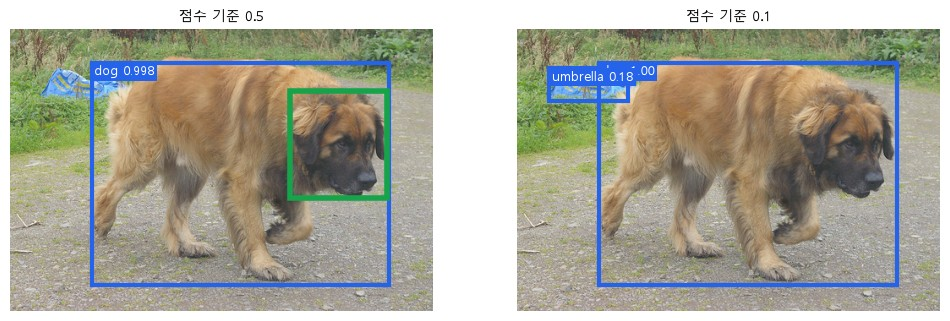

In [21]:
# 왜 · 신뢰도 거르기 → NMS를 한 함수로 이어 사진에서 최종 박스까지 얻기 위해
def detect(img, score_thr=0.5, iou_thr=0.45):           # 사진 → 최종 박스
    with torch.no_grad():                               # 예측만
        cand = raw([det_w.transforms()(img)])[0]        # ① 후보 (NMS 직전)
    print("① 후보       :", len(cand["scores"]))        # 후보 수
    keep = cand["scores"] > score_thr                   # ② 점수로 거르기
    # 남은 것
    boxes, scores, labels = cand["boxes"][keep], cand["scores"][keep], cand["labels"][keep]
    print("② 점수 거른 뒤:", len(scores))               # 남은 수
    keep = batched_nms(boxes, scores, labels, iou_thr)  # ③ 클래스별 NMS
    print("③ NMS 뒤     :", len(keep))                  # 최종 수
    return boxes[keep], scores[keep], labels[keep]      # 최종 박스


# 왜 · 한 함수로 얻은 결과가 모델 출력과 같은지 확인하기 위해
stem = "leonberger_142"                                                           # 레온베르거 개
img = load_image(stem)                                                            # 사진
boxes_f, scores_f, labels_f = detect(img)                                         # 기본 기준
gt_boxes, gt_names = read_voc(XMLS / f"{stem}.xml")                               # 머리 정답
for b, s, lb in zip(boxes_f, scores_f, labels_f):                                 # 최종 예측
    print("예측:", COCO[lb], round(s.item(), 3), [round(v) for v in b.tolist()])  # 몸 박스
print("정답:", gt_names, gt_boxes)                                                # 머리 박스
iou = box_iou(boxes_f, torch.tensor(gt_boxes, dtype=torch.float))                 # 겹침
print("IoU :", [round(v, 2) for v in iou.flatten().tolist()])                     # 낮음

# 왜 · 임곗값을 낮추면 잘못된 박스가 섞이는 것을 보기 위해
boxes_lo, scores_lo, labels_lo = detect(img, score_thr=0.1)           # 점수 기준만 0.1로 낮춤
for s, lb in zip(scores_lo, labels_lo):                               # 최종 예측
    print("최종:", COCO[lb], round(s.item(), 3))                      # 엉뚱한 클래스가 들어옴
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))                     # 두 기준 비교
draw(img, gt=gt_boxes, pred=boxes_f.tolist(), ax=axes[0], title="점수 기준 0.5",  # 기본
     labels=[f"{COCO[lb]} {s:.3f}" for s, lb in zip(scores_f, labels_f)])
draw(img, pred=boxes_lo.tolist(), ax=axes[1], title="점수 기준 0.1",  # 낮춤
     labels=[f"{COCO[lb]} {s:.2f}" for s, lb in zip(scores_lo, labels_lo)])
plt.show()                                                            # 그림 출력

**결과** · 예측 정답은 `1`개 (점수 0.5) · 0.1로 낮추면 `2`개

- `① 후보       : 462` — NMS 직전 후보
- `② 점수 거른 뒤: 9` — 0.5 초과
- `③ NMS 뒤     : 1` — 최종
- `예측: dog 0.998 [96, 39, 448, 302]` — 몸 전체 박스
- `IoU : [0.16]` — 머리 정답과 거의 안 겹침
- `최종: umbrella 0.177` — 기준을 낮추면 엉뚱한 클래스가 들어옴

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>점수 기준 0.5</td><td>적고 확실</td><td>결과 보여 주기</td></tr>
<tr><td>점수 기준 0.1</td><td>많고 엉뚱한 것도</td><td>놓치면 안 될 때</td></tr>
<tr><td>detect 함수</td><td>세 단계를 한 번에</td><td>모델 안에서 하는 일</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 최종 박스가 하나여도 정답과 IoU가 낮으면 '맞혔다'가 아님 → 9장에서 채점

> ✅ **한 줄 정리** · 탐지 결과는 후보 → 점수로 거르기 → 클래스별 NMS 순서로 만들어진다.

**딥러닝 코드에서는**

- torchvision 탐지 모델의 `postprocess_detections`가 이 순서

---
## 6. 후보는 어디서 오나

> **이 장의 흐름**
>
> - 5장의 후보가 생기는 곳
> - 창문마다 CNN → RPN → 디폴트 박스 · 학습 신호

<img src="images/od3_families.png" alt="2단계는 후보 → 판정, 1단계는 칸마다 한 번에" width="763">

**파이프라인 위치** · ④ 모델 구조

### 6-1. `B` R-CNN 방식의 창문 수 · 시간 · `count_windows()` <sub>원본 D1-7 · 셀 111 ~ 116</sub>

> 🎯 **후보(창문)마다 CNN을 따로 돌리면 사진 한 장에 몇 번 계산하는가?**

💡 **쉽게 말하면**

- R-CNN은 **오려 낸 사진 수천 장을 하나씩 감정사에게 보내는 것**.

**실행 흐름**

1. stride 32 · 16 · 8의 창문 수
2. CNN 한 번 시간 × 창문 수

**먼저 예측** · 8픽셀씩 옮기면 창문은 몇 개? — 답은 코드 실행 결과 아래에

In [22]:
from torchvision.models import resnet18  # 시간만 잴 CNN

# 왜 · R-CNN 방식의 창문 수를 실제 사진 크기로 세기 위해
img_a = Image.open(IMAGES / "Abyssinian_140.jpg")  # 고양이 사진
W_img, H_img = img_a.size                          # 사진 크기


# 왜 · 창문 간격에 따라 분류 횟수가 얼마나 늘어나는지 세기 위해
def count_windows(stride):                  # stride 픽셀씩 옮길 때 창문 수
    n = 0                                   # 창문 수
    for size in (64, 128, 256):             # 창문 크기 3가지
        for ratio in (0.5, 1, 2):           # 창문 모양 3가지 (세로 ÷ 가로)
            w, h = int(size / ratio ** 0.5), int(size * ratio ** 0.5)  # 너비 · 높이
            nx = (W_img - w) // stride + 1  # 가로로 놓이는 수
            ny = (H_img - h) // stride + 1  # 세로로 놓이는 수
            n += max(nx, 0) * max(ny, 0)    # 사진보다 크면 0
    return n                                # 전체 창문 수


# 왜 · 간격별 창문 수를 비교하기 위해
print("사진 크기:", img_a.size)                                           # (500, 333)
for stride in (32, 16, 8):                                                # 촘촘할수록
    print(f"{stride:>2}픽셀씩 옮기면 창문 {count_windows(stride):>5}개")  # 창문이 늘어남
count = count_windows(16)                                                 # 16픽셀 기준

# 왜 · 창문 하나 분류 시간을 재어 전체 시간을 어림하기 위해
cnn = resnet18(weights=None).eval()   # 시간만 재는 용도 (학습 안 된 CNN)
crop = torch.rand(1, 3, 224, 224)     # 창문 하나를 잘라 224×224로 맞춘 것
with torch.no_grad():                 # 예측만
    cnn(crop)                         # 첫 실행은 준비 시간이라 빼고 잼
    t = time.perf_counter()           # 시작
    for _ in range(20):               # 20번 평균
        cnn(crop)                     # CNN 한 번
one = (time.perf_counter() - t) / 20  # 한 번 시간
print(f"창문 1개  : {one * 1000:.0f} ms · 창문 {count}개: 약 {one * count:.0f} 초"  # 사진 한 장
      " (컴퓨터마다 다름)")

사진 크기: (500, 333)
32픽셀씩 옮기면 창문   654개
16픽셀씩 옮기면 창문  2496개
 8픽셀씩 옮기면 창문  9733개


창문 1개  : 105 ms · 창문 2496개: 약 263 초 (컴퓨터마다 다름)


**결과** · 예측 정답은 `9733`개

- `32픽셀씩 옮기면 창문   654개` — 듬성듬성
- `16픽셀씩 옮기면 창문  2496개` — 원본 기준
- ` 8픽셀씩 옮기면 창문  9733개` — 촘촘할수록 폭증
- 시간 줄 = CNN 한 번 × 창문 수 (ms 값은 컴퓨터마다 다름)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>R-CNN</td><td>후보마다 CNN</td><td>느림 (역사)</td></tr>
<tr><td>Fast R-CNN</td><td>특징을 한 번 계산 후 공유</td><td>빨라짐</td></tr>
<tr><td>Faster R-CNN</td><td>후보도 RPN이 만듦</td><td>2단계 기본형</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 창문을 촘촘히 할수록 정확하지만 계산이 몇 배씩 늘어남

> ✅ **한 줄 정리** · 후보마다 CNN을 돌리는 방식은 창문 수만큼 계산이 늘어 느리다.

**딥러닝 코드에서는**

- 2단계 탐지기의 발전: R-CNN → Fast → Faster

### 6-2. `A` Faster R-CNN 속 확인 · `fasterrcnn_resnet50_fpn()` · `rpn` <sub>원본 D1-7 · 셀 117 ~ 120</sub>

> 🎯 **Faster R-CNN은 어떤 부품으로 후보를 만들고 판정하는가?**

💡 **쉽게 말하면**

- **후보를 고르는 사람**(RPN)과 **후보마다 판정하는 사람**(RoI Heads)이 따로 있는 2단계.

**실행 흐름**

1. 구조만 불러오기 (가중치 없음)
2. 부품 4개
3. 앵커 크기 · 모양 · 후보 수 · 분류 칸

**먼저 예측** · RPN이 다음 단계로 넘기는 후보는 몇 개? — 답은 코드 실행 결과 아래에

In [23]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn  # 2단계 탐지기

# 왜 · 가중치 없이 구조만 만들어 Faster R-CNN의 부품을 확인하기 위해
frcnn = fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None).eval()  # 구조만 · 가중치 없음
for name, part in frcnn.named_children():                                    # 큰 부품
    print(f"{name:10s} → {type(part).__name__}")                             # 이름 → 종류

# 왜 · RPN이 후보를 만드는 앵커 설정을 직접 보기 위해
gen = frcnn.rpn.anchor_generator                                                      # RPN의 앵커
print("RPN 앵커 크기       :", [s_[0] for s_ in gen.sizes])                           # 크기 5가지
print("RPN 앵커 모양(세로÷가로):", gen.aspect_ratios[0])                              # 모양 3가지
print("RPN이 넘기는 후보 수:", frcnn.rpn.post_nms_top_n())                            # 1000
print("최종 분류 칸 수     :", frcnn.roi_heads.box_predictor.cls_score.out_features)  # 91

transform  → GeneralizedRCNNTransform
backbone   → BackboneWithFPN
rpn        → RegionProposalNetwork
roi_heads  → RoIHeads
RPN 앵커 크기       : [32, 64, 128, 256, 512]
RPN 앵커 모양(세로÷가로): (0.5, 1.0, 2.0)
RPN이 넘기는 후보 수: 1000
최종 분류 칸 수     : 91


**결과** · 예측 정답은 `1000`개

- `rpn        → RegionProposalNetwork` — 1단계: 앵커로 후보
- `roi_heads  → RoIHeads` — 2단계: 후보마다 분류 + 박스 보정
- `RPN 앵커 크기       : [32, 64, 128, 256, 512]` — 크기 5
- `RPN 앵커 모양(세로÷가로): (0.5, 1.0, 2.0)` — 모양 3 → 앵커 15종
- `RPN이 넘기는 후보 수: 1000` — 2단계로 넘기는 후보
- `최종 분류 칸 수     : 91` — COCO 91칸

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>2단계 (two-stage)</td><td>후보 먼저 → 후보마다 판정</td><td>정확 · 느림</td></tr>
<tr><td>1단계 (SSD · YOLO)</td><td>칸마다 한 번에</td><td>빠름</td></tr>
<tr><td>weights=None</td><td>구조만</td><td>모양 · 부품 확인</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 2단계는 후보 수만큼 판정이 반복돼 1단계보다 느림

> ✅ **한 줄 정리** · Faster R-CNN은 RPN이 앵커로 후보를 만들고 RoI Heads가 후보마다 판정하는 2단계 탐지기다.

**딥러닝 코드에서는**

- 객체탐지-2 3-2: `roi_heads.box_predictor`만 바꿔 학습

### 6-3. `A` SSD 구조 · 특징 맵 · 디폴트 박스 · `anchor_generator` <sub>원본 D1-8 · 셀 121 ~ 130</sub>

> 🎯 **SSD는 후보 단계 없이 디폴트 박스를 몇 개 두는가?**

💡 **쉽게 말하면**

- SSD는 **크기가 다른 격자 투명지 6장**을 겹쳐 놓고 칸마다 미리 그린 박스(디폴트 박스)를 둠.

**실행 흐름**

1. 부품 4개
2. 300×300 가짜 입력 → 특징 맵 6장
3. 칸 수 × 칸마다 박스 수

**먼저 예측** · SSD300의 디폴트 박스는 모두 몇 개? — 답은 코드 실행 결과 아래에

In [24]:
# 왜 · SSD 구조를 실제 모델에서 열어 보기 위해
SSD_W = SSD300_VGG16_Weights.COCO_V1              # COCO로 학습된 가중치
ssd = ssd300_vgg16(weights=SSD_W).eval()          # 4장까지의 detector와 같은 모델
categories = SSD_W.meta["categories"]             # 91칸 이름
for name, part in ssd.named_children():           # 큰 부품
    print(f"{name:17s} → {type(part).__name__}")  # 이름 → 종류

# 왜 · 특징 맵 6장의 크기를 모양만으로 확인하기 위해
xr = torch.rand(1, 3, 300, 300)                # 300×300 가짜 이미지 한 장
with torch.no_grad():                          # 모양만 확인
    feats = ssd.backbone(xr)                   # 특징 맵 여러 장
for k, f in feats.items():                     # 맵마다
    _, c, h, w = f.shape                       # 채널 · 크기
    print(f"맵 {k}: {h:>2}×{w:<2}  채널 {c}")  # 38 · 19 · 10 · 5 · 3 · 1

# 왜 · 디폴트 박스가 모두 몇 개인지 손으로 세어 보기 위해
per_cell = ssd.anchor_generator.num_anchors_per_location()    # 칸마다 디폴트 박스 수
total = 0                                                     # 전체 디폴트 박스
for f, a in zip(feats.values(), per_cell):                    # 맵마다
    h, w = f.shape[-2:]                                       # 맵 크기
    print(f"{h:>2}×{w:<2} 칸 × 박스 {a}개 = {h * w * a:>5}")  # 맵별 박스 수
    total += h * w * a                                        # 더하기
print("디폴트 박스 전체:", total)                             # 8732

backbone          → SSDFeatureExtractorVGG
anchor_generator  → DefaultBoxGenerator
head              → SSDHead
transform         → GeneralizedRCNNTransform


맵 0: 38×38  채널 512
맵 1: 19×19  채널 1024
맵 2: 10×10  채널 512
맵 3:  5×5   채널 256
맵 4:  3×3   채널 256
맵 5:  1×1   채널 256
38×38 칸 × 박스 4개 =  5776
19×19 칸 × 박스 6개 =  2166
10×10 칸 × 박스 6개 =   600
 5×5  칸 × 박스 6개 =   150
 3×3  칸 × 박스 4개 =    36
 1×1  칸 × 박스 4개 =     4
디폴트 박스 전체: 8732


**결과** · 예측 정답은 `8732`개

- `맵 0: 38×38  채널 512` — 가장 촘촘 · 작은 물체
- `맵 5:  1×1   채널 256` — 가장 거침 · 큰 물체
- `38×38 칸 × 박스 4개 =  5776` — 가장 많음
- `디폴트 박스 전체: 8732` — 5776 + 2166 + 600 + 150 + 36 + 4 = 8732

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>디폴트 박스 (SSD)</td><td>칸마다 미리 정한 박스</td><td>1단계 · 앵커</td></tr>
<tr><td>RPN 앵커 (Faster)</td><td>후보를 만드는 출발점</td><td>2단계</td></tr>
<tr><td>앵커 없음 (YOLO11)</td><td>칸 중심에서 거리</td><td>8장</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 작은 물체 담당(38×38)은 얕은 특징 → 작은 물체에 약한 편

> ✅ **한 줄 정리** · SSD는 크기가 다른 특징 맵 6장의 칸마다 디폴트 박스를 두며, 모두 8732개다.

**딥러닝 코드에서는**

- `model.anchor_generator.num_anchors_per_location()`

### 6-4. `A` 디폴트 박스마다 나오는 것 · `classification_head` · `regression_head` <sub>원본 D1-8 · 셀 131 ~ 134</sub>

> 🎯 **디폴트 박스 하나마다 모델은 무엇을 내는가?**

💡 **쉽게 말하면**

- 박스마다 **91칸 클래스 점수**와 **위치 보정 4개**.
- 분류 층 출력 채널 = 박스 수 × 클래스 수.

**실행 흐름**

1. 맵마다 분류 · 위치 층 채널
2. 클래스 수
3. 헤드 출력 모양

**먼저 예측** · 첫 맵의 분류 층 출력 채널은? — 답은 코드 실행 결과 아래에

In [25]:
# 왜 · 디폴트 박스마다 클래스 점수와 박스 보정값이 나온다는 것을 확인하기 위해
cls_head = ssd.head.classification_head                                    # 클래스 점수 층
box_head = ssd.head.regression_head                                        # 위치 보정 층
for c, r, a in zip(cls_head.module_list, box_head.module_list, per_cell):  # 맵마다
    # 분류
    print(f"박스 {a}개 · 분류 Conv2d({c.in_channels}→{c.out_channels}) = {a}×{c.out_channels // a}"
          f" · 위치 Conv2d({r.in_channels}→{r.out_channels}) = {a}×4")
print("클래스 수:", len(categories), categories[:3])                       # 91

with torch.no_grad():                                                 # 모양만 확인
    head_out = ssd.head(list(feats.values()))                         # 8732개 박스의 점수 · 보정값
print("클래스 점수 모양:", tuple(head_out["cls_logits"].shape))       # (1, 8732, 91)
print("위치 보정 모양  :", tuple(head_out["bbox_regression"].shape))  # (1, 8732, 4)

박스 4개 · 분류 Conv2d(512→364) = 4×91 · 위치 Conv2d(512→16) = 4×4
박스 6개 · 분류 Conv2d(1024→546) = 6×91 · 위치 Conv2d(1024→24) = 6×4
박스 6개 · 분류 Conv2d(512→546) = 6×91 · 위치 Conv2d(512→24) = 6×4
박스 6개 · 분류 Conv2d(256→546) = 6×91 · 위치 Conv2d(256→24) = 6×4
박스 4개 · 분류 Conv2d(256→364) = 4×91 · 위치 Conv2d(256→16) = 4×4
박스 4개 · 분류 Conv2d(256→364) = 4×91 · 위치 Conv2d(256→16) = 4×4
클래스 수: 91 ['__background__', 'person', 'bicycle']
클래스 점수 모양: (1, 8732, 91)
위치 보정 모양  : (1, 8732, 4)


**결과** · 예측 정답은 `364` = 4 × 91

- `박스 4개 · 분류 Conv2d(512→364) = 4×91 · 위치 Conv2d(512→16) = 4×4` — 첫 맵
- `클래스 점수 모양: (1, 8732, 91)` — 박스마다 91칸
- `위치 보정 모양  : (1, 8732, 4)` — 박스마다 보정 4개

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>분류 헤드</td><td>박스 수 × 클래스 수 채널</td><td>헤드 교체 대상 (객체탐지-2 3-1)</td></tr>
<tr><td>위치 헤드</td><td>박스 수 × 4 채널</td><td>클래스와 무관</td></tr>
<tr><td>우리 미션</td><td>91칸 → 3칸</td><td>분류 헤드만 바꿈</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 클래스 수는 층의 출력 채널에 들어감 → 숫자 속성만 바꾸면 안 됨

> ✅ **한 줄 정리** · SSD는 디폴트 박스마다 클래스 점수와 위치 보정값을 한 번에 내며, 클래스 수는 분류 층 채널에 들어간다.

**딥러닝 코드에서는**

- `SSDClassificationHead(in_channels, num_anchors, num_classes)`

### 6-5. `B` 실제 사진: 출발점에서 보정까지 · `box_coder.decode_single()` <sub>원본 D1-8 · 셀 135 ~ 139</sub>

> 🎯 **디폴트 박스(출발점)는 보정을 거쳐 어디로 움직이는가?**

💡 **쉽게 말하면**

- 디폴트 박스는 **출발점**, 위치 보정값은 **얼마나 옮길지**.
- 8732개 중 대부분은 배경이 1등.

**실행 흐름**

1. 300×300으로 맞추기 · 특징 맵 · 헤드
2. 디폴트 박스 좌표 · 보정 적용
3. 고양이 · 개 사진

**먼저 예측** · 8732개 중 배경이 1등인 박스는? — 답은 코드 실행 결과 아래에

In [26]:
from torchvision.io import decode_image  # 파일 → uint8 텐서


# 왜 · 디폴트 박스가 보정값으로 최종 박스가 되는 과정을 보기 위해
def start_to_fixed(stem, name):  # 디폴트 박스(출발점)에서 보정 후 박스까지
    img_t = SSD_W.transforms()(decode_image(str(IMAGES / f"{stem}.jpg")))  # 0~1 텐서
    with torch.no_grad():                                       # 예측만
        image_list, _ = ssd.transform([img_t])                  # 300×300으로 맞춤
        maps = list(ssd.backbone(image_list.tensors).values())  # 특징 맵
        raw_out = ssd.head(maps)                                # 8732개 박스의 점수 · 보정값
        anchors = ssd.anchor_generator(image_list, maps)[0]     # 디폴트 박스 좌표 (300 기준)
        fixed = ssd.box_coder.decode_single(raw_out["bbox_regression"][0], anchors)  # 보정 적용
    probs = raw_out["cls_logits"][0].softmax(-1)                # 박스마다 91칸 확률
    score = probs[:, categories.index(name)]                    # 그 클래스 점수
    # 대부분 배경
    print(f"[{stem}] 배경이 1등인 박스: {int((probs.argmax(-1) == 0).sum())} / {len(probs)}"
          f" · {name} 점수 > 0.5 박스: {int((score > 0.5).sum())}")
    for i in score.topk(3).indices.tolist():                    # 점수 상위 3개
        # 출발 → 보정
        print(f"  {name} {score[i]:.2f}  출발 {[round(v) for v in anchors[i].tolist()]}"
              f" → 보정 후 {[round(v) for v in fixed[i].tolist()]}")
    return anchors, fixed, score                                # 아래에서 씀


# 왜 · 고양이 · 개 사진에서 출발 박스와 보정된 박스를 비교하기 위해
anchors, fixed_cat, cat_score = start_to_fixed("Abyssinian_140", "cat")  # 고양이
_ = start_to_fixed("chihuahua_138", "dog")                               # 두 번째 사진: 개

[Abyssinian_140] 배경이 1등인 박스: 8725 / 8732 · cat 점수 > 0.5 박스: 6
  cat 0.99  출발 [20, 84, 172, 236] → 보정 후 [5, 65, 195, 243]
  cat 0.99  출발 [7, 71, 185, 249] → 보정 후 [5, 61, 197, 248]
  cat 0.95  출발 [-12, 106, 204, 214] → 보정 후 [13, 70, 197, 243]


[chihuahua_138] 배경이 1등인 박스: 8723 / 8732 · dog 점수 > 0.5 박스: 8
  dog 0.98  출발 [84, 84, 236, 236] → 보정 후 [79, 63, 249, 250]
  dog 0.97  출발 [71, 71, 249, 249] → 보정 후 [78, 66, 256, 251]
  dog 0.96  출발 [106, 52, 214, 268] → 보정 후 [80, 61, 247, 245]


**결과** · 예측 정답은 `8725` / 8732 (고양이 사진)

- `[Abyssinian_140] 배경이 1등인 박스: 8725 / 8732 · cat 점수 > 0.5 박스: 6` — 대부분 배경
- `cat 0.99  출발 [20, 84, 172, 236] → 보정 후 [5, 65, 195, 243]` — 출발점에서 몸 전체로 옮김
- `[chihuahua_138] 배경이 1등인 박스: 8723 / 8732 · dog 점수 > 0.5 박스: 8` — 개 사진도 같음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>디폴트 박스</td><td>고정된 출발점</td><td>모든 사진 공통</td></tr>
<tr><td>위치 보정값</td><td>사진마다 다름</td><td>학습되는 값</td></tr>
<tr><td>배경 클래스</td><td>대부분의 박스</td><td>0번 칸</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 좌표가 음수(-12)인 출발점도 있음 → 보정 후 사진 안으로

> ✅ **한 줄 정리** · SSD의 최종 박스는 디폴트 박스에 위치 보정값을 적용한 것이며, 대부분의 박스는 배경으로 판정된다.

**딥러닝 코드에서는**

- `box_coder.decode_single(regression, anchors)`

### 6-6. `B` 학습 때 짝짓기 · 디폴트 박스와 정답 · `box_iou(gt, anchors)` <sub>원본 D1-8 · 셀 140 ~ 147</sub>

> 🎯 **학습 때 정답 머리 박스와 짝지어지는 디폴트 박스는 몇 개인가?**

💡 **쉽게 말하면**

- 학습 때는 정답과 **IoU 0.5 이상인 디폴트 박스**를 양성으로 짝지음.
- 작은 얼굴은 짝이 없을 수도 있음.

**실행 흐름**

1. 사진 3장 양성 수 · 맵
2. 양성 박스의 COCO cat 점수
3. 정답 3686개 전체 통계

**먼저 예측** · basset_hound_131의 양성 디폴트 박스는? — 답은 코드 실행 결과 아래에

In [27]:
# 왜 · 정답 박스를 300×300 기준으로 바꿔 디폴트 박스와 비교하기 위해
def read_gt(stem):  # 첫 정답 박스 · 사진 크기
    root = ET.parse(XMLS / f"{stem}.xml").getroot()                                  # XML
    w, h = int(root.findtext("size/width")), int(root.findtext("size/height"))       # 크기
    bnd = root.find("object/bndbox")                                                 # 첫 박스
    return [float(bnd.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")], w, h  # 박스 · 크기


# 왜 · 학습 때 디폴트 박스와 정답을 IoU로 짝짓는 규칙을 직접 해 보기 위해
def match_anchors(stem):                                   # 정답과 IoU 0.5 이상인 디폴트 박스
    (x1, y1, x2, y2), w, h = read_gt(stem)                 # 정답
    g = torch.tensor([[x1 * 300 / w, y1 * 300 / h, x2 * 300 / w, y2 * 300 / h]])  # 300 기준 정답
    iou = box_iou(g, anchors)[0]                           # 디폴트 박스 8732개와 IoU
    return int((iou >= 0.5).sum()), float(iou.max()), iou  # 양성 수 · 최고 · 전체


# 왜 · 짝지어진 디폴트 박스가 어느 특징 맵에서 왔는지 알기 위해
map_of = torch.cat([torch.full((f.shape[-1] ** 2 * a,), f.shape[-1])  # 박스마다 어느 맵 출신인지
                    for f, a in zip(feats.values(), per_cell)])
for stem in ["Abyssinian_140", "boxer_123", "basset_hound_131"]:      # 세 사진
    n, best, iou = match_anchors(stem)                                # 짝
    used = sorted(set(map_of[iou >= 0.5].tolist()), reverse=True)     # 짝이 나온 맵
    print(f"{stem:17s} IoU≥0.5 디폴트 박스 {n:2d}개 · 맵 {used} · 최고 IoU {best:.3f}")  # 결과

# 왜 · 정답 하나에 짝지어진 디폴트 박스 수를 세기 위해
n, _, iou = match_anchors("Abyssinian_140")                                          # 고양이 머리
positive = iou >= 0.5  # 머리 정답과 짝지어진 디폴트 박스
top = int(cat_score.argmax())  # COCO 모델이 cat 점수를 가장 높게 준 박스
(x1, y1, x2, y2), w, h = read_gt("Abyssinian_140")                                   # 정답
head_box = torch.tensor([[x1 * 300 / w, y1 * 300 / h, x2 * 300 / w, y2 * 300 / h]])  # 300 기준
print(f"양성 박스 {n}개의 cat 점수: 가장 높아도 {cat_score[positive].max():.3f}")    # 낮음
print(f"cat 점수 1등 박스: {cat_score[top]:.2f} · 보정 후 박스와 머리 정답의 IoU"    # 몸 박스
      f" {box_iou(fixed_cat[top:top + 1], head_box).item():.2f}")

# 왜 · 전체 XML에서 짝 수와 특징 맵 분포를 보기 위해
stems = [p.stem for p in sorted(XMLS.glob("*.xml"))]  # 정답 전부
counts, best_maps = [], []                            # 정답마다 양성 수 · 가장 잘 맞는 맵
for st in stems:                                      # 3686개
    n, _, iou = match_anchors(st)                     # 짝
    counts.append(n)                                  # 양성 수
    best_maps.append(int(map_of[iou.argmax()]))       # 가장 잘 맞는 박스의 맵
print("정답 박스 수        :", len(counts))           # 3686
print("가장 잘 맞는 박스의 맵:", {m: best_maps.count(m) for m in (38, 19, 10, 5, 3, 1)})  # 맵별
# 분포
print("양성 디폴트 박스 수 : 가운데값", sorted(counts)[len(counts) // 2], "· 최대", max(counts))
print("0.5 넘는 박스 0개   :", sum(c == 0 for c in counts), "개")  # 짝이 없는 정답

Abyssinian_140    IoU≥0.5 디폴트 박스  6개 · 맵 [19] · 최고 IoU 0.719
boxer_123         IoU≥0.5 디폴트 박스  3개 · 맵 [38] · 최고 IoU 0.565
basset_hound_131  IoU≥0.5 디폴트 박스  0개 · 맵 [] · 최고 IoU 0.499
양성 박스 6개의 cat 점수: 가장 높아도 0.026
cat 점수 1등 박스: 0.99 · 보정 후 박스와 머리 정답의 IoU 0.10


정답 박스 수        : 3686
가장 잘 맞는 박스의 맵: {38: 18, 19: 707, 10: 1654, 5: 867, 3: 275, 1: 165}
양성 디폴트 박스 수 : 가운데값 9 · 최대 21
0.5 넘는 박스 0개   : 9 개


**결과** · 예측 정답은 `0`개 — 최고 IoU 0.499

- `Abyssinian_140    IoU≥0.5 디폴트 박스  6개 · 맵 [19] · 최고 IoU 0.719` — 19×19 맵에서 짝
- `basset_hound_131  IoU≥0.5 디폴트 박스  0개 · 맵 [] · 최고 IoU 0.499` — 아슬아슬하게 없음
- `양성 박스 6개의 cat 점수: 가장 높아도 0.026` — COCO 모델은 머리 자리에 cat을 안 줌
- `cat 점수 1등 박스: 0.99 · 보정 후 박스와 머리 정답의 IoU 0.10` — 몸 박스라 머리와 안 겹침
- `가장 잘 맞는 박스의 맵: {38: 18, 19: 707, 10: 1654, 5: 867, 3: 275, 1: 165}` — 10×10 맵이 가장 많음
- `0.5 넘는 박스 0개   : 9 개` — 짝 없는 정답 9개 → 정답마다 최고 1개를 양성으로 추가

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>IoU ≥ 0.5</td><td>양성</td><td>학습 매칭</td></tr>
<tr><td>정답마다 최고 1개</td><td>짝이 없을 때 보충</td><td>작은 물체</td></tr>
<tr><td>나머지</td><td>음성 (배경)</td><td>hard negative mining 3 : 1</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 학습 매칭 IoU(디폴트 박스 ↔ 정답)와 평가 IoU(예측 ↔ 정답)는 다른 기준

> ✅ **한 줄 정리** · SSD 학습은 정답과 IoU 0.5 이상인 디폴트 박스를 양성으로 짝짓고, 짝이 없으면 가장 잘 맞는 하나를 쓴다.

**딥러닝 코드에서는**

- 객체탐지-2에서 우리 머리 정답으로 이 짝짓기를 다시 학습

### 6-7. `B` 학습 신호 두 가지 · `ssd.train()` <sub>원본 D1-8 · 셀 148 ~ 150</sub>

> 🎯 **학습 모드에서 SSD는 무엇을 돌려주는가?**

💡 **쉽게 말하면**

- 학습 모드는 박스 대신 **손실 두 가지**를 줌.
- 위치 손실(smooth L1) + 분류 손실(cross-entropy).

**실행 흐름**

1. 정답 target 만들기 (COCO cat 번호)
2. 학습 모드 → 손실 dict
3. 평가 모드로 되돌리기

**먼저 예측** · 학습 모드의 반환값은 박스일까? — 답은 코드 실행 결과 아래에

In [28]:
# 왜 · 학습 모드 SSD가 내는 두 가지 손실을 확인하기 위해
box_gt, w, h = read_gt("Abyssinian_140")                        # 첫 정답
img_t = SSD_W.transforms()(decode_image(str(IMAGES / "Abyssinian_140.jpg")))  # 사진 텐서
target = [{"boxes": torch.tensor([box_gt]),                     # 정답 박스
           "labels": torch.tensor([categories.index("cat")])}]  # COCO의 cat 번호
ssd.train()                                                     # 학습 모드: 박스 대신 손실을 돌려줌
losses = ssd([img_t], target)                                   # 손실 두 가지
ssd.eval()                                                      # 다시 평가 모드
print({k: round(v.item(), 3) for k, v in losses.items()})       # 위치 · 분류 손실

{'bbox_regression': 1.386, 'classification': 8.639}


**결과** · 예측 정답은 아님 — 손실 dict

- `{'bbox_regression': 1.386, 'classification': 8.639}` — 몸 박스를 배운 모델에 머리 정답 → 손실이 큼

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>eval 모드</td><td>예측 dict 목록</td><td>추론</td></tr>
<tr><td>train 모드 + target</td><td>손실 dict</td><td>학습</td></tr>
<tr><td>분류 손실</td><td>hard negative mining 3 : 1</td><td>배경이 너무 많아서</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 학습 뒤 `eval()`로 되돌리지 않으면 예측 대신 에러 (객체탐지-2 4-2)

> ✅ **한 줄 정리** · SSD는 학습 모드에서 위치 손실과 분류 손실 두 가지를 돌려준다.

**딥러닝 코드에서는**

- `loss = sum(model(images, targets).values())` → backward

---
## 7. Oxford 탐지 데이터 계약

> **이 장의 흐름**
>
> - 6장의 학습 신호에 넣을 정답
> - 목록 · XML 점검 · 크기 · target · 약속 어기기

<img src="images/pfo1_target.png" alt="한 샘플 = 이미지 텐서 + target 딕셔너리" width="763">

**파이프라인 위치** · ① 데이터 준비 · ② 불러오기

### 7-1. `A` 사진 목록 세 개 · 정답 XML은 어디에 · `read_list()` <sub>원본 D1-9 · 셀 151 ~ 156</sub>

> 🎯 **목록 파일 세 개는 어떤 관계이고, 정답 XML은 어느 목록에 있는가?**

💡 **쉽게 말하면**

- list = trainval + test.
- 그런데 **머리 박스 XML은 trainval에만** 있음.

**실행 흐름**

1. list · trainval · test 수 · 겹침
2. XML 전체 수
3. 목록마다 XML 있는 수

**먼저 예측** · 공식 test 목록 중 XML이 있는 사진은? — 답은 코드 실행 결과 아래에

In [29]:
# 왜 · 목록 파일에서 사진 이름만 꺼내기 위해
def read_list(name):  # 한 줄 예: "Abyssinian_100 1 1 1" → 앞 이름만
    return [line.split()[0] for line in open(ANN / name)  # 줄마다 첫 칸
            if line.strip() and not line.startswith("#")]


# 왜 · 목록 세 개의 사진 수와 겹침을 확인하기 위해
all_stems = read_list("list.txt")               # 전체 목록
trainval = read_list("trainval.txt")            # 학습 · 검증 목록
test = read_list("test.txt")                    # 공식 test 목록
print("list.txt     :", len(all_stems))         # 7349
print("trainval.txt :", len(trainval))          # 3680
print("test.txt     :", len(test))              # 3669
print("겹침:", len(set(trainval) & set(test)),  # 0
      "· 합치면 list와 같음:", set(trainval) | set(test) == set(all_stems))

# 왜 · 정답 XML이 어느 목록의 사진에 있는지 확인하기 위해
xml_stems = {p.stem for p in XMLS.glob("*.xml")}  # 정답 XML이 있는 이름
print("XML 파일 전체      :", len(xml_stems))     # 3686
# 대부분
print("trainval 중 XML 있음:", sum(s_ in xml_stems for s_ in trainval), "/", len(trainval))
print("test 중 XML 있음    :", sum(s_ in xml_stems for s_ in test), "/", len(test))  # 0

list.txt     : 7349
trainval.txt : 3680
test.txt     : 3669
겹침: 0 · 합치면 list와 같음: True
XML 파일 전체      : 3686
trainval 중 XML 있음: 3671 / 3680
test 중 XML 있음    : 0 / 3669


**결과** · 예측 정답은 `0` / 3669

- `list.txt     : 7349` — 전체
- `겹침: 0 · 합치면 list와 같음: True` — trainval + test = list
- `trainval 중 XML 있음: 3671 / 3680` — 9장은 XML 없음
- `test 중 XML 있음    : 0 / 3669` — 공식 test로는 채점 불가

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>list.txt</td><td>전체 7349장</td><td>품종 · 종류 정보</td></tr>
<tr><td>trainval.txt</td><td>XML 대부분 있음</td><td>학습 · 검증 · 채점용 분할</td></tr>
<tr><td>test.txt</td><td>XML 없음</td><td>탐지 채점에 못 씀</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 채점용 사진은 trainval에서 따로 떼어야 함 (객체탐지-2 1-1)

> ✅ **한 줄 정리** · 공식 test에는 머리 박스 정답이 없으므로 탐지 평가는 trainval 안에서 나눠서 한다.

**딥러닝 코드에서는**

- `train_test_split(trainval_with_xml, stratify=품종)`

### 7-2. `A` XML 전체 읽기 · 박스 점검 · `Counter()` <sub>원본 D1-9 · 셀 157 ~ 162</sub>

> 🎯 **학습 전에 정답 박스를 어떻게 점검하는가?**

💡 **쉽게 말하면**

- **택배를 뜯기 전에 송장과 내용물 대조**.
- 사진 밖 · 순서 뒤집힘 · 이름 수 · 박스 개수를 셈.

**실행 흐름**

1. XML 3686개 읽기
2. 점검 3가지
3. 이름별 · 사진당 박스 수
4. 규칙과 다른 XML · 박스 2개 사진

**먼저 예측** · 박스가 2개인 사진은 몇 장? — 답은 코드 실행 결과 아래에

XML 3686 개 · 박스 3687 개
{'이미지 밖으로 나감': 0, 'xmin ≥ xmax': 0, 'ymin ≥ ymax': 0}
XML 안 이름 : {'cat': 1189, 'dog': 2498}
사진당 박스 : {1: 3685, 2: 1}
규칙과 다른 XML: 0
['Bengal_105'] · 크기: 500 × 466
cat [49.0, 125.0, 111.0, 168.0]
cat [397.0, 103.0, 451.0, 132.0]


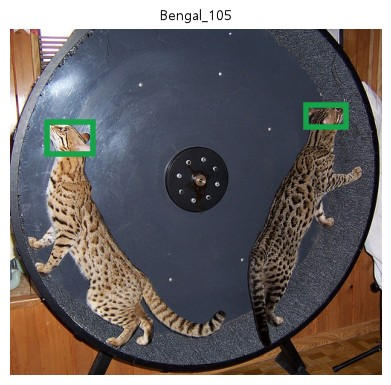

In [30]:
from collections import Counter  # 개수 세기

# 왜 · 모든 XML을 한 번에 읽어 점검에 쓰기 위해
records = {}                         # 이름 → (폭, 높이, 박스들, 이름들)
for st in sorted(xml_stems):         # XML 전부
    path = XMLS / f"{st}.xml"        # 경로
    root = ET.parse(path).getroot()  # XML
    w, h = int(root.findtext("size/width")), int(root.findtext("size/height"))  # 크기
    bxs, nms_ = read_voc(path)       # 박스 · 이름
    records[st] = (w, h, bxs, nms_)  # 기록

# 왜 · 잘못된 박스가 학습에 들어가지 않게 미리 세어 보기 위해
problems = {"이미지 밖으로 나감": 0, "xmin ≥ xmax": 0, "ymin ≥ ymax": 0}          # 점검 3가지
n_boxes = 0                                                                       # 박스 수
for w, h, bxs, _ in records.values():                                             # 사진마다
    for x1, y1, x2, y2 in bxs:                                                    # 박스마다
        n_boxes += 1                                                              # 세기
        problems["이미지 밖으로 나감"] += (x1 < 0 or y1 < 0 or x2 > w or y2 > h)  # 사진 밖
        problems["xmin ≥ xmax"] += (x1 >= x2)                                     # 가로 순서
        problems["ymin ≥ ymax"] += (y1 >= y2)                                     # 세로 순서
print("XML", len(records), "개 · 박스", n_boxes, "개")                            # 3686 · 3687
print(problems)                                                                   # 모두 0

# 왜 · 클래스 균형과 사진당 박스 수를 확인하기 위해
name_count = Counter(n for _, _, _, ns in records.values() for n in ns)  # 이름별 박스 수
box_per_image = Counter(len(bxs) for _, _, bxs, _ in records.values())   # 사진당 박스 수
print("XML 안 이름 :", dict(name_count))                                 # cat · dog
print("사진당 박스 :", dict(box_per_image))                              # 1개 · 2개
mismatch = [st for st, (_, _, _, ns) in records.items()                  # 파일명 규칙과 다른 XML
            if any((n == "cat") != st[0].isupper() for n in ns)]
print("규칙과 다른 XML:", len(mismatch))                                 # 0

# 왜 · 박스가 둘인 사진을 직접 보고 정답이 맞는지 확인하기 위해
two = [st for st, (_, _, bxs, _) in records.items() if len(bxs) > 1]  # 박스 2개인 사진
w, h, bxs, ns = records[two[0]]                                       # 그 사진
print(two, "· 크기:", w, "×", h)                                      # Bengal_105
for bx, n in zip(bxs, ns):                                            # 박스마다
    print(n, bx)                                                      # 두 고양이
draw(load_image(two[0]), gt=bxs, title=two[0])                        # 그림
plt.show()                                                            # 그림 출력

**결과** · 예측 정답은 `1`장 — Bengal_105

- `XML 3686 개 · 박스 3687 개` — 박스 2개 사진이 하나
- `{'이미지 밖으로 나감': 0, 'xmin ≥ xmax': 0, 'ymin ≥ ymax': 0}` — 점검 3가지 통과
- `XML 안 이름 : {'cat': 1189, 'dog': 2498}` — 개가 고양이의 2배 넘음
- `사진당 박스 : {1: 3685, 2: 1}` — 거의 한 마리
- `['Bengal_105'] · 크기: 500 × 466` — 고양이 두 마리

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>사진 밖</td><td>x2 &gt; W 등</td><td>좌표 오류</td></tr>
<tr><td>xmin ≥ xmax</td><td>순서 뒤집힘</td><td>뒤집기 실수 (3-4)</td></tr>
<tr><td>이름 개수</td><td>클래스 불균형</td><td>클래스별 AP 확인</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 점검 없이 학습하면 박스 하나 때문에 손실이 nan이 되거나 중간에 에러

> ✅ **한 줄 정리** · 학습 전에 박스 범위 · 순서 · 클래스 개수를 한 번 전부 점검한다.

**딥러닝 코드에서는**

- `assert (boxes[:, 2] > boxes[:, 0]).all()`

### 7-3. `B` 사진 크기 · 얼굴 크기 · `statistics.median()` <sub>원본 D1-9 · 셀 163 ~ 165</sub>

> 🎯 **사진 크기와 300×300 기준 얼굴 크기는 얼마나 다양한가?**

💡 **쉽게 말하면**

- 사진 크기가 **706가지**로 제각각.
- 300×300으로 바꾸면 얼굴 긴 변이 20 ~ 299로 퍼짐.

**실행 흐름**

1. 사진 폭 · 높이 범위
2. 서로 다른 크기 수
3. 300 기준 얼굴 긴 변

**먼저 예측** · 300 기준 얼굴 긴 변의 가운데값은? — 답은 코드 실행 결과 아래에

In [31]:
import statistics  # 가운데값

# 왜 · 사진 크기가 제각각이라는 것을 숫자로 확인하기 위해
sizes = [(w, h) for w, h, _, _ in records.values()]                           # 사진 크기들
print("사진 폭  :", min(w for w, _ in sizes), "~", max(w for w, _ in sizes))  # 최소 ~ 최대
print("사진 높이:", min(h for _, h in sizes), "~", max(h for _, h in sizes))  # 최소 ~ 최대
print("서로 다른 크기:", len(set(sizes)), "가지")                             # 크기가 제각각

# 왜 · 얼굴 크기 분포를 보고 작은 물체가 얼마나 있는지 알기 위해
side = []  # SSD 안에서 300×300으로 바뀐 뒤 얼굴 박스의 긴 변
for w, h, bxs, _ in records.values():                               # 사진마다
    for x1, y1, x2, y2 in bxs:                                      # 박스마다
        side.append(max((x2 - x1) / w * 300, (y2 - y1) / h * 300))  # 긴 변
side.sort()                                                         # 작은 순
print("300 기준 얼굴 긴 변: 가장 작은", round(side[0]),             # 최소 · 가운데 · 최대
      "· 가운데", round(statistics.median(side)), "· 가장 큰", round(side[-1]))
print("긴 변 50 미만:", sum(v < 50 for v in side), "/", len(side))  # 아주 작은 얼굴

사진 폭  : 114 ~ 3264
사진 높이: 108 ~ 2606
서로 다른 크기: 706 가지
300 기준 얼굴 긴 변: 가장 작은 20 · 가운데 141 · 가장 큰 299
긴 변 50 미만: 41 / 3687


**결과** · 예측 정답은 `141`

- `서로 다른 크기: 706 가지` — 미리 같은 크기로 맞춰져 있지 않음
- `300 기준 얼굴 긴 변: 가장 작은 20 · 가운데 141 · 가장 큰 299` — 작은 얼굴부터 큰 얼굴까지
- `긴 변 50 미만: 41 / 3687` — 아주 작은 얼굴 41개

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>사진 크기 제각각</td><td>기본 묶기 실패</td><td>collate_fn (객체탐지-2 1-3)</td></tr>
<tr><td>작은 얼굴</td><td>IoU · AP가 낮음</td><td>크기별 분석</td></tr>
<tr><td>300×300</td><td>SSD 입력</td><td>얼굴 크기 기준</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 가로 · 세로 배율이 달라 얼굴 모양도 늘어나거나 눌림

> ✅ **한 줄 정리** · 사진 크기가 제각각이라 묶을 때 주의하고, 300 기준으로 아주 작은 얼굴도 있다.

**딥러닝 코드에서는**

- 객체탐지-2 6-2: 얼굴 크기 구간별 찾은 비율

### 7-4. `A` 한 샘플 = 이미지 + target · `make_target()` · `TF.to_tensor()` <sub>원본 D1-9 · 셀 166 ~ 169</sub>

> 🎯 **모델에 먹일 한 샘플은 어떤 모양 · 자료형이어야 하는가?**

💡 **쉽게 말하면**

- 한 샘플은 **사진 + 정답 봉투**.
- 봉투에 boxes(실수 [N, 4])와 labels(정수 [N]), 0은 배경.

**실행 흐름**

1. 이름 → 번호 (0 = 배경)
2. make_target · 모양 · 자료형
3. 박스 2개 사진
4. 이미지 텐서

**먼저 예측** · labels의 자료형은? — 답은 코드 실행 결과 아래에

In [32]:
import torchvision.transforms.functional as TF  # PIL → 텐서

# 왜 · torchvision 탐지 모델이 0번을 배경으로 쓰기 때문에
CLASSES = ["배경", "고양이 얼굴", "개 얼굴"]  # 번호 0, 1, 2
NAME_TO_LABEL = {"cat": 1, "dog": 2}          # 0은 배경 자리 → XML에는 없음


# 왜 · 탐지 모델이 요구하는 boxes · labels 형식으로 맞추기 위해
def make_target(stem):                                        # XML → 모델이 받는 정답
    bxs, ns = read_voc(XMLS / f"{stem}.xml")                  # 박스 · 이름
    return {"boxes": torch.tensor(bxs, dtype=torch.float32),  # [N, 4] xyxy
            "labels": torch.tensor([NAME_TO_LABEL[n] for n in ns], dtype=torch.int64)}  # [N]


# 왜 · target의 모양 · 자료형이 약속과 맞는지 확인하기 위해
t = make_target("Abyssinian_173")                              # 한 샘플의 정답
print(t)                                                       # boxes · labels
print("boxes :", tuple(t["boxes"].shape), t["boxes"].dtype)    # (1, 4) float32
print("labels:", tuple(t["labels"].shape), t["labels"].dtype)  # (1,) int64
# (2, 4)
print("두 박스 사진:", tuple(make_target(two[0])["boxes"].shape), make_target(two[0])["labels"])

# 왜 · 이미지 텐서의 모양 · 범위가 약속과 맞는지 확인하기 위해
image = TF.to_tensor(load_image("Abyssinian_173"))  # [3, H, W], 0~1 실수
print("image:", tuple(image.shape), image.dtype,    # 모양 · 자료형 · 범위
      round(image.min().item(), 2), "~", round(image.max().item(), 2))

{'boxes': tensor([[241.,  31., 310., 102.]]), 'labels': tensor([1])}
boxes : (1, 4) torch.float32
labels: (1,) torch.int64
두 박스 사진: (2, 4) tensor([1, 1])
image: (3, 267, 400) torch.float32 0.0 ~ 1.0


**결과** · 예측 정답은 `torch.int64`

- `boxes : (1, 4) torch.float32` — [N, 4] 실수
- `labels: (1,) torch.int64` — [N] 정수
- `두 박스 사진: (2, 4) tensor([1, 1])` — 박스 2개면 [2, 4]
- `image: (3, 267, 400) torch.float32 0.0 ~ 1.0` — (C, H, W) · 0~1

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>boxes</td><td>float32 [N, 4] xyxy</td><td>위치 손실</td></tr>
<tr><td>labels</td><td>int64 [N] · 1부터</td><td>분류 손실</td></tr>
<tr><td>0번</td><td>배경 자리</td><td>우리 클래스에 안 씀</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 클래스 번호는 1부터 → 모델 `num_classes`는 배경 포함 3

> ✅ **한 줄 정리** · 한 샘플은 이미지 텐서와 `{"boxes": float32 [N, 4], "labels": int64 [N]}`이고 0은 배경이다.

**딥러닝 코드에서는**

- `Dataset.__getitem__`이 `return image, target`

### 7-5. `B` 약속을 어기면 · `try · except` <sub>원본 D1-9 · 셀 170 ~ 172</sub>

> 🎯 **labels를 실수로, boxes를 한 줄로 넣으면 어떻게 되는가?**

💡 **쉽게 말하면**

- 약속을 어기면 **학습 모드 모델이 바로 멈춤**.
- 에러 문구에 원인이 적혀 있음.

**실행 흐름**

1. 학습 모드 SSD
2. labels 실수형 · boxes 1차원
3. 에러 종류 · 첫 줄

**먼저 예측** · labels를 실수로 넣으면? — 답은 코드 실행 결과 아래에

In [33]:
# 왜 · 약속을 어긴 입력이 어떤 에러를 내는지 미리 보기 위해
ssd_train = ssd300_vgg16(weights=SSD300_VGG16_Weights.COCO_V1).train()  # 학습 모드: target을 받음
image = torch.rand(3, 267, 400)                                                     # 가짜 사진
broken = {"labels를 실수로": {"boxes": t["boxes"], "labels": t["labels"].float()},  # 약속 어김 1
          "boxes를 한 줄로": {"boxes": t["boxes"][0], "labels": t["labels"]}}       # 약속 어김 2
for name, target in broken.items():                                                 # 경우마다
    try:
        ssd_train([image], [target])                                                # 손실 계산 시도
        print(name, "→ 그냥 돌아감")                                                # 통과하면
    except Exception as e:                                                          # 막히면
        print(name, "→", type(e).__name__, ":", str(e).splitlines()[0][:95])        # 에러 첫 줄

labels를 실수로 → RuntimeError : expected scalar type Long but found Float
boxes를 한 줄로 → AssertionError : Expected target boxes to be a tensor of shape [N, 4], got torch.Size([4]).


**결과** · 예측 정답은 `RuntimeError`

- `labels를 실수로 → RuntimeError : expected scalar type Long but found Float` — 정수(Long)여야 함
- `boxes를 한 줄로 → AssertionError : Expected target boxes to be a tensor of shape [N, 4], got torch.Size([4]).` — 박스 하나여도 [1, 4]

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>labels 실수형</td><td>RuntimeError</td><td><code>.long()</code>으로</td></tr>
<tr><td>boxes 1차원</td><td>AssertionError</td><td><code>[N, 4]</code>로 감싸기</td></tr>
<tr><td>에러 없는 실수</td><td>박스 위치가 틀림</td><td>그림으로 확인</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 에러 문구는 torch 버전마다 조금 다름 (원본: expected target dtype to be Long or Byte)

> ✅ **한 줄 정리** · target 약속(boxes [N, 4] 실수 · labels [N] 정수)을 어기면 학습 모드에서 바로 에러가 난다.

**딥러닝 코드에서는**

- 첫 batch 점검 함수로 학습 전에 확인 (객체탐지-2 1-3)

---
## 8. YOLO와 비교

> **이 장의 흐름**
>
> - 6장의 SSD와 같은 1단계
> - 격자 · 클래스 수 · 같은 사진 비교

<img src="images/pfo1_grid.png" alt="SSD 디폴트 박스 8732 vs YOLO 격자 자리 8400" width="950">

**파이프라인 위치** · ④ 모델 비교

### 8-1. `A` YOLO 격자 · 클래스 수 · `YOLO()` · `model.stride` <sub>원본 D1-10 · 셀 173 ~ 176</sub>

> 🎯 **YOLO는 640 입력을 몇 칸 격자로 보고, 클래스는 몇 개인가?**

💡 **쉽게 말하면**

- YOLO는 **격자 칸마다 칸 중심에서 물체의 네 변까지 거리**를 잼.
- 배경 칸 없이 80클래스.

**실행 흐름**

1. YOLO11n 불러오기 (원본은 YOLO26n)
2. 격자 간격 · 격자 크기
3. YOLO · SSD 클래스 수

**먼저 예측** · 640 입력의 가장 촘촘한 격자는? — 답은 코드 실행 결과 아래에

In [34]:
from ultralytics import YOLO          # YOLO 라이브러리
from ultralytics.utils import events  # 사용 통계 설정

# 왜 · 실습 실행 정보가 외부로 전송되지 않게 하고 YOLO 구조를 열어 보기 위해
events.events.enabled = False  # 사용 통계 전송 끄기 (이 실행에서만)
yolo = YOLO(WEIGHTS / "yolo11n.pt")  # COCO로 학습된 YOLO11n (원본은 YOLO26n)
print("YOLO 격자 간격(픽셀):", [int(s_) for s_ in yolo.model.stride])           # 8 · 16 · 32
print("640×640 입력의 격자 :", [640 // int(s_) for s_ in yolo.model.stride])    # 80 · 40 · 20
print("YOLO 클래스 수:", len(yolo.names), "· SSD 클래스 수:", len(categories))  # 80 vs 91

YOLO 격자 간격(픽셀): [8, 16, 32]
640×640 입력의 격자 : [80, 40, 20]
YOLO 클래스 수: 80 · SSD 클래스 수: 91


**결과** · 예측 정답은 `80`×80 (간격 8픽셀)

- `YOLO 격자 간격(픽셀): [8, 16, 32]` — 작은 · 중간 · 큰 물체 담당
- `640×640 입력의 격자 : [80, 40, 20]` — 세 격자의 칸 수를 더하면 예측 자리 수
- `YOLO 클래스 수: 80 · SSD 클래스 수: 91` — YOLO는 배경 칸 없음 · 0부터

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>SSD 디폴트 박스</td><td>칸마다 미리 정한 박스</td><td>앵커 기반</td></tr>
<tr><td>YOLO11 격자</td><td>칸 중심에서 거리</td><td>앵커 없음</td></tr>
<tr><td>클래스 번호</td><td>YOLO 0 ~ 79 · COCO 1 ~ 90</td><td>비교할 때 번호 맞추기</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 원본의 yolo26n.pt 대신 이미 받아 둔 yolo11n.pt를 씀 (격자 · 클래스는 같음 · 점수는 다름)

> ✅ **한 줄 정리** · YOLO는 8 · 16 · 32픽셀 격자 칸마다 박스를 예측하는 1단계 탐지기이고, 배경 칸 없이 80클래스다.

**딥러닝 코드에서는**

- `YOLO("yolo11n.pt").predict(path, conf=0.5)`

### 8-2. `A` 같은 사진, 두 모델 · `yolo.predict()` <sub>원본 D1-10 · 셀 177 ~ 183</sub>

> 🎯 **같은 사진 · 같은 기준에서 SSD와 YOLO의 박스는 얼마나 비슷한가?**

💡 **쉽게 말하면**

- 두 모델 모두 **한 번 통과로 박스 + 클래스 + 점수**.
- 둘 다 COCO로 배워 몸 전체에 박스를 침.

**실행 흐름**

1. 두 모델 예측 (점수 0.5 초과)
2. 사진 2장 × 모델 2개 그림
3. 점수 · 두 박스끼리 IoU · 머리 정답과 IoU

**먼저 예측** · 두 모델 박스끼리 IoU는 높을까, 머리 정답과의 IoU는? — 답은 코드 실행 결과 아래에

[Birman_123] 정답(머리): [191, 53, 405, 226]
  SSD  cat   0.96  [14, 34, 457, 333]
  YOLO cat   0.77  [26, 2, 484, 329]


[pomeranian_114] 정답(머리): [47, 62, 108, 140]
  SSD  dog   0.98  [30, 48, 188, 226]
  YOLO dog   0.75  [37, 45, 184, 209]
  YOLO bed   0.58  [0, 73, 197, 274]
[Birman_123] cat 점수: SSD 0.96 · YOLO 0.77 · 두 모델 박스끼리 IoU 0.82 · 머리 정답과 IoU: SSD 0.28 · YOLO 0.25
[pomeranian_114] dog 점수: SSD 0.98 · YOLO 0.75 · 두 모델 박스끼리 IoU 0.83 · 머리 정답과 IoU: SSD 0.17 · YOLO 0.20


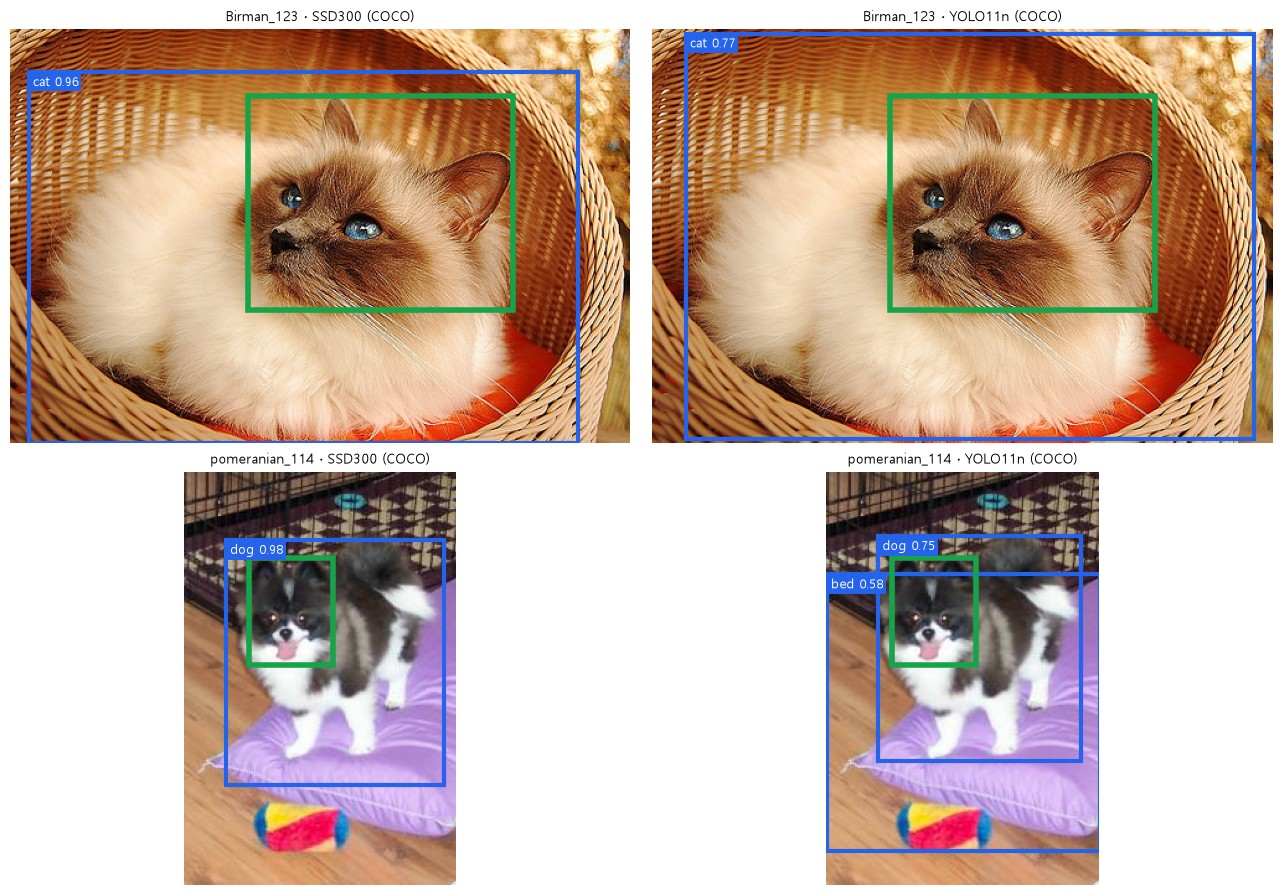

In [35]:
# 왜 · 같은 사진에 SSD와 YOLO를 돌려 결과를 나란히 비교하기 위해
def both_models(stem):  # 같은 사진 · 같은 기준으로 두 모델
    path = IMAGES / f"{stem}.jpg"                                        # 사진 경로
    with torch.no_grad():                                                # 예측만
        s_out = ssd([SSD_W.transforms()(decode_image(str(path)))])[0]    # SSD
    keep = s_out["scores"] > 0.5                                         # 같은 기준: 점수 0.5 초과
    kept = {k: v[keep].tolist() for k, v in s_out.items()}               # 0.5 초과 줄만 목록으로
    ssd_out = [(categories[lb], v, bx) for bx, lb, v in                  # (이름, 점수, 박스)
               zip(kept["boxes"], kept["labels"], kept["scores"])]
    r = yolo.predict(str(path), conf=0.5, device="cpu", verbose=False)[0]  # YOLO
    yolo_out = [(r.names[int(c)], v, bx) for bx, c, v in zip(            # 같은 모양으로
        r.boxes.xyxy.tolist(), r.boxes.cls.tolist(), r.boxes.conf.tolist())]
    gt_box, _, _ = read_gt(stem)                                         # 머리 정답
    print(f"[{stem}] 정답(머리):", [int(v) for v in gt_box])             # 정답
    for name, outs in (("SSD ", ssd_out), ("YOLO", yolo_out)):           # 두 모델
        for lab, v, bx in outs:                                          # 예측마다
            print(f"  {name} {lab:5s} {v:.2f}  {[int(q) for q in bx]}")  # 한 줄
    return path, gt_box, ssd_out, yolo_out                               # 그림 · 비교용


# 왜 · 두 모델에서 같은 클래스의 첫 박스를 꺼내 비교하기 위해
def first_box(outs, name):                                     # 그 이름의 첫 예측
    return [(v, bx) for lab, v, bx in outs if lab == name][0]  # (점수, 박스)


# 왜 · 고양이 · 개 사진에서 두 모델의 점수와 박스를 비교하기 위해
results = [(both_models("Birman_123"), "cat"), (both_models("pomeranian_114"), "dog")]  # 두 사진
fig, axes = plt.subplots(2, 2, figsize=(13, 9))                               # 사진 2장 × 모델 2개
for row, ((path, gt_box, ssd_out, yolo_out), name) in zip(axes, results):     # 사진마다
    models = (("SSD300 (COCO)", ssd_out), ("YOLO11n (COCO)", yolo_out))       # 두 모델
    for ax, (mname, outs) in zip(row, models):                                # 모델마다
        draw(Image.open(path), gt=[gt_box], pred=[bx for _, _, bx in outs], ax=ax,  # 정답 · 예측
             labels=[f"{lab} {v:.2f}" for lab, v, _ in outs], title=f"{path.stem} · {mname}")
    (sv, sb), (yv, yb) = first_box(ssd_out, name), first_box(yolo_out, name)  # 같은 클래스 박스
    s_box, y_box, head_t = torch.tensor([sb]), torch.tensor([yb]), torch.tensor([gt_box])  # 텐서로
    print(f"[{path.stem}] {name} 점수: SSD {sv:.2f} · YOLO {yv:.2f} · 두 모델 박스끼리 IoU"  # 비교
          f" {box_iou(s_box, y_box).item():.2f} · 머리 정답과 IoU: SSD"
          f" {box_iou(s_box, head_t).item():.2f} · YOLO {box_iou(y_box, head_t).item():.2f}")
plt.tight_layout()                                                            # 여백 정리
plt.show()                                                                    # 그림 출력

**결과** · 예측 정답은 박스끼리 `0.82` · 머리 정답과는 `0.28` · `0.25` (고양이)

- `[Birman_123] cat 점수: SSD 0.96 · YOLO 0.77 · 두 모델 박스끼리 IoU 0.82 · 머리 정답과 IoU: SSD 0.28 · YOLO 0.25` — 두 모델은 비슷한 몸 박스
- `[pomeranian_114] dog 점수: SSD 0.98 · YOLO 0.75 · 두 모델 박스끼리 IoU 0.83 · 머리 정답과 IoU: SSD 0.17 · YOLO 0.20` — 개도 같은 결과
- `YOLO bed   0.58  [0, 73, 197, 274]` — YOLO는 침대까지 찾음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>공통</td><td>1단계 · 한 번 통과</td><td>빠름</td></tr>
<tr><td>차이</td><td>디폴트 박스 vs 칸 중심 거리</td><td>구조</td></tr>
<tr><td>우리 미션 모델</td><td>SSD</td><td>Day02에서 머리로 학습</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - YOLO 숫자는 원본(YOLO26n)과 다름 → 모델 버전이 다르기 때문

> ✅ **한 줄 정리** · SSD와 YOLO는 후보를 두는 방식만 다르고 둘 다 COCO의 몸 박스를 내므로, 머리 정답과는 잘 겹치지 않는다.

**딥러닝 코드에서는**

- 객체탐지-3 4-1: 같은 사진 64장 · 같은 기준으로 세 모델 비교

---
## 9. 종합 실습 · 정답과 짝짓기 → 채점

> **이 장의 흐름**
>
> - 1 ~ 8장을 원본 D1-11 사진 8장에 한 번에
> - 짝짓기 규칙 → 판정 → 정밀도 · 재현율 · F1

<img src="images/pfo1_matching.png" alt="짝짓기 규칙: 점수 높은 순 → TP · FP · FN" width="763">

**파이프라인 위치** · ④ 예측 → ⑥ 평가

> 🎯 **'cat 0.996'은 맞힌 것인가? 사진 8장을 채점하면?**

💡 **쉽게 말하면**

- 점수가 높아도 **머리 정답과 IoU 0.5 이상**이어야 맞힌 것.
- 같은 머리에 박스가 두 개면 하나만 TP.

**실행 흐름**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">단계</th><th style="text-align: left;">하는 일</th><th style="text-align: left;">쓰는 문법</th></tr>
</thead>
<tbody>
<tr><td>1</td><td>COCO cat · dog → 우리 번호 1 · 2</td><td>2-1</td></tr>
<tr><td>2</td><td>predict: 점수 0.5 이상 cat · dog만</td><td>5-1</td></tr>
<tr><td>3</td><td>match: 점수 순 · 같은 클래스 · 짝 없는 정답</td><td>4-1</td></tr>
<tr><td>4</td><td>같은 머리에 박스 두 개 → TP · FP</td><td>5-4</td></tr>
<tr><td>5</td><td>사진 8장 판정 → 정밀도 · 재현율 · F1</td><td>평가지표 보충 3-1</td></tr>
</tbody></table>

**먼저 예측** · 사진 8장에서 TP는 몇 개일까? — 답은 코드 실행 결과 아래에

In [36]:
# 왜 · COCO 번호와 우리 번호가 달라 바꿔 줘야 채점할 수 있기 때문에
COCO_TO_OURS = {COCO.index("cat"): 1, COCO.index("dog"): 2}  # 나머지 COCO 클래스는 버림
# 17 · 18
print("COCO cat, dog 번호:", list(COCO_TO_OURS), "→ 우리 번호", list(COCO_TO_OURS.values()))


# 왜 · 채점할 예측을 같은 기준으로 모으기 위해
def predict(stem, score_min=0.5):  # COCO SSD 예측 중 점수 ≥ score_min인 cat · dog만
    with torch.no_grad():          # 예측만
        o = ssd([TF.to_tensor(load_image(stem))])[0]  # 학습 전 COCO 모델
    # 남길 줄
    keep = [i for i, (lb, s_) in enumerate(zip(o["labels"].tolist(), o["scores"].tolist()))
            if s_ >= score_min and lb in COCO_TO_OURS]
    return (o["boxes"][keep],      # 박스
            # 우리 번호
            torch.tensor([COCO_TO_OURS[o["labels"][i].item()] for i in keep], dtype=torch.int64),
            o["scores"][keep])     # 점수


# 왜 · 예측과 정답을 IoU로 짝지어 TP · FP · FN을 판정하기 위해
def match(p_boxes, p_labels, g_boxes, g_labels, iou_min=0.5):       # 점수 순 짝짓기
    iou = (box_iou(p_boxes, g_boxes) if len(p_boxes) and len(g_boxes)  # 예측 × 정답
           else torch.zeros(len(p_boxes), len(g_boxes)))
    used, verdicts = set(), []                                      # 짝 생긴 정답 · 판정
    for i in range(len(p_boxes)):                                   # predict() 결과는 이미 점수 순
        cand = [(iou[i, j].item(), j) for j in range(len(g_boxes))  # 같은 클래스 · 짝 없는 정답
                if j not in used and g_labels[j] == p_labels[i]]
        best, j = max(cand, default=(0.0, None))                    # 가장 많이 겹친 정답
        shown = iou[i].max().item() if len(g_boxes) else 0.0        # 클래스 상관없이 최대 IoU
        if j is not None and best >= iou_min:                       # 기준 이상
            used.add(j)                                             # 그 정답은 다시 못 씀
            verdicts.append(("TP", best))                           # 맞음
        else:                                                       # 아니면
            verdicts.append(("FP", shown))                          # 틀림
    return verdicts, len(g_boxes) - len(used)                       # (예측별 판정, FN 개수)


# 왜 · 같은 정답에 겹친 예측 두 개가 어떻게 판정되는지 작은 예로 확인하기 위해
gt_toy = torch.tensor([[100., 100., 200., 200.]])                   # 정답 머리 박스 1개 (장난감 예)
# 예측 2개 · 거의 같은 자리
two_preds = torch.tensor([[102., 98., 205., 200.], [95., 105., 198., 210.]])
print("IoU:", [round(v, 2) for v in box_iou(two_preds, gt_toy)[:, 0].tolist()])  # 둘 다 많이 겹침
verdicts, fn = match(two_preds, torch.tensor([1, 1]), gt_toy, [1])  # 짝짓기
print([v for v, _ in verdicts], "· FN", fn)                         # 하나만 TP

COCO cat, dog 번호: [17, 18] → 우리 번호 [1, 2]
IoU: [0.92, 0.81]
['TP', 'FP'] · FN 0


**실행 흐름**

1. 사진 8장마다 정답 읽기 · 예측 · 짝짓기
2. 사진별 판정 한 줄 출력
3. TP · FP · FN 합계로 정밀도 · 재현율 · F1

In [37]:
# 왜 · 원본과 같은 사진 8장으로 판정 결과를 모으기 위해
photos = ["Abyssinian_10", "Bengal_101", "american_bulldog_121",  # 원본의 사진 8장
          "newfoundland_104",
          "basset_hound_102", "British_Shorthair_116", "Sphynx_114", "keeshond_104"]
TP, FP, FN = 0, 0, 0                                              # 합계
for stem in photos:                                               # 사진마다
    g_boxes, g_names = read_voc(XMLS / f"{stem}.xml")             # 머리 정답
    g_labels = [NAME_TO_LABEL[n] for n in g_names]                # 우리 번호
    p_boxes, p_labels, p_scores = predict(stem)                   # 점수 0.5 이상 cat · dog
    # 판정
    verdicts, fn = match(p_boxes, p_labels, torch.tensor(g_boxes, dtype=torch.float32), g_labels)
    preds = [f"예측 {['', 'cat', 'dog'][lb]} {s_:.2f} → {v} (IoU {iou_v:.2f})"  # 예측마다 한 조각
             for lb, s_, (v, iou_v) in zip(p_labels.tolist(), p_scores.tolist(), verdicts)]
    # 한 줄
    print(f"{stem:22s} 정답 {g_names[0]} 머리 | " + (" / ".join(preds) or "cat·dog 예측 없음")
          + f" | FN {fn}")
    TP += sum(v == "TP" for v, _ in verdicts)                     # 맞힌 수
    FP += sum(v == "FP" for v, _ in verdicts)                     # 틀린 수
    FN += fn                                                      # 놓친 수

# 왜 · 모은 판정으로 정밀도 · 재현율 · F1을 계산하기 위해
print(f"TP {TP} · FP {FP} · FN {FN}")                           # 합계
precision = TP / (TP + FP)                                      # 모델이 낸 박스 중 맞힌 비율
recall = TP / (TP + FN)                                         # 정답 박스 중 찾아낸 비율
f1 = 2 * precision * recall / (precision + recall)              # 조화 평균
print(f"정밀도(precision) = {TP}/{TP + FP} = {precision:.2f}")  # 정밀도
print(f"재현율(recall)    = {TP}/{TP + FN} = {recall:.2f}")     # 재현율
print(f"F1               = {f1:.2f}")                           # F1

Abyssinian_10          정답 cat 머리 | 예측 cat 0.84 → FP (IoU 0.37) | FN 1


Bengal_101             정답 cat 머리 | 예측 cat 0.99 → FP (IoU 0.17) | FN 1


american_bulldog_121   정답 dog 머리 | 예측 dog 0.99 → FP (IoU 0.27) | FN 1


newfoundland_104       정답 dog 머리 | 예측 dog 0.99 → FP (IoU 0.25) | FN 1


basset_hound_102       정답 dog 머리 | 예측 dog 0.97 → TP (IoU 0.95) | FN 0


British_Shorthair_116  정답 cat 머리 | 예측 cat 0.98 → TP (IoU 0.61) | FN 0


Sphynx_114             정답 cat 머리 | 예측 dog 0.81 → FP (IoU 0.61) | FN 1


keeshond_104           정답 dog 머리 | cat·dog 예측 없음 | FN 1
TP 2 · FP 5 · FN 6
정밀도(precision) = 2/7 = 0.29
재현율(recall)    = 2/8 = 0.25
F1               = 0.27


**결과** · 예측 정답은 `2`개 — 대부분 몸 박스라 머리와 IoU 0.5 미만

- `COCO cat, dog 번호: [17, 18] → 우리 번호 [1, 2]` — 나머지 COCO 클래스는 버림
- `['TP', 'FP'] · FN 0` — 같은 머리의 두 번째 박스 = FP
- `Abyssinian_10          정답 cat 머리 | 예측 cat 0.84 → FP (IoU 0.37) | FN 1` — 몸 박스
- `basset_hound_102       정답 dog 머리 | 예측 dog 0.97 → TP (IoU 0.95) | FN 0` — 얼굴이 사진을 채움
- `Sphynx_114             정답 cat 머리 | 예측 dog 0.81 → FP (IoU 0.61) | FN 1` — IoU는 넘었지만 클래스가 다름
- `TP 2 · FP 5 · FN 6` — 합계
- `정밀도(precision) = 2/7 = 0.29` — 낸 박스 7개 중 2개
- `재현율(recall)    = 2/8 = 0.25` — 정답 8개 중 2개

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>신뢰도 (score) 0.5</td><td>예측 하나의 점수</td><td>예측 거르기</td></tr>
<tr><td>NMS IoU (SSD 기본 0.45)</td><td>예측 ↔ 예측</td><td>겹친 후보 정리 · 5장</td></tr>
<tr><td>학습 매칭 IoU 0.5</td><td>디폴트 박스 ↔ 정답</td><td>학습 때 양성 고르기 · 6장</td></tr>
<tr><td>평가 매칭 IoU 0.5</td><td>최종 예측 ↔ 정답</td><td>채점 · 지금</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - Sphynx_114는 IoU 0.61인데 FP → 클래스까지 같아야 TP (털 없는 고양이를 개로 봄)

> ✅ **한 줄 정리** · 점수가 높아도 같은 클래스 정답과 IoU 기준 이상으로 짝지어져야 TP이며, 기준 하나로 정밀도 · 재현율을 센다.

**딥러닝 코드에서는**

- 여러 기준을 묶은 평가 = AP · 클래스별 AP 평균 = mAP → Day02 · 평가지표 보충

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">학습 목표</th><th style="text-align: left;">할 수 있게 된 것</th><th style="text-align: left;">확인 위치</th></tr>
</thead>
<tbody>
<tr><td>1. 분류 vs 탐지 출력</td><td>분류 1000칸 확률 하나 · 탐지 boxes (200, 4)</td><td>1-2 · 2-2</td></tr>
<tr><td>2. XML · 박스 표기</td><td><code>[241, 31, 310, 102]</code> → xywh 69 · 71 · 뒤집으면 <code>[90, 31, 159, 102]</code></td><td>3장</td></tr>
<tr><td>3. IoU · NMS</td><td>50 밀면 0.33 · 후보 462 → 거름 9 → NMS 1</td><td>4 · 5장</td></tr>
<tr><td>4. 모델 계열 · 계약</td><td>RPN 후보 1000 · SSD 8732 · YOLO 80 · 40 · 20 · labels int64</td><td>6 ~ 8장</td></tr>
<tr><td>5. 채점</td><td>사진 8장 TP 2 · FP 5 · FN 6 → 정밀도 0.29 · 재현율 0.25</td><td>9장</td></tr>
</tbody></table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td><code>A</code></td><td>탐지 출력</td><td>boxes · scores · labels · 최대 200줄</td><td><code>model([x])[0]</code></td></tr>
<tr><td><code>A</code></td><td>XML · 표기</td><td>머리 박스 · xyxy · 형식 확인</td><td><code>read_voc</code> · <code>box_convert</code></td></tr>
<tr><td><code>A</code></td><td>IoU</td><td>겹친 ÷ 합친 · 작은 물체 민감</td><td><code>box_iou</code></td></tr>
<tr><td><code>A</code></td><td>신뢰도 · NMS</td><td>거르기 → 클래스별 NMS</td><td><code>batched_nms</code></td></tr>
<tr><td><code>A</code></td><td>모델 계열</td><td>2단계 RPN · 1단계 디폴트 박스 · 격자</td><td>Faster · SSD · YOLO</td></tr>
<tr><td><code>A</code></td><td>데이터 계약</td><td>float32 [N, 4] · int64 [N] · 0 = 배경</td><td><code>make_target</code></td></tr>
<tr><td><code>A</code></td><td>채점</td><td>점수 순 · 같은 클래스 · IoU ≥ 0.5</td><td><code>match</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td><code>B</code></td><td>창문 · 학습 매칭</td><td>수천 번 · 디폴트 박스 양성</td><td>R-CNN · SSD 학습</td></tr>
</tbody></table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

*섹션 → 🎯 질문*

- **1-2** · 분류 모델로 위치를 못 찾는 이유는?
- **2-2** · 탐지 출력 세 가지와 줄 수는?
- **3-1** · Oxford XML의 정답 박스는 어디를 감싸는가?
- **3-4** · 좌우로 뒤집은 박스는?
- **4-1** · IoU는?
- **4-3** · 신뢰도 0.99인데 IoU 0.16인 이유는?
- **5-3** · NMS 순서는?
- **5-4** · NMS가 못 하는 것은?
- **6-2** · Faster R-CNN의 두 단계는?
- **6-3** · SSD 디폴트 박스 수는?
- **7-1** · 공식 test로 채점할 수 없는 이유는?
- **7-4** · target 약속은?
- **8-1** · YOLO와 SSD의 클래스 수 차이는?
- **9** · Sphynx_114 예측이 FP인 이유는?

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**7-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**7-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**8-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**9** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. 너비 500 사진에서 박스 `[30, 10, 130, 90]`을 좌우로 뒤집은 박스
2. 후보 `[[0, 0, 10, 10], [1, 1, 11, 11], [20, 20, 30, 30]]` · 점수 `[0.9, 0.8, 0.7]`에 NMS(0.5)

In [38]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. `detect(img, score_thr=0.3)`이면 leonberger_142의 단계별 개수는? (5-5 함수로 실행)
2. SSD300 입력을 512로 키운다면 디폴트 박스가 늘어날 맵은? (특징 맵 크기가 커짐)
3. 9장에서 평가 IoU를 0.3으로 낮추면 Abyssinian_10의 판정은? (IoU 0.37)

In [39]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

*섹션 → 답*

- **1-2** · 사진 전체에 이름 하나 · 위치 칸 없음
- **2-2** · boxes · scores · labels · 최대 200줄
- **3-1** · 머리(얼굴)
- **3-4** · `[W - x2, y1, W - x1, y2]`
- **4-1** · 겹친 넓이 ÷ 합친 넓이
- **4-3** · 몸 박스 vs 머리 정답
- **5-3** · 1등 남기고 많이 겹친 것 지우기 반복
- **5-4** · 물체 하나에 박스 하나 보장 · 다른 클래스 정리
- **6-2** · RPN 후보 → RoI Heads 판정
- **6-3** · 8732개
- **7-1** · 머리 박스 XML이 없음
- **7-4** · boxes float32 [N, 4] · labels int64 [N] · 0 = 배경
- **8-1** · 80 (배경 없음) vs 91
- **9** · IoU는 넘었지만 클래스(dog)가 정답(cat)과 다름

#### 코드 문제 답

```python
# 1. W - x 후 두 변 맞바꿈
W, (x1, y1, x2, y2) = 500, (30, 10, 130, 90)
print([W - x2, y1, W - x1, y2])  # [370, 10, 470, 90]

# 2. 0번 · 1번 IoU ≈ 0.68 > 0.5 → 1번 지움
cand = torch.tensor([[0., 0., 10., 10.], [1., 1., 11., 11.], [20., 20., 30., 30.]])
print(nms(cand, torch.tensor([0.9, 0.8, 0.7]), 0.5).tolist())  # [0, 2]
```

#### 변형 문제 답

*문제 → 답*

- **1** · 직접 실행 · 점수 기준이 낮을수록 ② 단계 수가 늘어남 (0.5에서 9 · 0.1에서 12)
- **2** · 모든 맵이 커져 칸 수가 늘어남 → 디폴트 박스도 늘어남
- **3** · IoU 0.37 ≥ 0.3 → TP (기준을 낮추면 몸 박스도 맞힌 것으로 셈)

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">틀린 내용</th><th style="text-align: left;">틀린 이유</th><th style="text-align: left;">올바른 원칙</th><th style="text-align: left;">재발 방지 질문</th></tr>
</thead>
<tbody>
<tr><td>(예) 'cat 0.996'이면 맞혔다고 답함</td><td>점수와 IoU를 같은 것으로 봄</td><td>점수 = 확신 · 맞힘은 IoU로</td><td>정답과 IoU를 쟀나?</td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
</tbody></table>

---
## 면접 30초 답변

**Q1. 객체 탐지와 이미지 분류의 차이는?**
> - 분류는 사진 한 장에 클래스 확률 하나를 내지만, 탐지는 사진마다 개수가 정해지지 않은 박스 목록을 내고 박스마다 좌표, 클래스, 신뢰도를 붙입니다.
> - 그래서 정답도 박스와 라벨을 담은 딕셔너리가 되고, 채점은 IoU로 짝지은 뒤 정밀도와 재현율로 합니다.

**Q2. NMS는 왜 필요하고 어떻게 동작하나요?**
> - 탐지 모델은 같은 물체에 겹친 후보를 여러 개 내므로 중복을 지워야 합니다.
> - 점수 1등을 남기고 그와 IoU가 기준을 넘는 같은 클래스 후보를 지우는 일을 반복하며, 몸과 머리처럼 덜 겹친 박스는 둘 다 남을 수 있습니다.

**Q3. SSD와 Faster R-CNN은 후보를 어떻게 만드나요?**
> - Faster R-CNN은 RPN이 앵커에서 후보 1000개를 만들고 RoI Heads가 후보마다 다시 판정하는 2단계입니다.
> - SSD는 특징 맵 6장의 칸마다 디폴트 박스 8732개를 두고 박스마다 클래스 점수와 위치 보정을 한 번에 내는 1단계입니다.

**Q4. 탐지 모델에 넣는 한 샘플의 형식은?**
> - 이미지 텐서와 target 딕셔너리 한 쌍입니다.
> - boxes는 float32 [N, 4] xyxy, labels는 int64 [N]이고 0번은 배경이라 우리 클래스는 1부터 씁니다.
> - 약속을 어기면 학습 모드에서 바로 에러가 나므로 첫 batch를 점검합니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>resnet18(weights=)</code></td><td>torchvision.models</td><td>ImageNet 분류</td><td>1-2 <code>classifier = resnet18(weights=cls_w).eval()</code></td></tr>
<tr><td><code>ssd300_vgg16(weights=)</code></td><td>torchvision.models.detection</td><td>COCO 탐지 SSD</td><td>2-1 <code>detector = ssd300_vgg16(weights=det_w).eval()</code></td></tr>
<tr><td><code>model([x])[0]</code></td><td>탐지 모델 호출</td><td>사진 목록 → 사진마다 dict</td><td>2-2 <code>out = detector([x])[0]</code></td></tr>
<tr><td><code>ET.parse()</code> · <code>findtext()</code> · <code>iter()</code></td><td>xml.etree.ElementTree</td><td>XML 읽기</td><td>3-1 <code>root = ET.parse(xml_path).getroot()</code></td></tr>
<tr><td><code>box_convert()</code></td><td>torchvision.ops</td><td>박스 표기 바꾸기</td><td>3-3 <code>box_convert(b, "xyxy", "xywh")</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>box_iou()</code></td><td>torchvision.ops</td><td>IoU 표</td><td>4-1 <code>box_iou(gt_t, preds)</code></td></tr>
<tr><td><code>nms()</code> · <code>batched_nms()</code></td><td>torchvision.ops</td><td>NMS · 클래스별 NMS</td><td>5-3 <code>nms(boxes, scores, iou_threshold=0.5)</code> · 5-4 <code>batched_nms(...)</code></td></tr>
<tr><td><code>copy.deepcopy()</code> · <code>nms_thresh</code></td><td>copy · 탐지 모델 속성</td><td>NMS 끈 복사본</td><td>5-2 <code>raw.nms_thresh = 1.0</code></td></tr>
<tr><td><code>fasterrcnn_resnet50_fpn()</code></td><td>torchvision.models.detection</td><td>2단계 탐지기 구조</td><td>6-2 <code>fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None)</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>anchor_generator</code> · <code>box_coder</code></td><td>SSD 속성</td><td>디폴트 박스 · 보정</td><td>6-5 <code>ssd.box_coder.decode_single(...)</code></td></tr>
<tr><td><code>make_target()</code></td><td>직접 만든 함수</td><td>XML → target</td><td>7-4 <code>t = make_target("Abyssinian_173")</code></td></tr>
<tr><td><code>YOLO()</code> · <code>predict()</code></td><td>ultralytics</td><td>YOLO 예측</td><td>8-2 <code>yolo.predict(str(path), conf=0.5, ...)</code></td></tr>
<tr><td><code>match()</code></td><td>직접 만든 함수</td><td>짝짓기 → TP · FP · FN</td><td>9 <code>verdicts, fn = match(...)</code></td></tr>
</tbody></table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">✅ 할 것</th><th style="text-align: left;">⚠️ 하지 말 것</th></tr>
</thead>
<tbody>
<tr><td>박스 형식을 먼저 확인</td><td>뒤 두 숫자를 너비 · 높이로 짐작</td></tr>
<tr><td>크기 · 뒤집기 때 박스도 바꿈</td><td>사진만 바꾸기</td></tr>
<tr><td>여러 클래스면 <code>batched_nms</code></td><td>클래스가 여럿인데 <code>nms</code></td></tr>
<tr><td>점수와 IoU를 따로 확인</td><td>점수가 높으면 맞혔다고 보기</td></tr>
<tr><td>채점은 trainval에서 떼어 둔 사진으로</td><td>공식 test(XML 없음)로 채점</td></tr>
</tbody></table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">짝</th><th style="text-align: left;">차이</th><th style="text-align: left;">결론</th></tr>
</thead>
<tbody>
<tr><td>분류 vs 탐지</td><td>이름 하나 vs 박스 여러 개 + 이름 + 점수</td><td>위치가 필요하면 탐지</td></tr>
<tr><td>xyxy vs xywh vs cxcywh</td><td>모서리 vs 모서리 + 크기 vs 가운데 + 크기</td><td>형식 확인 · <code>box_convert</code></td></tr>
<tr><td>신뢰도 vs IoU</td><td>모델의 확신 vs 정답과의 겹침</td><td>확신이 높아도 IoU는 낮을 수 있음</td></tr>
<tr><td>nms vs batched_nms</td><td>클래스 무시 vs 같은 클래스끼리</td><td>여러 클래스면 batched</td></tr>
<tr><td>2단계 vs 1단계</td><td>후보 → 판정 vs 칸마다 한 번에</td><td>정확 vs 빠름</td></tr>
<tr><td>학습 매칭 IoU vs 평가 매칭 IoU</td><td>디폴트 박스 ↔ 정답 vs 예측 ↔ 정답</td><td>쓰는 곳이 다름</td></tr>
</tbody></table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">언제</th><th style="text-align: left;">할 일</th><th style="text-align: left;">걸리는 시간</th></tr>
</thead>
<tbody>
<tr><td>내일</td><td>기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td><td>15분</td></tr>
<tr><td>3일 뒤</td><td>변형 문제 3개 · 5-3 NMS 단계를 종이에 다시</td><td>20분</td></tr>
<tr><td>7일 뒤</td><td>9장 채점 코드를 보지 않고 다시 짜기</td><td>30분</td></tr>
<tr><td>14일 뒤</td><td>오답 노트에 남은 문제만 · 파일별 2(Day02) 시작 전 ✅ 줄만 읽기</td><td>10분</td></tr>
</tbody></table>

---
## 부록

### 이 노트북을 만든 방법

- 원본 · `객체인식_Day01.html` 201셀을 D1-0 ~ D1-11 순서 그대로 8장 33섹션 + 9장 종합 실습으로
- Mac 데이터 경로 → kagglehub 캐시 · Mac 글꼴 → Malgun Gothic · 그림 색은 흰 배경용
- 원본의 YOLO26n 대신 이미 받아 둔 YOLO11n (새로 내려받지 않음) · 시간 값은 컴퓨터마다 다름
- 모든 코드는 실행한 출력과 함께 저장 · 형식 v2.1 (FORMAT_V2.md 1 ~ 7절)

### 읽는 법

*표시 → 의미*

- **`A` · `B`** · **A** 딥러닝 코드에 바로 나오는 필수 · **B** 알아두면 되는 것
- **🎯** · 이번 섹션에서 답해야 할 질문
- **💡** · 쉬운 설명 · 비유
- **⚠️** · 자주 하는 실수
- **✅** · 기억할 결론 = 🎯 질문의 답

- **섹션 앞부분** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드
- **섹션 뒷부분** · 결과(예측 정답 · 출력 줄) → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리
- **코드 주석** · 코드 위는 이 단계에서 하는 일, 코드 옆은 그 줄이 필요한 이유 (줄마다 · 열 맞춤)

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">내용</th><th style="text-align: left;">이 노트북</th></tr>
</thead>
<tbody>
<tr><td>셀 0 ~ 3</td><td>표지 · 라이브러리 · 도우미</td><td>0장</td></tr>
<tr><td>D1-0 · 셀 4 ~ 11</td><td>사진 + XML · 결과물 · 평가 기준 · 질문 순서</td><td>1-1 · 0장 원본 구성</td></tr>
<tr><td>D1-1 · 셀 12 ~ 21</td><td>분류 모델의 답 · 창문 옮기기</td><td>1-2 · 1-3</td></tr>
<tr><td>D1-2 · 셀 22 ~ 35</td><td>SSD 처음 · 출력 200줄 · 사진 3장 · 개 + 사람</td><td>2-1 ~ 2-3</td></tr>
<tr><td>D1-3 · 셀 36 ~ 59</td><td>XML · 잘못 읽기 · crop · 표기 · 크기 · 뒤집기 · 파일 이름</td><td>3-1 ~ 3-5</td></tr>
<tr><td>D1-4 · 셀 60 ~ 80</td><td>IoU 손계산 · 10픽셀 · 실제 사진 두 장</td><td>4-1 ~ 4-3</td></tr>
<tr><td>D1-5 · 셀 81 ~ 103</td><td>신뢰도 · NMS 직전 · 한 단계씩 · 기준 · 못 하는 것</td><td>5-1 ~ 5-4</td></tr>
<tr><td>D1-6 · 셀 104 ~ 110</td><td>detect 한 줄로</td><td>5-5</td></tr>
<tr><td>D1-7 · 셀 111 ~ 120</td><td>창문 수 · Faster R-CNN 구조</td><td>6-1 · 6-2</td></tr>
<tr><td>D1-8 · 셀 121 ~ 150</td><td>SSD 구조 · 헤드 · 보정 · 학습 짝짓기 · 손실</td><td>6-3 ~ 6-7</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">내용</th><th style="text-align: left;">이 노트북</th></tr>
</thead>
<tbody>
<tr><td>D1-9 · 셀 151 ~ 172</td><td>목록 · 점검 · 크기 · target · 약속</td><td>7-1 ~ 7-5</td></tr>
<tr><td>D1-10 · 셀 173 ~ 183</td><td>YOLO26n → YOLO11n · 같은 사진 두 모델</td><td>8-1 · 8-2</td></tr>
<tr><td>D1-11 · 셀 184 ~ 200</td><td>짝짓기 규칙 · 기준 네 가지 · 사진 8장 채점 · 내일 이어서</td><td>9</td></tr>
</tbody></table>

### 전체 코드

1 ~ 9장 코드를 장별 셀로 모음. **위에서부터 이 셀들만 실행해도 전체가 동작**하며, 각 블록 머리 주석의 번호가 섹션.

**실행 흐름**

1. 1-1 사진 + 정답 박스
2. 1-2 분류 모델 상위 3개

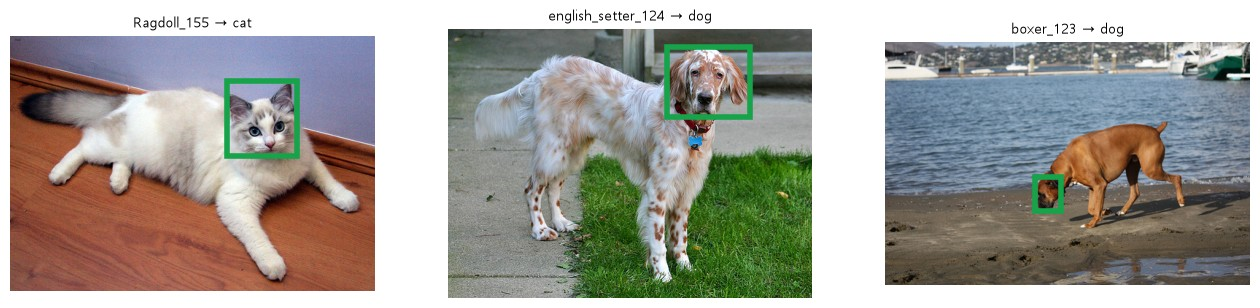

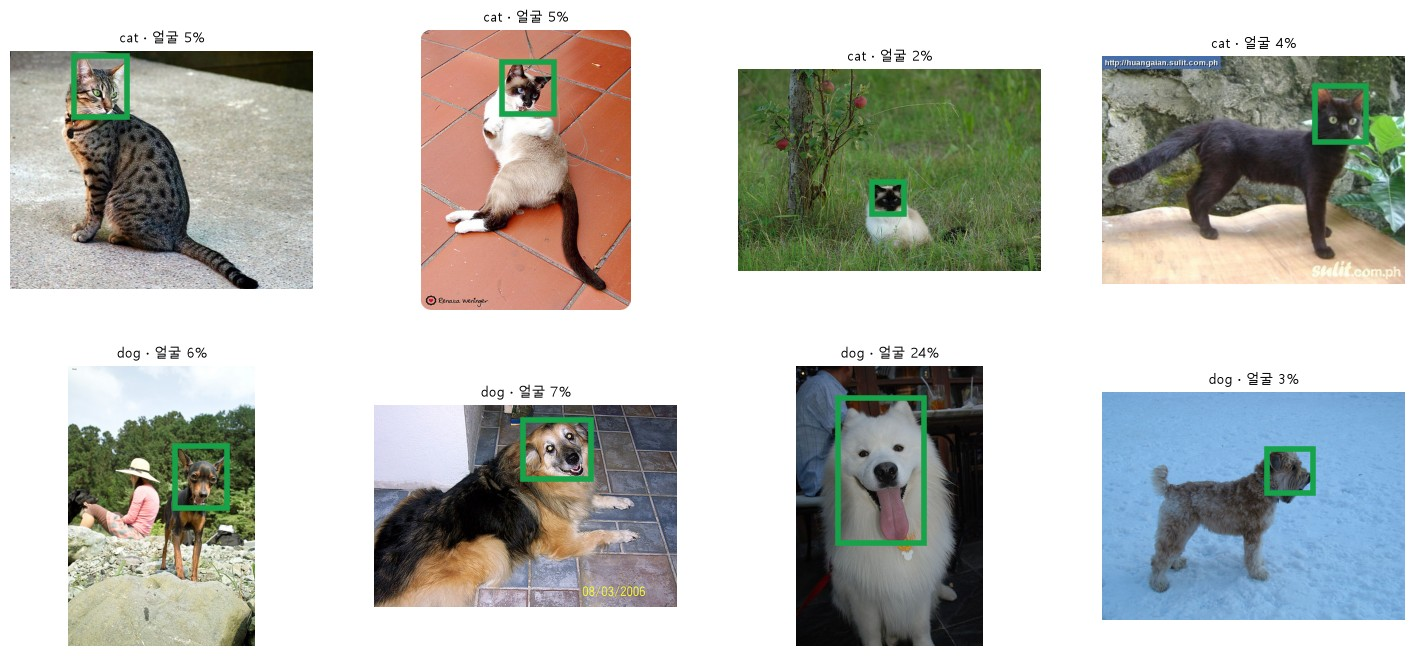

얼굴 비율: ['5%', '5%', '2%', '4%', '6%', '7%', '24%', '3%']


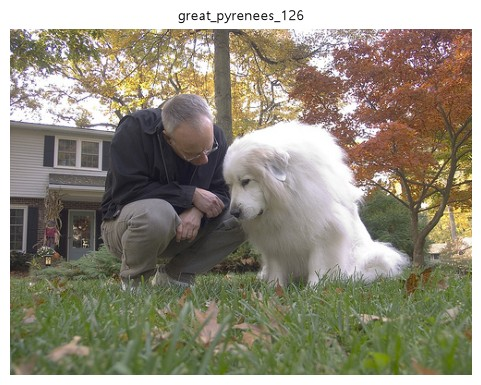

출력 모양: (1000,) · 확률 합: 1.0
Great Pyrenees   0.957
Samoyed          0.025
kuvasz           0.013
Pekinese         0.001
Pomeranian       0.001
이름 수: 1000
'person'이 목록에 있나? False


In [40]:
from torchvision.models import ResNet18_Weights, resnet18  # ImageNet 분류 모델


# ---------- 1-1 ----------
# 왜 · 고양이 · 개 사진에서 정답 박스가 어디를 가리키는지 먼저 보기 위해
examples = ["Ragdoll_155", "english_setter_124", "boxer_123"]              # 미션 예시 사진 3장
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))                          # 3칸
for stem, ax in zip(examples, axes):                                       # 사진마다
    boxes, names = read_voc(XMLS / f"{stem}.xml")                          # XML 읽기 (자세히는 3장)
    draw(load_image(stem), gt=boxes, title=f"{stem} → {names[0]}", ax=ax)  # 정답 박스
plt.show()                                                                 # 그림 출력

# 왜 · 여러 사진에서도 정답이 늘 머리라는 것을 확인하기 위해
more = ["Egyptian_Mau_116", "Siamese_206", "Birman_137", "Bombay_148",  # 8장 더
        "miniature_pinscher_107", "keeshond_134", "samoyed_187", "wheaten_terrier_114"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))                         # 2줄 × 4칸
ratios = []  # 사진 넓이 중 얼굴 박스 비율
for stem, ax in zip(more, axes.flat):                                   # 사진마다
    boxes, names = read_voc(XMLS / f"{stem}.xml")                       # 정답
    img = load_image(stem)                                              # 사진
    x1, y1, x2, y2 = boxes[0]                                           # 첫 박스
    ratio = (x2 - x1) * (y2 - y1) / (img.size[0] * img.size[1])         # 얼굴 박스 ÷ 사진
    ratios.append(ratio)                                                # 기록
    draw(img, gt=boxes, title=f"{names[0]} · 얼굴 {ratio:.0%}", ax=ax)  # 비율을 제목에
plt.show()                                                              # 그림 출력
print("얼굴 비율:", [f"{r:.0%}" for r in ratios])                       # 사진마다 다름


# ---------- 1-2 ----------

# 왜 · 물체가 둘 이상인 사진으로 분류 모델의 한계를 보기 위해
pair = load_image("great_pyrenees_126")  # 개 + 사람 사진
draw(pair, title="great_pyrenees_126")   # 사진 보기
plt.show()                               # 그림 출력

# 왜 · 분류 모델은 '무엇'만 알려 주고 위치는 주지 않는다는 것을 확인하기 위해
cls_w = ResNet18_Weights.IMAGENET1K_V1                   # ImageNet 1000개 이름으로 학습된 가중치
classifier = resnet18(weights=cls_w).eval()              # 평가 모드
x = cls_w.transforms()(pair).unsqueeze(0)                # 사진 → (1, 3, 224, 224)
with torch.no_grad():                                    # 예측만
    prob = classifier(x).softmax(dim=1)[0]               # 1000칸 확률
# 사진 한 장 = 1000칸
print("출력 모양:", tuple(prob.shape), "· 확률 합:", round(prob.sum().item(), 3))
top = prob.topk(5)                                       # 상위 5개
for p, i in zip(top.values, top.indices):                # 확률 · 번호
    print(f"{cls_w.meta['categories'][i]:16s} {p:.3f}")  # 이름 · 확률

# 왜 · 분류 모델이 고르는 이름이 몇 개인지 확인하기 위해
names_1000 = cls_w.meta["categories"]                     # 1000개 이름
print("이름 수:", len(names_1000))                        # 1000
print("'person'이 목록에 있나?", "person" in names_1000)  # 사람은 답할 수 없음

**실행 흐름**

1. 1-3 창문 세 곳 분류
2. 창문 수 세기 · 시간 재기

['mobile home 0.05', 'Great Pyrenees 0.98', 'Angora 0.62']


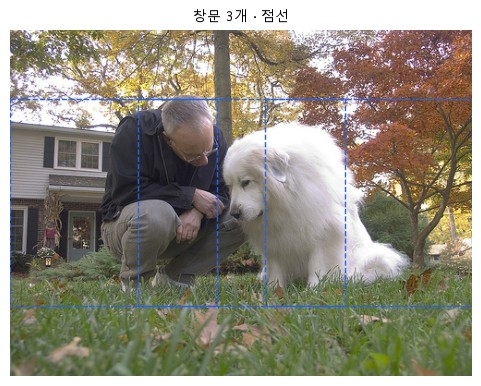

사진 크기: (500, 375) → 창문 수: 2975


분류 한 번 489ms × 창문 2975개 ≈ 1455초 (컴퓨터마다 다름)


In [41]:
# ---------- 1-3 ----------
# 왜 · 창문 세 곳을 잘라 분류하면 위치를 짐작할 수 있는지 보기 위해
windows = [[0, 75, 224, 299], [138, 75, 362, 299], [276, 75, 500, 299]]          # 224×224 창문 3개
answers = []                                                                     # 창문마다 답
for box in windows:                                                              # 창문마다
    crop = pair.crop(box)                                                        # 창문 안만 잘라서
    with torch.no_grad():                                                        # 예측만
        p = classifier(cls_w.transforms()(crop).unsqueeze(0)).softmax(dim=1)[0]  # 분류
    answers.append(f"{cls_w.meta['categories'][p.argmax()]} {p.max():.2f}")      # 1등 이름 · 확률
print(answers)                                                                   # 창문 3개의 답
draw(pair, cand=windows, title="창문 3개 · 점선")                                # 창문 그림
plt.show()                                                                       # 그림 출력

# 왜 · 창문 크기 · 간격에 따라 분류를 몇 번 해야 하는지 세기 위해
W_img, H_img = pair.size                                            # 사진 크기
count = 0                                                           # 창문 수
for size in (64, 128, 256):                                         # 창문 크기 3가지
    for ratio in (0.5, 1, 2):                                       # 모양 3가지 (세로 ÷ 가로)
        w, h = int(size / ratio ** 0.5), int(size * ratio ** 0.5)   # 넓이는 같고 모양만 다름
        count += ((W_img - w) // 16 + 1) * ((H_img - h) // 16 + 1)  # 16픽셀씩 옮김
print("사진 크기:", pair.size, "→ 창문 수:", count)                 # 2975개

with torch.no_grad():                                                          # 시간 재기
    classifier(x)                                                              # 한 번 데워 두기
    t = time.perf_counter()                                                    # 시작
    classifier(x)                                                              # 분류 한 번
one = time.perf_counter() - t                                                  # 한 번 시간
print(f"분류 한 번 {one * 1000:.0f}ms × 창문 {count}개 ≈ {one * count:.0f}초"  # 사진 한 장
      " (컴퓨터마다 다름)")

**실행 흐름**

1. 2-1 탐지 모델 · 입력 모양
2. 2-2 출력 200줄 읽기

COCO 이름 수: 91 · 앞 3개: ['__background__', 'person', 'bicycle']
'cat' 있나? True · 'dog' 있나? True
사진 크기 (가로, 세로): (400, 267)
텐서 모양 (채널, 세로, 가로): (3, 267, 400)
값 범위: 0.0 ~ 1.0


열쇠: ['boxes', 'scores', 'labels']
boxes   모양 (200, 4)
scores  모양 (200,)
labels  모양 (200,)
번호 17 → cat        점수 0.996  박스 [40, 29, 358, 247]
번호 65 → bed        점수 0.098  박스 [46, 136, 387, 251]
번호 20 → sheep      점수 0.077  박스 [293, 115, 351, 136]
번호 20 → sheep      점수 0.070  박스 [322, 119, 352, 134]
번호 63 → couch      점수 0.064  박스 [46, 136, 387, 251]
점수 0.5 넘는 줄: 1 / 200
최대 개수 설정: 200
박스 x 최댓값: 400 · 사진 가로: 400
이름 종류 수: 16
많이 나온 이름: [('person', 130), ('sheep', 17), ('cat', 13), ('book', 12), ('chair', 8), ('tie', 8)]
person 줄 중 가장 높은 점수: 0.041


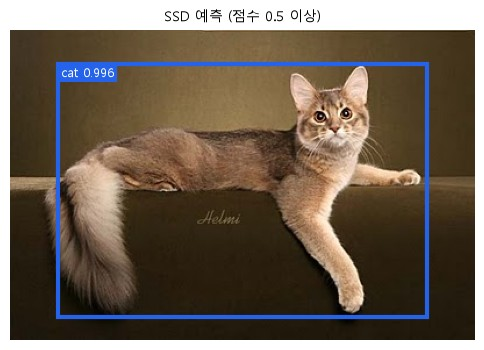

In [42]:
from torchvision.models.detection import SSD300_VGG16_Weights, ssd300_vgg16  # 탐지 모델
from collections import Counter                                              # 이름 세기


# ---------- 2-1 ----------

# 왜 · 완성된 탐지 모델과 그 입력 변환을 함께 불러오기 위해
det_w = SSD300_VGG16_Weights.COCO_V1                      # COCO 데이터로 학습된 가중치
detector = ssd300_vgg16(weights=det_w).eval()             # 처음 한 번은 내려받기 (약 136MB)
COCO = det_w.meta["categories"]                           # 번호 → 이름
print("COCO 이름 수:", len(COCO), "· 앞 3개:", COCO[:3])  # 0번 = 배경
print("'cat' 있나?", "cat" in COCO, "· 'dog' 있나?", "dog" in COCO)  # 둘 다 있음

# 왜 · 탐지 모델 입력 모양이 어떻게 바뀌는지 확인하기 위해
cat_img = load_image("Abyssinian_173")                  # 고양이 한 마리 사진
x = det_w.transforms()(cat_img)                         # PIL 사진 → 0~1 텐서 (크기는 그대로)
print("사진 크기 (가로, 세로):", cat_img.size)          # PIL은 (가로, 세로)
print("텐서 모양 (채널, 세로, 가로):", tuple(x.shape))  # 텐서는 (C, H, W)
print("값 범위:", round(x.min().item(), 2), "~", round(x.max().item(), 2))  # 0 ~ 1


# ---------- 2-2 ----------

with torch.no_grad():                       # 예측만
    out = detector([x])[0]                  # 사진 목록을 넣고 → 사진마다 결과 dict
print("열쇠:", list(out.keys()))            # boxes · scores · labels
for k, v in out.items():                    # 열쇠마다
    print(f"{k:7s} 모양 {tuple(v.shape)}")  # 줄 수

# 왜 · 출력 한 줄이 박스 · 이름 · 점수 묶음이라는 것을 읽기 위해
for b, lb, s in zip(out["boxes"][:5], out["labels"][:5], out["scores"][:5]):             # 앞 5줄
    xyxy = [round(v) for v in b.tolist()]                                                # 정수로
    print(f"번호 {lb.item():>2} → {COCO[lb]:10s} 점수 {s:.3f}  박스 {xyxy}")             # 한 줄
print("점수 0.5 넘는 줄:", (out["scores"] > 0.5).sum().item(), "/", len(out["scores"]))  # 1 / 200
print("최대 개수 설정:", detector.detections_per_img)                                    # 200
# 원본 크기
print("박스 x 최댓값:", round(out["boxes"][:, 2].max().item()), "· 사진 가로:", cat_img.size[0])

# 왜 · 출력 200줄에 어떤 이름이 섞여 있는지 세기 위해
names_200 = [COCO[lb] for lb in out["labels"]]               # 200줄의 이름
print("이름 종류 수:", len(set(names_200)))                  # 몇 종류
print("많이 나온 이름:", Counter(names_200).most_common(6))  # 상위 6개
is_person = out["labels"] == COCO.index("person")            # person 줄
print("person 줄 중 가장 높은 점수:", round(out["scores"][is_person].max().item(), 3))  # 낮음

# 왜 · 점수로 거르면 남는 박스가 어떻게 되는지 그림으로 보기 위해
keep = out["scores"] > 0.5  # 점수 0.5 초과만
# 이름표
labels = [f"{COCO[lb]} {s:.3f}" for lb, s in zip(out["labels"][keep], out["scores"][keep])]
draw(cat_img, pred=out["boxes"][keep], labels=labels, title="SSD 예측 (점수 0.5 이상)")  # 그림
plt.show()                  # 그림 출력

**실행 흐름**

1. 2-3 사진 3장 · 개 + 사람 사진 탐지

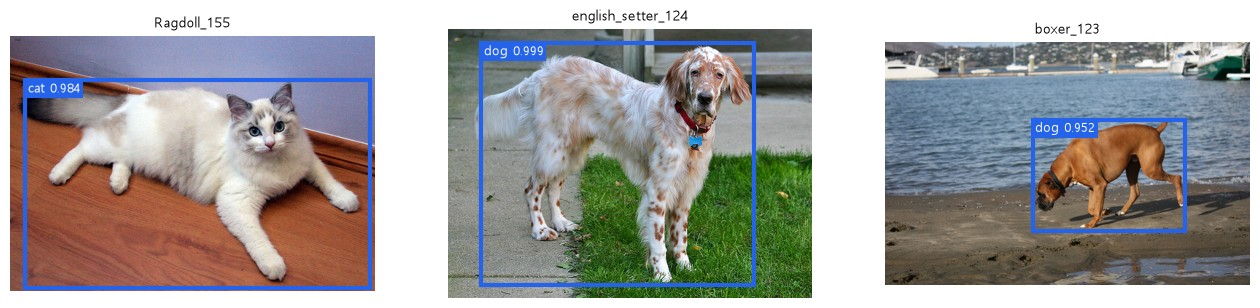

전체 200 줄 · 0.5 넘는 줄: ['dog 0.976', 'person 0.962']


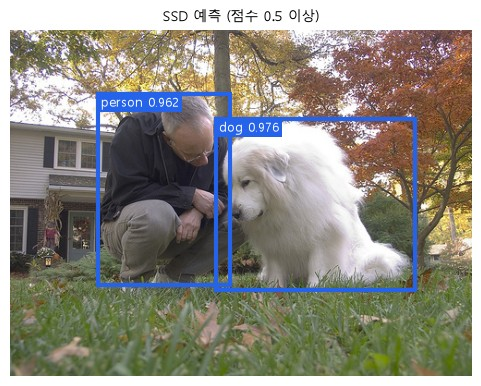

In [43]:
# ---------- 2-3 ----------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))     # 미션 사진 3장
for stem, ax in zip(examples, axes):                  # 사진마다
    img = load_image(stem)                            # 사진
    with torch.no_grad():                             # 예측만
        o = detector([det_w.transforms()(img)])[0]    # 예측
    # 왜 · 점수 0.5 초과 박스만 남겨 미션 사진 3장에서 모델이 무엇을 박스로 내는지 보기 위해
    k = o["scores"] > 0.5                             # 0.5 초과만
    draw(img, pred=o["boxes"][k], ax=ax, title=stem,  # 예측 박스
         labels=[f"{COCO[lb]} {s:.3f}" for lb, s in zip(o["labels"][k], o["scores"][k])])
plt.show()                                            # 그림 출력

with torch.no_grad():                                             # 개 + 사람 사진
    # 왜 · 개와 사람이 함께 있는 사진에서 물체마다 박스가 따로 나오는지 확인하기 위해
    out2 = detector([det_w.transforms()(pair)])[0]                # 예측
keep2 = out2["scores"] > 0.5                                      # 0.5 초과만
# 이름표
labels2 = [f"{COCO[lb]} {s:.3f}" for lb, s in zip(out2["labels"][keep2], out2["scores"][keep2])]
print("전체", len(out2["scores"]), "줄 · 0.5 넘는 줄:", labels2)  # 개와 사람을 둘 다
draw(pair, pred=out2["boxes"][keep2], labels=labels2, title="SSD 예측 (점수 0.5 이상)")  # 그림
plt.show()                                                        # 그림 출력

**실행 흐름**

1. 3-1 XML 원문 · 읽기
2. 3-2 잘못 읽은 박스 · 박스로 자르기

<annotation>
  <folder>OXIIIT</folder>
  <filename>Abyssinian_173.jpg</filename>
  <source>
    <database>OXFORD-IIIT Pet Dataset</database>
    <annotation>OXIIIT</annotation>
    <image>flickr</image>
  </source>
  <size>
    <width>400</width>
    <height>267</height>
    <depth>3</depth>
  </size>
  <segmented>0</segmented>
  <object>
    <name>cat</name>
    <pose>Frontal</pose>
    <truncated>0</truncated>
    <occluded>0</occluded>
    <bndbox>
      <xmin>241</xmin>
      <ymin>31</ymin>
      <xmax>310</xmax>
      <ymax>102</ymax>
    </bndbox>
    <difficult>0</difficult>
  </object>
</annotation>
filename : Abyssinian_173.jpg
size     : 400 × 267
name     : cat
bndbox   : [241, 31, 310, 102]
실제 사진 크기: (400, 267)
[[241.0, 31.0, 310.0, 102.0]] ['cat']
['xmls/ Head bounding box annotations in PASCAL VOC Format']
[[300.0, 24.0, 414.0, 121.0]] ['dog']


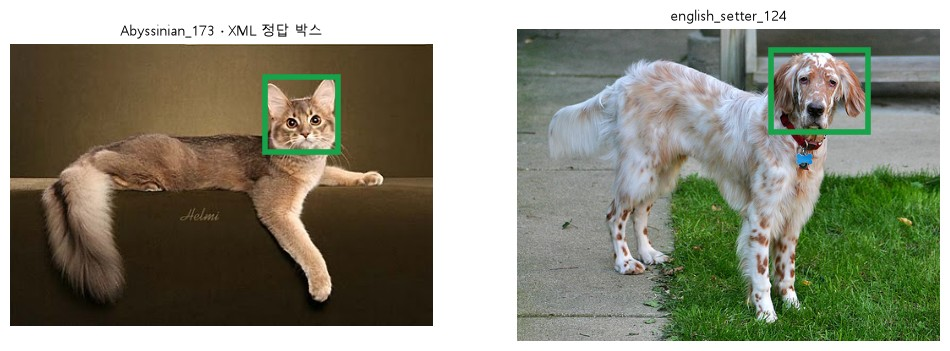

xyxy로 읽음      : [241.0, 31.0, 310.0, 102.0]
xywh로 잘못 읽음 : [241.0, 31.0, 551.0, 133.0] · 사진 너비 400


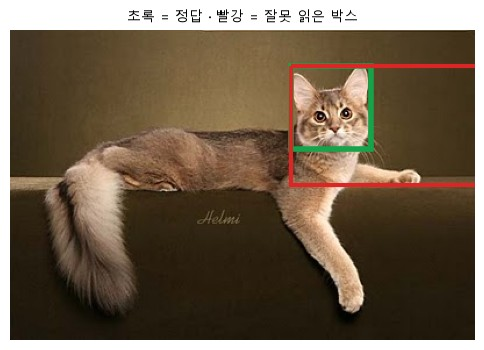

사진 배열 모양: (267, 400, 3)
crop 크기 (가로, 세로): (69, 71) · 배열 조각 모양: (71, 69, 3)


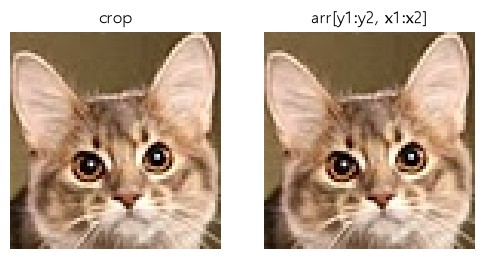

In [44]:
from torchvision.ops import box_convert  # 박스 표기 바꾸기
from PIL import ImageOps                 # 좌우 뒤집기


# ---------- 3-1 ----------
# 왜 · 정답 XML 원문 구조를 직접 열어 보기 위해
xml_path = XMLS / "Abyssinian_173.xml"        # 정답 파일 하나
root = ET.parse(xml_path).getroot()           # XML 열기
ET.indent(root)                               # 한 줄짜리 원문을 보기 좋게 줄바꿈
print(ET.tostring(root, encoding="unicode"))  # 원문

# 왜 · 필요한 정답 값을 태그 이름으로 꺼내는 법을 익히기 위해
print("filename :", root.findtext("filename"))  # 짝이 되는 사진
print("size     :", root.findtext("size/width"), "×", root.findtext("size/height"))  # 사진 크기
for obj in root.iter("object"):                 # 물체 하나 = object 하나
    bb = obj.find("bndbox")                     # 박스
    print("name     :", obj.findtext("name"))   # 이름
    print("bndbox   :", [int(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")])  # 네 숫자
print("실제 사진 크기:", cat_img.size)          # XML 크기와 같은지

# 왜 · 직접 읽은 값과 함수 결과가 같은지 확인하기 위해
boxes, names = read_voc(xml_path)      # 위 과정을 묶어 둔 도우미
print(boxes, names)                    # 박스 목록 · 이름 목록
readme = (ANN / "README").read_text()  # 데이터 설명서
# xmls 설명
print([" ".join(line.split()) for line in readme.splitlines() if line.startswith("xmls")])

# 왜 · 개 사진에서도 같은 함수가 통하는지 확인하기 위해
dog_boxes, dog_names = read_voc(XMLS / "english_setter_124.xml")             # 두 번째 예: 개
print(dog_boxes, dog_names)                                                  # 개 머리 박스
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))                            # 2칸
draw(cat_img, gt=boxes, title="Abyssinian_173 · XML 정답 박스", ax=axes[0])  # 고양이
draw(load_image("english_setter_124"), gt=dog_boxes, title="english_setter_124", ax=axes[1])  # 개
plt.show()                                                                   # 그림 출력


# ---------- 3-2 ----------
x1, y1, x2, y2 = boxes[0]                                                  # xyxy 네 숫자
wrong = [x1, y1, x1 + x2, y1 + y2]  # 310, 102를 너비 · 높이로 읽은 경우
print("xyxy로 읽음      :", boxes[0])                                      # 올바른 박스
print("xywh로 잘못 읽음 :", wrong, "· 사진 너비", cat_img.size[0])         # 사진 밖으로 나감
ax = draw(cat_img, gt=boxes, title="초록 = 정답 · 빨강 = 잘못 읽은 박스")  # 정답
_box(ax, wrong, "#dc2626", lw=3)                                           # 잘못 읽은 박스
plt.show()                                                                 # 그림 출력

# 왜 · PIL과 배열의 좌표 순서 차이를 박스 자르기로 확인하기 위해
x1, y1, x2, y2 = [int(v) for v in boxes[0]]     # 정수로
face = cat_img.crop((x1, y1, x2, y2))           # PIL crop = (왼, 위, 오른, 아래) = xyxy 그대로
arr = np.array(cat_img)                         # 배열 모양 = (세로, 가로, 채널)
face_arr = arr[y1:y2, x1:x2]                    # 배열은 [행 = y, 열 = x] → y가 먼저
print("사진 배열 모양:", arr.shape)             # (267, 400, 3)
print("crop 크기 (가로, 세로):", face.size, "· 배열 조각 모양:", face_arr.shape)  # 순서가 반대
fig, axes = plt.subplots(1, 2, figsize=(6, 3))  # 같은 얼굴 두 방법
axes[0].imshow(face)                            # crop 결과
axes[0].set_title("crop")                       # 제목
axes[1].imshow(face_arr)                        # 배열 조각
axes[1].set_title("arr[y1:y2, x1:x2]")          # 제목
for a in axes:                                  # 두 칸
    a.axis("off")                               # 눈금 숨김
plt.show()                                      # 그림 출력

**실행 흐름**

1. 3-3 세 가지 표기
2. 3-4 크기 바꾸기 · 뒤집기
3. 3-5 파일 이름과 XML name

xyxy  : [[241.0, 31.0, 310.0, 102.0]]
xywh  : [[241.0, 31.0, 69.0, 71.0]]
cxcywh: [[275.5, 66.5, 69.0, 71.0]]
얼굴 넓이 = 69 × 71 → 사진의 4.6%
가로 배율 0.750 · 세로 배율 1.124
그대로 둔 박스: [241.0, 31.0, 310.0, 102.0]
배율 곱한 박스: [180.8, 34.8, 232.5, 114.6]
W - x만 한 박스 : [159.0, 31.0, 90.0, 102.0] → xmin < xmax ? False
변을 바꾼 박스  : [90.0, 31.0, 159.0, 102.0] → xmin < xmax ? True


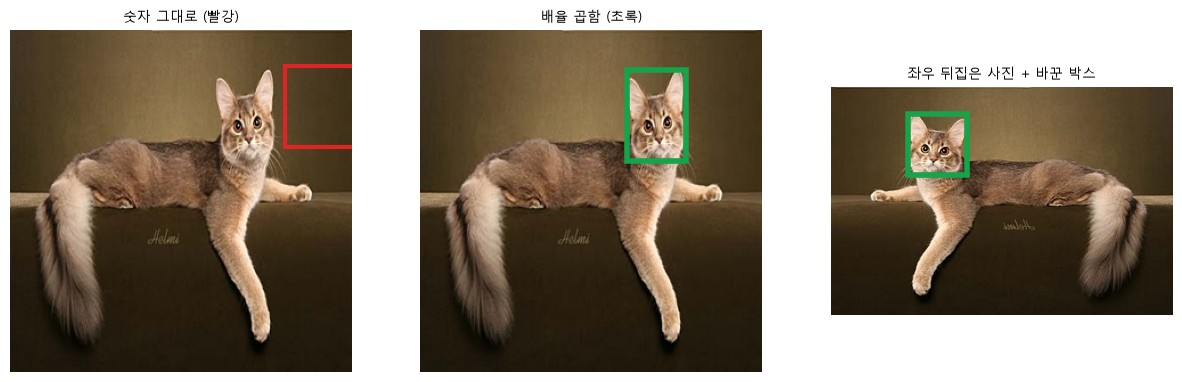

Abyssinian_173       첫 글자 A · 품종 Abyssinian       → xml name ['cat']
Ragdoll_155          첫 글자 R · 품종 Ragdoll          → xml name ['cat']
english_setter_124   첫 글자 e · 품종 english_setter   → xml name ['dog']
boxer_123            첫 글자 b · 품종 boxer            → xml name ['dog']


규칙과 xml name이 맞는 파일: 3686 / 3686


In [45]:
# ---------- 3-3 ----------

# 왜 · 같은 박스를 세 표기로 바꿔 숫자 차이를 보기 위해
b = torch.tensor(boxes)                                      # 모양 [박스 수, 4]
print("xyxy  :", b.tolist())                                 # 두 모서리
print("xywh  :", box_convert(b, "xyxy", "xywh").tolist())    # 왼쪽 위 + 너비 · 높이
print("cxcywh:", box_convert(b, "xyxy", "cxcywh").tolist())  # 가운데 점 + 너비 · 높이

# 왜 · 0~1 비율 표기는 사진 크기로 나눈 값이라는 것을 확인하기 위해
W_img, H_img = cat_img.size                                                     # 사진 크기
w, h = b[0, 2] - b[0, 0], b[0, 3] - b[0, 1]                                     # 얼굴 너비 · 높이
print(f"얼굴 넓이 = {w:.0f} × {h:.0f} → 사진의 {w * h / (W_img * H_img):.1%}")  # 작은 얼굴


# ---------- 3-4 ----------

# 왜 · 사진 크기를 바꾸면 박스도 같은 배율로 바꿔야 한다는 것을 보이기 위해
small = cat_img.resize((300, 300))                              # SSD 입력 크기
sx, sy = 300 / cat_img.size[0], 300 / cat_img.size[1]           # 가로 · 세로 배율
x1, y1, x2, y2 = boxes[0]                                       # 원래 박스
scaled = [x1 * sx, y1 * sy, x2 * sx, y2 * sy]                   # x는 가로 배율 · y는 세로 배율
print(f"가로 배율 {sx:.3f} · 세로 배율 {sy:.3f}")               # 배율이 다름
print("그대로 둔 박스:", boxes[0])                              # 틀린 박스
print("배율 곱한 박스:", [round(v, 1) for v in scaled])         # 맞는 박스
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))               # 3칸
_box(draw(small, title="숫자 그대로 (빨강)", ax=axes[0]), boxes[0], "#dc2626")  # 어긋남
draw(small, gt=[scaled], title="배율 곱함 (초록)", ax=axes[1])  # 맞음

# 왜 · 좌우 뒤집기에서 박스 두 변을 맞바꿔야 한다는 것을 보이기 위해
flipped = ImageOps.mirror(cat_img)                                           # 좌우 뒤집기
W_img = cat_img.size[0]                                                      # 사진 폭
naive = [W_img - x1, y1, W_img - x2, y2]                                     # x만 W - x로 바꿈
fixed = [W_img - x2, y1, W_img - x1, y2]  # 뒤집히면 왼쪽 · 오른쪽 변이 서로 바뀜
print("W - x만 한 박스 :", naive, "→ xmin < xmax ?", naive[0] < naive[2])    # 순서가 뒤집힘
print("변을 바꾼 박스  :", fixed, "→ xmin < xmax ?", fixed[0] < fixed[2])    # 올바름
draw(flipped, gt=[fixed], title="좌우 뒤집은 사진 + 바꾼 박스", ax=axes[2])  # 그림
plt.show()                                                                   # 그림 출력


# ---------- 3-5 ----------
# 왜 · 파일 이름 첫 글자와 XML 이름의 관계를 사진 몇 장으로 확인하기 위해
for stem in ["Abyssinian_173", "Ragdoll_155", "english_setter_124", "boxer_123"]:  # 4장
    breed = stem.rsplit("_", 1)[0]  # 파일명 = 품종_번호
    _, names = read_voc(XMLS / f"{stem}.xml")                                      # XML 이름
    print(f"{stem:20s} 첫 글자 {stem[0]} · 품종 {breed:16s} → xml name {names}")   # 비교

# 왜 · 그 규칙이 XML 전체에서도 맞는지 세어 보기 위해
match, total = 0, 0                                       # 규칙이 맞는 수 · 전체
for p in XMLS.glob("*.xml"):                              # XML 전부
    _, names = read_voc(p)                                # 이름
    rule = "cat" if p.stem[0].isupper() else "dog"        # 대문자 = 고양이 · 소문자 = 개
    match += all(n == rule for n in names)                # 규칙과 같은가
    total += 1                                            # 전체 수
print(f"규칙과 xml name이 맞는 파일: {match} / {total}")  # 모두 맞음

**실행 흐름**

1. 4-1 IoU 손계산 · box_iou
2. 4-2 같은 10픽셀
3. 4-3 모델 박스 vs 정답 박스

In [46]:
from torchvision.ops import box_iou  # 박스 표의 IoU


# ---------- 4-1 ----------

# 왜 · IoU 공식을 손으로 따라가며 계산하기 위해
gt = [100, 100, 200, 200]                              # 정답 박스 (xmin, ymin, xmax, ymax)
pred = [150, 100, 250, 200]                            # 예측 박스: 오른쪽으로 반만 밀림
w = min(gt[2], pred[2]) - max(gt[0], pred[0])          # 겹친 부분 가로
h = min(gt[3], pred[3]) - max(gt[1], pred[1])          # 겹친 부분 세로
inter = max(w, 0) * max(h, 0)                          # 안 겹치면 0
area_gt = (gt[2] - gt[0]) * (gt[3] - gt[1])            # 정답 넓이
area_pred = (pred[2] - pred[0]) * (pred[3] - pred[1])  # 예측 넓이
union = area_gt + area_pred - inter                    # 겹친 부분은 한 번만
print("겹친 넓이:", inter)                             # 5000
print("합친 넓이:", union)                             # 15000
print("IoU      :", round(inter / union, 2))           # 0.33

# 왜 · 손계산 결과를 box_iou로 검증하기 위해
gt_t = torch.tensor([gt], dtype=torch.float)          # 정답 1개
preds = torch.tensor([[110, 100, 210, 200],           # A 조금 밀기
                      [150, 100, 250, 200],           # B 반만 밀기
                      [79.3, 79.3, 220.7, 220.7],     # C 넓이 두 배
                      [114.6, 114.6, 185.4, 185.4]])  # D 넓이 반
print(box_iou(gt_t, preds).round(decimals=2))         # 행 = 정답, 열 = 예측


# ---------- 4-2 ----------
# 왜 · 같은 10픽셀 오차도 박스 크기에 따라 IoU가 달라지는 것을 보이기 위해
big = torch.tensor([[100, 100, 200, 200]], dtype=torch.float)    # 한 변 100 박스
small = torch.tensor([[100, 100, 120, 120]], dtype=torch.float)  # 한 변 20 박스
shift = torch.tensor([10, 0, 10, 0])                             # 오른쪽으로 10픽셀
print("큰 박스   10픽셀 밀기 → IoU", round(box_iou(big, big + shift).item(), 2))  # 10%만 밀림
print("작은 박스 10픽셀 밀기 → IoU", round(box_iou(small, small + shift).item(), 2))  # 절반이 밀림


# ---------- 4-3 ----------
# 왜 · 넓이 · 겹침을 직접 계산해 IoU와 '정답 안에 든 비율'을 비교하기 위해
def area(b):                              # 박스 넓이
    return (b[2] - b[0]) * (b[3] - b[1])  # 너비 × 높이


def overlap(a, b):                         # 겹친 넓이
    w = min(a[2], b[2]) - max(a[0], b[0])  # 겹친 가로
    h = min(a[3], b[3]) - max(a[1], b[1])  # 겹친 세로
    return max(w, 0) * max(h, 0)           # 음수면 0

겹친 넓이: 5000
합친 넓이: 15000
IoU      : 0.33
tensor([[0.8200, 0.3300, 0.5000, 0.5000]])
큰 박스   10픽셀 밀기 → IoU 0.82
작은 박스 10픽셀 밀기 → IoU 0.33


**실행 흐름**

1. 4-3 몸 박스 · 머리 박스 비교 그림

[Russian_Blue_123] 예측: cat 0.99 [154, 82, 328, 354]
[Russian_Blue_123] 정답: ['cat'] [[246.0, 82.0, 334.0, 176.0]]
[Russian_Blue_123] IoU: [0.16]


[Birman_164] 예측: cat 0.97 [5, 2, 349, 313]
[Birman_164] 정답: ['cat'] [[45.0, 10.0, 315.0, 309.0]]
[Birman_164] IoU: [0.76]


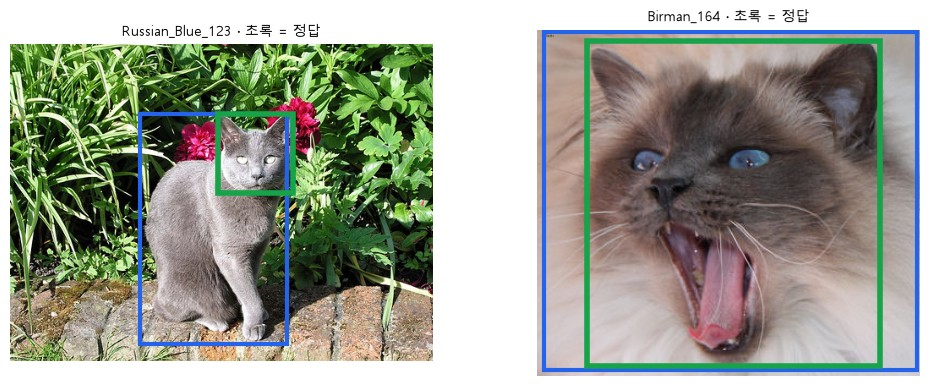

Russian_Blue_123  예측 넓이 = 정답의 5.7배 · 정답이 예측 안에 0.93 · IoU 0.16
Birman_164        예측 넓이 = 정답의 1.3배 · 정답이 예측 안에 1.00 · IoU 0.76


In [47]:
# 왜 · 실제 사진에서 모델 박스와 정답 박스를 모아 비교하기 위해
rows = []  # (사진, 예측 박스, 정답 박스)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))                           # 두 사진
for stem, ax in zip(["Russian_Blue_123", "Birman_164"], axes):              # 사진마다
    img = load_image(stem)                                                  # 사진
    gt_boxes, gt_names = read_voc(XMLS / f"{stem}.xml")                     # 머리 정답
    with torch.no_grad():                                                   # 예측만
        o = detector([det_w.transforms()(img)])[0]                          # SSD 예측
    keep = o["scores"] > 0.5  # 점수 높은 것만 (점수의 뜻은 5장)
    pred_boxes = o["boxes"][keep]                                           # 남은 박스
    for b, lb, s in zip(pred_boxes, o["labels"][keep], o["scores"][keep]):  # 예측마다
        # 몸 박스
        print(f"[{stem}] 예측:", COCO[lb], round(s.item(), 2), [round(v) for v in b.tolist()])
    print(f"[{stem}] 정답:", gt_names, gt_boxes)                            # 머리 박스
    iou = box_iou(pred_boxes, torch.tensor(gt_boxes, dtype=torch.float))    # 예측 × 정답
    print(f"[{stem}] IoU:", [round(v, 2) for v in iou.flatten().tolist()])  # 겹침
    draw(img, gt=gt_boxes, pred=pred_boxes.tolist(), title=f"{stem} · 초록 = 정답", ax=ax)  # 그림
    rows.append((stem, pred_boxes[0].tolist(), gt_boxes[0]))                # 아래 비교용
plt.show()                                                                  # 그림 출력

# 왜 · 정답이 머리라 몸 박스는 IoU가 낮게 나오는 이유를 숫자로 보기 위해
for name, p, g in rows:                                                 # 왜 0.16과 0.76인가
    inside = overlap(p, g) / area(g)                                    # 정답 중 예측 안에 든 비율
    iou_v = overlap(p, g) / (area(p) + area(g) - overlap(p, g))         # IoU
    print(f"{name:17s} 예측 넓이 = 정답의 {area(p) / area(g):.1f}배 ·"  # 넓이 배수 · 포함 · IoU
          f" 정답이 예측 안에 {inside:.2f} · IoU {iou_v:.2f}")

**실행 흐름**

1. 5-1 신뢰도 임곗값
2. 5-2 NMS 전 후보

In [48]:
import copy                              # 모델 복사
from torchvision.ops import nms          # 클래스를 모르는 NMS
from torchvision.ops import batched_nms  # 클래스별 NMS


# ---------- 5-1 ----------
# 왜 · 신뢰도 임곗값에 따라 남는 박스 수가 바뀌는 것을 보기 위해
stem = "Birman_151"                                               # 버먼 고양이
img = load_image(stem)                                            # 사진
with torch.no_grad():                                             # 예측만
    out = detector([det_w.transforms()(img)])[0]                  # 200줄
print("출력 박스 수:", len(out["scores"]))                        # 200
for lb, s in zip(out["labels"][:5], out["scores"][:5]):           # 앞 5줄
    print(f"  {COCO[lb]:12s} {s:.3f}")                            # 이름 · 신뢰도
for thr in [0.5, 0.25, 0.01]:                                     # 기준 세 가지
    print(f"점수 > {thr}: {int((out['scores'] > thr).sum())}개")  # 남는 수

# 왜 · 다른 사진에서도 같은 경향인지 확인하기 위해
for st in ["Russian_Blue_123", "Birman_164"]:         # 4장의 두 사진
    im = load_image(st)                               # 사진
    g, _ = read_voc(XMLS / f"{st}.xml")               # 정답
    with torch.no_grad():                             # 예측만
        o = detector([det_w.transforms()(im)])[0]     # 예측
    top_box, top_s = o["boxes"][:1], o["scores"][0]   # 점수 1등 박스
    iou_v = box_iou(top_box, torch.tensor(g)).item()  # 정답과 겹침
    # 다른 숫자
    print(f"{st:17s} {COCO[o['labels'][0]]} 신뢰도 {top_s:.2f} · 정답과 IoU {iou_v:.2f}")


# ---------- 5-2 ----------

# 왜 · 원본 모델은 그대로 두고 NMS 전 후보만 꺼내 보기 위해
raw = copy.deepcopy(detector)                   # 원래 모델은 그대로, 복사본만 바꿈
raw.nms_thresh = 1.0                            # IoU > 1.0인 경우는 없음 → NMS가 아무것도 안 지움
raw.detections_per_img = 10**6                  # 최대 200개 제한도 풂
with torch.no_grad():                           # 예측만
    before = raw([det_w.transforms()(img)])[0]  # NMS 직전 후보
thr = 0.3                                       # 볼 점수 기준
print("NMS 직전 (점수 > 0.3):", int((before["scores"] > thr).sum()), "개")  # 많음
print("NMS 후 (점수 > 0.3):", int((out["scores"] > thr).sum()), "개")  # 적음

# 왜 · 고양이 후보만 골라 NMS 전후를 비교하기 위해
label_id = COCO.index("cat")                                                  # cat 번호
sel = (before["labels"] == label_id) & (before["scores"] > thr)               # cat 후보만
b, s = before["boxes"][sel], before["scores"][sel]                            # 점수 높은 순
print("cat 후보 점수:", [round(v, 2) for v in s.tolist()])                    # 5개
print("1등과 IoU   :", [round(v, 2) for v in box_iou(b[:1], b)[0].tolist()])  # 많이 겹침

출력 박스 수: 200
  cat          0.845
  cat          0.344
  suitcase     0.266
  book         0.094
  book         0.093
점수 > 0.5: 1개
점수 > 0.25: 3개
점수 > 0.01: 200개


Russian_Blue_123  cat 신뢰도 0.99 · 정답과 IoU 0.16


Birman_164        cat 신뢰도 0.97 · 정답과 IoU 0.76


NMS 직전 (점수 > 0.3): 5 개
NMS 후 (점수 > 0.3): 2 개
cat 후보 점수: [0.84, 0.83, 0.82, 0.8, 0.34]
1등과 IoU   : [1.0, 0.93, 0.81, 0.85, 0.39]


**실행 흐름**

1. 5-3 NMS 한 단계씩
2. 5-4 NMS 기준 · 못 하는 것

In [49]:
# ---------- 5-3 ----------

# 같은 클래스라고 가정한 장난감 후보 (nms는 클래스를 받지 않음)
# 왜 · 작은 예로 NMS가 무엇을 지우는지 손으로 따라가기 위해
boxes = torch.tensor([[100, 100, 200, 200], [105, 102, 205, 198], [98, 95, 195, 205],  # 물체 1 근처
                      [110, 110, 210, 210], [90, 100, 190, 200],
                      [400, 100, 480, 220]], dtype=torch.float)  # 물체 2
scores = torch.tensor([0.95, 0.90, 0.85, 0.80, 0.70, 0.88])      # 점수
print("0번과 IoU:", [round(v, 2) for v in box_iou(boxes[:1], boxes)[0].tolist()])  # 겹침 정도
keep = nms(boxes, scores, iou_threshold=0.5)                     # 0.5 넘게 겹치면 지움
print("남은 번호:", keep.tolist())                               # 물체마다 하나

# 왜 · NMS를 한 단계씩 직접 실행해 라이브러리 결과와 맞춰 보기 위해
remain = list(range(len(s)))                      # 버먼 고양이 NMS 직전 cat 후보 5개 (점수 순)
step = 1                                          # 단계 번호
while remain:                                     # 후보가 남아 있는 동안
    top = remain[0]                               # 남은 것 중 1등
    ious = box_iou(b[top:top + 1], b[remain])[0]  # 1등과 남은 후보의 IoU
    gone = [i for i, v in zip(remain, ious.tolist()) if i != top and v > 0.45]  # 지울 후보
    # 한 단계
    print(f"{step}단계: {s[top]:.2f} 남김 · 지움 {[round(s[i].item(), 2) for i in gone]}")
    remain = [i for i in remain if i != top and i not in gone]  # 남은 후보
    step += 1                                     # 다음 단계

# 왜 · 실제 사진에서 모델 안 NMS 결과와 직접 NMS 결과를 비교하기 위해
sel_a = (out["labels"] == label_id) & (out["scores"] > thr)  # 모델 출력(NMS 뒤)의 cat
b_a = out["boxes"][sel_a]                                    # 남은 박스
# 직접 한 결과와 같음
print("NMS 뒤 cat 점수:", [round(v, 2) for v in out["scores"][sel_a].tolist()])
print("둘 사이 IoU    :", [round(v, 2) for v in box_iou(b_a[:1], b_a)[0].tolist()])  # 0.45 미만


# ---------- 5-4 ----------

# 왜 · NMS 기준을 바꾸면 남는 박스 수가 어떻게 바뀌는지 보기 위해
cand = before["scores"] > thr            # NMS 직전 후보 중 점수 > 0.3
for t in [0.3, 0.45, 0.7]:               # NMS 기준 세 가지
    # 정리
    keep = batched_nms(before["boxes"][cand], before["scores"][cand], before["labels"][cand], t)
    kept = before["scores"][cand][keep]  # 남은 점수
    print(f"NMS 기준 {t}: 남은 점수 {[round(v, 2) for v in kept.tolist()]}")  # 기준마다

# 왜 · 몸 박스 · 머리 박스처럼 덜 겹치는 중복은 NMS가 못 지운다는 것을 보이기 위해
body = [100, 100, 200, 300]                                         # 고양이 몸 전체 박스
head = [100, 100, 200, 170]                                         # 같은 고양이 머리 박스
b2 = torch.tensor([body, head], dtype=torch.float)                  # 두 박스
s2 = torch.tensor([0.9, 0.8])                                       # 점수
print("몸 vs 머리 IoU:", round(box_iou(b2[:1], b2[1:]).item(), 2))  # 0.35
print("NMS(0.5) 뒤 남은 번호:", nms(b2, s2, 0.5).tolist())          # 둘 다 남음

# 왜 · 클래스가 다르면 같은 자리 박스도 남는다는 것을 보이기 위해
same = torch.tensor([[0, 0, 10, 10], [0, 0, 10, 10]], dtype=torch.float)  # 완전히 같은 박스 2개
sc = torch.tensor([0.9, 0.6])                                                     # 점수
print("같은 클래스:", batched_nms(same, sc, torch.tensor([1, 1]), 0.5).tolist())  # 하나 지움
print("다른 클래스:", batched_nms(same, sc, torch.tensor([1, 2]), 0.5).tolist())  # 둘 다 남음

0번과 IoU: [1.0, 0.87, 0.85, 0.68, 0.82, 0.0]
남은 번호: [0, 5]
1단계: 0.84 남김 · 지움 [0.83, 0.82, 0.8]
2단계: 0.34 남김 · 지움 []
NMS 뒤 cat 점수: [0.84, 0.34]
둘 사이 IoU    : [1.0, 0.39]
NMS 기준 0.3: 남은 점수 [0.84]
NMS 기준 0.45: 남은 점수 [0.84, 0.34]
NMS 기준 0.7: 남은 점수 [0.84, 0.34]
몸 vs 머리 IoU: 0.35
NMS(0.5) 뒤 남은 번호: [0, 1]
같은 클래스: [0]
다른 클래스: [0, 1]


**실행 흐름**

1. 5-5 detect 한 함수로 최종 박스

① 후보       : 462
② 점수 거른 뒤: 9
③ NMS 뒤     : 1
예측: dog 0.998 [96, 39, 448, 302]
정답: ['dog'] [[331.0, 72.0, 446.0, 199.0]]
IoU : [0.16]


① 후보       : 462
② 점수 거른 뒤: 12
③ NMS 뒤     : 2
최종: dog 0.998
최종: umbrella 0.177


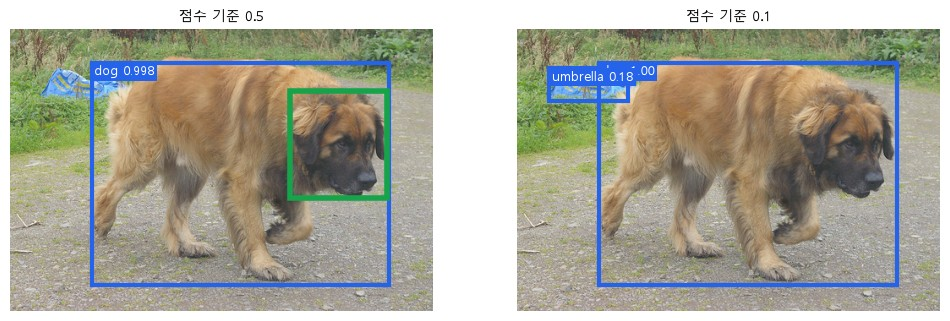

In [50]:
# ---------- 5-5 ----------
# 왜 · 신뢰도 거르기 → NMS를 한 함수로 이어 사진에서 최종 박스까지 얻기 위해
def detect(img, score_thr=0.5, iou_thr=0.45):           # 사진 → 최종 박스
    with torch.no_grad():                               # 예측만
        cand = raw([det_w.transforms()(img)])[0]        # ① 후보 (NMS 직전)
    print("① 후보       :", len(cand["scores"]))        # 후보 수
    keep = cand["scores"] > score_thr                   # ② 점수로 거르기
    # 남은 것
    boxes, scores, labels = cand["boxes"][keep], cand["scores"][keep], cand["labels"][keep]
    print("② 점수 거른 뒤:", len(scores))               # 남은 수
    keep = batched_nms(boxes, scores, labels, iou_thr)  # ③ 클래스별 NMS
    print("③ NMS 뒤     :", len(keep))                  # 최종 수
    return boxes[keep], scores[keep], labels[keep]      # 최종 박스


# 왜 · 한 함수로 얻은 결과가 모델 출력과 같은지 확인하기 위해
stem = "leonberger_142"                                                           # 레온베르거 개
img = load_image(stem)                                                            # 사진
boxes_f, scores_f, labels_f = detect(img)                                         # 기본 기준
gt_boxes, gt_names = read_voc(XMLS / f"{stem}.xml")                               # 머리 정답
for b, s, lb in zip(boxes_f, scores_f, labels_f):                                 # 최종 예측
    print("예측:", COCO[lb], round(s.item(), 3), [round(v) for v in b.tolist()])  # 몸 박스
print("정답:", gt_names, gt_boxes)                                                # 머리 박스
iou = box_iou(boxes_f, torch.tensor(gt_boxes, dtype=torch.float))                 # 겹침
print("IoU :", [round(v, 2) for v in iou.flatten().tolist()])                     # 낮음

# 왜 · 임곗값을 낮추면 잘못된 박스가 섞이는 것을 보기 위해
boxes_lo, scores_lo, labels_lo = detect(img, score_thr=0.1)           # 점수 기준만 0.1로 낮춤
for s, lb in zip(scores_lo, labels_lo):                               # 최종 예측
    print("최종:", COCO[lb], round(s.item(), 3))                      # 엉뚱한 클래스가 들어옴
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))                     # 두 기준 비교
draw(img, gt=gt_boxes, pred=boxes_f.tolist(), ax=axes[0], title="점수 기준 0.5",  # 기본
     labels=[f"{COCO[lb]} {s:.3f}" for s, lb in zip(scores_f, labels_f)])
draw(img, pred=boxes_lo.tolist(), ax=axes[1], title="점수 기준 0.1",  # 낮춤
     labels=[f"{COCO[lb]} {s:.2f}" for s, lb in zip(scores_lo, labels_lo)])
plt.show()                                                            # 그림 출력

**실행 흐름**

1. 6-1 R-CNN 창문 수 · 시간
2. 6-2 Faster R-CNN 부품 · RPN

In [51]:
from torchvision.models import resnet18                           # 시간만 잴 CNN
from torchvision.models.detection import fasterrcnn_resnet50_fpn  # 2단계 탐지기
from torchvision.io import decode_image                           # 파일 → uint8 텐서


# ---------- 6-1 ----------

# 왜 · R-CNN 방식의 창문 수를 실제 사진 크기로 세기 위해
img_a = Image.open(IMAGES / "Abyssinian_140.jpg")  # 고양이 사진
W_img, H_img = img_a.size                          # 사진 크기


# 왜 · 창문 간격에 따라 분류 횟수가 얼마나 늘어나는지 세기 위해
def count_windows(stride):                  # stride 픽셀씩 옮길 때 창문 수
    n = 0                                   # 창문 수
    for size in (64, 128, 256):             # 창문 크기 3가지
        for ratio in (0.5, 1, 2):           # 창문 모양 3가지 (세로 ÷ 가로)
            w, h = int(size / ratio ** 0.5), int(size * ratio ** 0.5)  # 너비 · 높이
            nx = (W_img - w) // stride + 1  # 가로로 놓이는 수
            ny = (H_img - h) // stride + 1  # 세로로 놓이는 수
            n += max(nx, 0) * max(ny, 0)    # 사진보다 크면 0
    return n                                # 전체 창문 수


# 왜 · 간격별 창문 수를 비교하기 위해
print("사진 크기:", img_a.size)                                           # (500, 333)
for stride in (32, 16, 8):                                                # 촘촘할수록
    print(f"{stride:>2}픽셀씩 옮기면 창문 {count_windows(stride):>5}개")  # 창문이 늘어남
count = count_windows(16)                                                 # 16픽셀 기준

# 왜 · 창문 하나 분류 시간을 재어 전체 시간을 어림하기 위해
cnn = resnet18(weights=None).eval()   # 시간만 재는 용도 (학습 안 된 CNN)
crop = torch.rand(1, 3, 224, 224)     # 창문 하나를 잘라 224×224로 맞춘 것
with torch.no_grad():                 # 예측만
    cnn(crop)                         # 첫 실행은 준비 시간이라 빼고 잼
    t = time.perf_counter()           # 시작
    for _ in range(20):               # 20번 평균
        cnn(crop)                     # CNN 한 번
one = (time.perf_counter() - t) / 20  # 한 번 시간
print(f"창문 1개  : {one * 1000:.0f} ms · 창문 {count}개: 약 {one * count:.0f} 초"  # 사진 한 장
      " (컴퓨터마다 다름)")


# ---------- 6-2 ----------

# 왜 · 가중치 없이 구조만 만들어 Faster R-CNN의 부품을 확인하기 위해
frcnn = fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None).eval()  # 구조만 · 가중치 없음
for name, part in frcnn.named_children():                                    # 큰 부품
    print(f"{name:10s} → {type(part).__name__}")                             # 이름 → 종류

# 왜 · RPN이 후보를 만드는 앵커 설정을 직접 보기 위해
gen = frcnn.rpn.anchor_generator                                                      # RPN의 앵커
print("RPN 앵커 크기       :", [s_[0] for s_ in gen.sizes])                           # 크기 5가지
print("RPN 앵커 모양(세로÷가로):", gen.aspect_ratios[0])                              # 모양 3가지
print("RPN이 넘기는 후보 수:", frcnn.rpn.post_nms_top_n())                            # 1000
print("최종 분류 칸 수     :", frcnn.roi_heads.box_predictor.cls_score.out_features)  # 91

사진 크기: (500, 333)
32픽셀씩 옮기면 창문   654개
16픽셀씩 옮기면 창문  2496개
 8픽셀씩 옮기면 창문  9733개


창문 1개  : 96 ms · 창문 2496개: 약 240 초 (컴퓨터마다 다름)


transform  → GeneralizedRCNNTransform
backbone   → BackboneWithFPN
rpn        → RegionProposalNetwork
roi_heads  → RoIHeads
RPN 앵커 크기       : [32, 64, 128, 256, 512]
RPN 앵커 모양(세로÷가로): (0.5, 1.0, 2.0)
RPN이 넘기는 후보 수: 1000
최종 분류 칸 수     : 91


**실행 흐름**

1. 6-3 SSD 특징 맵 · 디폴트 박스
2. 6-4 클래스 점수 · 박스 보정값
3. 6-5 출발점 → 보정

In [52]:
# ---------- 6-3 ----------
# 왜 · SSD 구조를 실제 모델에서 열어 보기 위해
SSD_W = SSD300_VGG16_Weights.COCO_V1              # COCO로 학습된 가중치
ssd = ssd300_vgg16(weights=SSD_W).eval()          # 4장까지의 detector와 같은 모델
categories = SSD_W.meta["categories"]             # 91칸 이름
for name, part in ssd.named_children():           # 큰 부품
    print(f"{name:17s} → {type(part).__name__}")  # 이름 → 종류

# 왜 · 특징 맵 6장의 크기를 모양만으로 확인하기 위해
xr = torch.rand(1, 3, 300, 300)                # 300×300 가짜 이미지 한 장
with torch.no_grad():                          # 모양만 확인
    feats = ssd.backbone(xr)                   # 특징 맵 여러 장
for k, f in feats.items():                     # 맵마다
    _, c, h, w = f.shape                       # 채널 · 크기
    print(f"맵 {k}: {h:>2}×{w:<2}  채널 {c}")  # 38 · 19 · 10 · 5 · 3 · 1

# 왜 · 디폴트 박스가 모두 몇 개인지 손으로 세어 보기 위해
per_cell = ssd.anchor_generator.num_anchors_per_location()    # 칸마다 디폴트 박스 수
total = 0                                                     # 전체 디폴트 박스
for f, a in zip(feats.values(), per_cell):                    # 맵마다
    h, w = f.shape[-2:]                                       # 맵 크기
    print(f"{h:>2}×{w:<2} 칸 × 박스 {a}개 = {h * w * a:>5}")  # 맵별 박스 수
    total += h * w * a                                        # 더하기
print("디폴트 박스 전체:", total)                             # 8732


# ---------- 6-4 ----------
# 왜 · 디폴트 박스마다 클래스 점수와 박스 보정값이 나온다는 것을 확인하기 위해
cls_head = ssd.head.classification_head                                    # 클래스 점수 층
box_head = ssd.head.regression_head                                        # 위치 보정 층
for c, r, a in zip(cls_head.module_list, box_head.module_list, per_cell):  # 맵마다
    # 분류
    print(f"박스 {a}개 · 분류 Conv2d({c.in_channels}→{c.out_channels}) = {a}×{c.out_channels // a}"
          f" · 위치 Conv2d({r.in_channels}→{r.out_channels}) = {a}×4")
print("클래스 수:", len(categories), categories[:3])                       # 91

with torch.no_grad():                                                 # 모양만 확인
    head_out = ssd.head(list(feats.values()))                         # 8732개 박스의 점수 · 보정값
print("클래스 점수 모양:", tuple(head_out["cls_logits"].shape))       # (1, 8732, 91)
print("위치 보정 모양  :", tuple(head_out["bbox_regression"].shape))  # (1, 8732, 4)


# ---------- 6-5 ----------


# 왜 · 디폴트 박스가 보정값으로 최종 박스가 되는 과정을 보기 위해
def start_to_fixed(stem, name):  # 디폴트 박스(출발점)에서 보정 후 박스까지
    img_t = SSD_W.transforms()(decode_image(str(IMAGES / f"{stem}.jpg")))  # 0~1 텐서
    with torch.no_grad():                                       # 예측만
        image_list, _ = ssd.transform([img_t])                  # 300×300으로 맞춤
        maps = list(ssd.backbone(image_list.tensors).values())  # 특징 맵
        raw_out = ssd.head(maps)                                # 8732개 박스의 점수 · 보정값
        anchors = ssd.anchor_generator(image_list, maps)[0]     # 디폴트 박스 좌표 (300 기준)
        fixed = ssd.box_coder.decode_single(raw_out["bbox_regression"][0], anchors)  # 보정 적용
    probs = raw_out["cls_logits"][0].softmax(-1)                # 박스마다 91칸 확률
    score = probs[:, categories.index(name)]                    # 그 클래스 점수
    # 대부분 배경
    print(f"[{stem}] 배경이 1등인 박스: {int((probs.argmax(-1) == 0).sum())} / {len(probs)}"
          f" · {name} 점수 > 0.5 박스: {int((score > 0.5).sum())}")
    for i in score.topk(3).indices.tolist():                    # 점수 상위 3개
        # 출발 → 보정
        print(f"  {name} {score[i]:.2f}  출발 {[round(v) for v in anchors[i].tolist()]}"
              f" → 보정 후 {[round(v) for v in fixed[i].tolist()]}")
    return anchors, fixed, score                                # 아래에서 씀

backbone          → SSDFeatureExtractorVGG
anchor_generator  → DefaultBoxGenerator
head              → SSDHead
transform         → GeneralizedRCNNTransform


맵 0: 38×38  채널 512
맵 1: 19×19  채널 1024
맵 2: 10×10  채널 512
맵 3:  5×5   채널 256
맵 4:  3×3   채널 256
맵 5:  1×1   채널 256
38×38 칸 × 박스 4개 =  5776
19×19 칸 × 박스 6개 =  2166
10×10 칸 × 박스 6개 =   600
 5×5  칸 × 박스 6개 =   150
 3×3  칸 × 박스 4개 =    36
 1×1  칸 × 박스 4개 =     4
디폴트 박스 전체: 8732
박스 4개 · 분류 Conv2d(512→364) = 4×91 · 위치 Conv2d(512→16) = 4×4
박스 6개 · 분류 Conv2d(1024→546) = 6×91 · 위치 Conv2d(1024→24) = 6×4
박스 6개 · 분류 Conv2d(512→546) = 6×91 · 위치 Conv2d(512→24) = 6×4
박스 6개 · 분류 Conv2d(256→546) = 6×91 · 위치 Conv2d(256→24) = 6×4
박스 4개 · 분류 Conv2d(256→364) = 4×91 · 위치 Conv2d(256→16) = 4×4
박스 4개 · 분류 Conv2d(256→364) = 4×91 · 위치 Conv2d(256→16) = 4×4
클래스 수: 91 ['__background__', 'person', 'bicycle']
클래스 점수 모양: (1, 8732, 91)
위치 보정 모양  : (1, 8732, 4)


**실행 흐름**

1. 6-6 디폴트 박스 짝짓기
2. 6-7 학습 손실 두 가지

In [53]:
# 왜 · 고양이 · 개 사진에서 출발 박스와 보정된 박스를 비교하기 위해
anchors, fixed_cat, cat_score = start_to_fixed("Abyssinian_140", "cat")  # 고양이
_ = start_to_fixed("chihuahua_138", "dog")                               # 두 번째 사진: 개


# ---------- 6-6 ----------
# 왜 · 정답 박스를 300×300 기준으로 바꿔 디폴트 박스와 비교하기 위해
def read_gt(stem):  # 첫 정답 박스 · 사진 크기
    root = ET.parse(XMLS / f"{stem}.xml").getroot()                                  # XML
    w, h = int(root.findtext("size/width")), int(root.findtext("size/height"))       # 크기
    bnd = root.find("object/bndbox")                                                 # 첫 박스
    return [float(bnd.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")], w, h  # 박스 · 크기


# 왜 · 학습 때 디폴트 박스와 정답을 IoU로 짝짓는 규칙을 직접 해 보기 위해
def match_anchors(stem):                                   # 정답과 IoU 0.5 이상인 디폴트 박스
    (x1, y1, x2, y2), w, h = read_gt(stem)                 # 정답
    g = torch.tensor([[x1 * 300 / w, y1 * 300 / h, x2 * 300 / w, y2 * 300 / h]])  # 300 기준 정답
    iou = box_iou(g, anchors)[0]                           # 디폴트 박스 8732개와 IoU
    return int((iou >= 0.5).sum()), float(iou.max()), iou  # 양성 수 · 최고 · 전체


# 왜 · 짝지어진 디폴트 박스가 어느 특징 맵에서 왔는지 알기 위해
map_of = torch.cat([torch.full((f.shape[-1] ** 2 * a,), f.shape[-1])  # 박스마다 어느 맵 출신인지
                    for f, a in zip(feats.values(), per_cell)])
for stem in ["Abyssinian_140", "boxer_123", "basset_hound_131"]:      # 세 사진
    n, best, iou = match_anchors(stem)                                # 짝
    used = sorted(set(map_of[iou >= 0.5].tolist()), reverse=True)     # 짝이 나온 맵
    print(f"{stem:17s} IoU≥0.5 디폴트 박스 {n:2d}개 · 맵 {used} · 최고 IoU {best:.3f}")  # 결과

# 왜 · 정답 하나에 짝지어진 디폴트 박스 수를 세기 위해
n, _, iou = match_anchors("Abyssinian_140")                                          # 고양이 머리
positive = iou >= 0.5  # 머리 정답과 짝지어진 디폴트 박스
top = int(cat_score.argmax())  # COCO 모델이 cat 점수를 가장 높게 준 박스
(x1, y1, x2, y2), w, h = read_gt("Abyssinian_140")                                   # 정답
head_box = torch.tensor([[x1 * 300 / w, y1 * 300 / h, x2 * 300 / w, y2 * 300 / h]])  # 300 기준
print(f"양성 박스 {n}개의 cat 점수: 가장 높아도 {cat_score[positive].max():.3f}")    # 낮음
print(f"cat 점수 1등 박스: {cat_score[top]:.2f} · 보정 후 박스와 머리 정답의 IoU"    # 몸 박스
      f" {box_iou(fixed_cat[top:top + 1], head_box).item():.2f}")

# 왜 · 전체 XML에서 짝 수와 특징 맵 분포를 보기 위해
stems = [p.stem for p in sorted(XMLS.glob("*.xml"))]  # 정답 전부
counts, best_maps = [], []                            # 정답마다 양성 수 · 가장 잘 맞는 맵
for st in stems:                                      # 3686개
    n, _, iou = match_anchors(st)                     # 짝
    counts.append(n)                                  # 양성 수
    best_maps.append(int(map_of[iou.argmax()]))       # 가장 잘 맞는 박스의 맵
print("정답 박스 수        :", len(counts))           # 3686
print("가장 잘 맞는 박스의 맵:", {m: best_maps.count(m) for m in (38, 19, 10, 5, 3, 1)})  # 맵별
# 분포
print("양성 디폴트 박스 수 : 가운데값", sorted(counts)[len(counts) // 2], "· 최대", max(counts))
print("0.5 넘는 박스 0개   :", sum(c == 0 for c in counts), "개")  # 짝이 없는 정답


# ---------- 6-7 ----------
# 왜 · 학습 모드 SSD가 내는 두 가지 손실을 확인하기 위해
box_gt, w, h = read_gt("Abyssinian_140")                        # 첫 정답
img_t = SSD_W.transforms()(decode_image(str(IMAGES / "Abyssinian_140.jpg")))  # 사진 텐서
target = [{"boxes": torch.tensor([box_gt]),                     # 정답 박스
           "labels": torch.tensor([categories.index("cat")])}]  # COCO의 cat 번호
ssd.train()                                                     # 학습 모드: 박스 대신 손실을 돌려줌
losses = ssd([img_t], target)                                   # 손실 두 가지
ssd.eval()                                                      # 다시 평가 모드
print({k: round(v.item(), 3) for k, v in losses.items()})       # 위치 · 분류 손실

[Abyssinian_140] 배경이 1등인 박스: 8725 / 8732 · cat 점수 > 0.5 박스: 6
  cat 0.99  출발 [20, 84, 172, 236] → 보정 후 [5, 65, 195, 243]
  cat 0.99  출발 [7, 71, 185, 249] → 보정 후 [5, 61, 197, 248]
  cat 0.95  출발 [-12, 106, 204, 214] → 보정 후 [13, 70, 197, 243]


[chihuahua_138] 배경이 1등인 박스: 8723 / 8732 · dog 점수 > 0.5 박스: 8
  dog 0.98  출발 [84, 84, 236, 236] → 보정 후 [79, 63, 249, 250]
  dog 0.97  출발 [71, 71, 249, 249] → 보정 후 [78, 66, 256, 251]
  dog 0.96  출발 [106, 52, 214, 268] → 보정 후 [80, 61, 247, 245]
Abyssinian_140    IoU≥0.5 디폴트 박스  6개 · 맵 [19] · 최고 IoU 0.719
boxer_123         IoU≥0.5 디폴트 박스  3개 · 맵 [38] · 최고 IoU 0.565
basset_hound_131  IoU≥0.5 디폴트 박스  0개 · 맵 [] · 최고 IoU 0.499
양성 박스 6개의 cat 점수: 가장 높아도 0.026
cat 점수 1등 박스: 0.99 · 보정 후 박스와 머리 정답의 IoU 0.10


정답 박스 수        : 3686
가장 잘 맞는 박스의 맵: {38: 18, 19: 707, 10: 1654, 5: 867, 3: 275, 1: 165}
양성 디폴트 박스 수 : 가운데값 9 · 최대 21
0.5 넘는 박스 0개   : 9 개


{'bbox_regression': 1.386, 'classification': 8.639}


**실행 흐름**

1. 7-1 목록 세 개 · XML 위치

In [54]:
from collections import Counter                 # 개수 세기
import statistics                               # 가운데값
import torchvision.transforms.functional as TF  # PIL → 텐서


# ---------- 7-1 ----------
# 왜 · 목록 파일에서 사진 이름만 꺼내기 위해
def read_list(name):  # 한 줄 예: "Abyssinian_100 1 1 1" → 앞 이름만
    return [line.split()[0] for line in open(ANN / name)  # 줄마다 첫 칸
            if line.strip() and not line.startswith("#")]


# 왜 · 목록 세 개의 사진 수와 겹침을 확인하기 위해
all_stems = read_list("list.txt")               # 전체 목록
trainval = read_list("trainval.txt")            # 학습 · 검증 목록
test = read_list("test.txt")                    # 공식 test 목록
print("list.txt     :", len(all_stems))         # 7349
print("trainval.txt :", len(trainval))          # 3680
print("test.txt     :", len(test))              # 3669
print("겹침:", len(set(trainval) & set(test)),  # 0
      "· 합치면 list와 같음:", set(trainval) | set(test) == set(all_stems))

# 왜 · 정답 XML이 어느 목록의 사진에 있는지 확인하기 위해
xml_stems = {p.stem for p in XMLS.glob("*.xml")}  # 정답 XML이 있는 이름
print("XML 파일 전체      :", len(xml_stems))     # 3686
# 대부분
print("trainval 중 XML 있음:", sum(s_ in xml_stems for s_ in trainval), "/", len(trainval))
print("test 중 XML 있음    :", sum(s_ in xml_stems for s_ in test), "/", len(test))  # 0

list.txt     : 7349
trainval.txt : 3680
test.txt     : 3669
겹침: 0 · 합치면 list와 같음: True
XML 파일 전체      : 3686
trainval 중 XML 있음: 3671 / 3680
test 중 XML 있음    : 0 / 3669


**실행 흐름**

1. 7-2 XML 전체 읽기 · 박스 점검
2. 7-3 사진 · 얼굴 크기
3. 7-4 클래스 번호 약속

XML 3686 개 · 박스 3687 개
{'이미지 밖으로 나감': 0, 'xmin ≥ xmax': 0, 'ymin ≥ ymax': 0}
XML 안 이름 : {'cat': 1189, 'dog': 2498}
사진당 박스 : {1: 3685, 2: 1}
규칙과 다른 XML: 0
['Bengal_105'] · 크기: 500 × 466
cat [49.0, 125.0, 111.0, 168.0]
cat [397.0, 103.0, 451.0, 132.0]


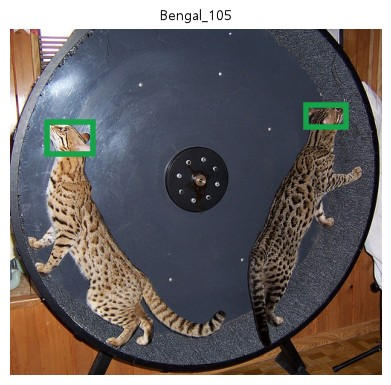

사진 폭  : 114 ~ 3264
사진 높이: 108 ~ 2606
서로 다른 크기: 706 가지
300 기준 얼굴 긴 변: 가장 작은 20 · 가운데 141 · 가장 큰 299
긴 변 50 미만: 41 / 3687


In [55]:
# ---------- 7-2 ----------

# 왜 · 모든 XML을 한 번에 읽어 점검에 쓰기 위해
records = {}                         # 이름 → (폭, 높이, 박스들, 이름들)
for st in sorted(xml_stems):         # XML 전부
    path = XMLS / f"{st}.xml"        # 경로
    root = ET.parse(path).getroot()  # XML
    w, h = int(root.findtext("size/width")), int(root.findtext("size/height"))  # 크기
    bxs, nms_ = read_voc(path)       # 박스 · 이름
    records[st] = (w, h, bxs, nms_)  # 기록

# 왜 · 잘못된 박스가 학습에 들어가지 않게 미리 세어 보기 위해
problems = {"이미지 밖으로 나감": 0, "xmin ≥ xmax": 0, "ymin ≥ ymax": 0}          # 점검 3가지
n_boxes = 0                                                                       # 박스 수
for w, h, bxs, _ in records.values():                                             # 사진마다
    for x1, y1, x2, y2 in bxs:                                                    # 박스마다
        n_boxes += 1                                                              # 세기
        problems["이미지 밖으로 나감"] += (x1 < 0 or y1 < 0 or x2 > w or y2 > h)  # 사진 밖
        problems["xmin ≥ xmax"] += (x1 >= x2)                                     # 가로 순서
        problems["ymin ≥ ymax"] += (y1 >= y2)                                     # 세로 순서
print("XML", len(records), "개 · 박스", n_boxes, "개")                            # 3686 · 3687
print(problems)                                                                   # 모두 0

# 왜 · 클래스 균형과 사진당 박스 수를 확인하기 위해
name_count = Counter(n for _, _, _, ns in records.values() for n in ns)  # 이름별 박스 수
box_per_image = Counter(len(bxs) for _, _, bxs, _ in records.values())   # 사진당 박스 수
print("XML 안 이름 :", dict(name_count))                                 # cat · dog
print("사진당 박스 :", dict(box_per_image))                              # 1개 · 2개
mismatch = [st for st, (_, _, _, ns) in records.items()                  # 파일명 규칙과 다른 XML
            if any((n == "cat") != st[0].isupper() for n in ns)]
print("규칙과 다른 XML:", len(mismatch))                                 # 0

# 왜 · 박스가 둘인 사진을 직접 보고 정답이 맞는지 확인하기 위해
two = [st for st, (_, _, bxs, _) in records.items() if len(bxs) > 1]  # 박스 2개인 사진
w, h, bxs, ns = records[two[0]]                                       # 그 사진
print(two, "· 크기:", w, "×", h)                                      # Bengal_105
for bx, n in zip(bxs, ns):                                            # 박스마다
    print(n, bx)                                                      # 두 고양이
draw(load_image(two[0]), gt=bxs, title=two[0])                        # 그림
plt.show()                                                            # 그림 출력


# ---------- 7-3 ----------

# 왜 · 사진 크기가 제각각이라는 것을 숫자로 확인하기 위해
sizes = [(w, h) for w, h, _, _ in records.values()]                           # 사진 크기들
print("사진 폭  :", min(w for w, _ in sizes), "~", max(w for w, _ in sizes))  # 최소 ~ 최대
print("사진 높이:", min(h for _, h in sizes), "~", max(h for _, h in sizes))  # 최소 ~ 최대
print("서로 다른 크기:", len(set(sizes)), "가지")                             # 크기가 제각각

# 왜 · 얼굴 크기 분포를 보고 작은 물체가 얼마나 있는지 알기 위해
side = []  # SSD 안에서 300×300으로 바뀐 뒤 얼굴 박스의 긴 변
for w, h, bxs, _ in records.values():                               # 사진마다
    for x1, y1, x2, y2 in bxs:                                      # 박스마다
        side.append(max((x2 - x1) / w * 300, (y2 - y1) / h * 300))  # 긴 변
side.sort()                                                         # 작은 순
print("300 기준 얼굴 긴 변: 가장 작은", round(side[0]),             # 최소 · 가운데 · 최대
      "· 가운데", round(statistics.median(side)), "· 가장 큰", round(side[-1]))
print("긴 변 50 미만:", sum(v < 50 for v in side), "/", len(side))  # 아주 작은 얼굴


# ---------- 7-4 ----------

# 왜 · torchvision 탐지 모델이 0번을 배경으로 쓰기 때문에
CLASSES = ["배경", "고양이 얼굴", "개 얼굴"]  # 번호 0, 1, 2
NAME_TO_LABEL = {"cat": 1, "dog": 2}          # 0은 배경 자리 → XML에는 없음

**실행 흐름**

1. 7-4 make_target · 모양 확인
2. 7-5 약속을 어긴 입력의 에러

In [56]:
# 왜 · 탐지 모델이 요구하는 boxes · labels 형식으로 맞추기 위해
def make_target(stem):                                        # XML → 모델이 받는 정답
    bxs, ns = read_voc(XMLS / f"{stem}.xml")                  # 박스 · 이름
    return {"boxes": torch.tensor(bxs, dtype=torch.float32),  # [N, 4] xyxy
            "labels": torch.tensor([NAME_TO_LABEL[n] for n in ns], dtype=torch.int64)}  # [N]


# 왜 · target의 모양 · 자료형이 약속과 맞는지 확인하기 위해
t = make_target("Abyssinian_173")                              # 한 샘플의 정답
print(t)                                                       # boxes · labels
print("boxes :", tuple(t["boxes"].shape), t["boxes"].dtype)    # (1, 4) float32
print("labels:", tuple(t["labels"].shape), t["labels"].dtype)  # (1,) int64
# (2, 4)
print("두 박스 사진:", tuple(make_target(two[0])["boxes"].shape), make_target(two[0])["labels"])

# 왜 · 이미지 텐서의 모양 · 범위가 약속과 맞는지 확인하기 위해
image = TF.to_tensor(load_image("Abyssinian_173"))  # [3, H, W], 0~1 실수
print("image:", tuple(image.shape), image.dtype,    # 모양 · 자료형 · 범위
      round(image.min().item(), 2), "~", round(image.max().item(), 2))


# ---------- 7-5 ----------
# 왜 · 약속을 어긴 입력이 어떤 에러를 내는지 미리 보기 위해
ssd_train = ssd300_vgg16(weights=SSD300_VGG16_Weights.COCO_V1).train()  # 학습 모드: target을 받음
image = torch.rand(3, 267, 400)                                                     # 가짜 사진
broken = {"labels를 실수로": {"boxes": t["boxes"], "labels": t["labels"].float()},  # 약속 어김 1
          "boxes를 한 줄로": {"boxes": t["boxes"][0], "labels": t["labels"]}}       # 약속 어김 2
for name, target in broken.items():                                                 # 경우마다
    try:
        ssd_train([image], [target])                                                # 손실 계산 시도
        print(name, "→ 그냥 돌아감")                                                # 통과하면
    except Exception as e:                                                          # 막히면
        print(name, "→", type(e).__name__, ":", str(e).splitlines()[0][:95])        # 에러 첫 줄

{'boxes': tensor([[241.,  31., 310., 102.]]), 'labels': tensor([1])}
boxes : (1, 4) torch.float32
labels: (1,) torch.int64
두 박스 사진: (2, 4) tensor([1, 1])
image: (3, 267, 400) torch.float32 0.0 ~ 1.0


labels를 실수로 → RuntimeError : expected scalar type Long but found Float
boxes를 한 줄로 → AssertionError : Expected target boxes to be a tensor of shape [N, 4], got torch.Size([4]).


**실행 흐름**

1. 8-1 YOLO 격자 · 클래스 수
2. 8-2 같은 사진 · 두 모델

YOLO 격자 간격(픽셀): [8, 16, 32]
640×640 입력의 격자 : [80, 40, 20]
YOLO 클래스 수: 80 · SSD 클래스 수: 91


[Birman_123] 정답(머리): [191, 53, 405, 226]
  SSD  cat   0.96  [14, 34, 457, 333]
  YOLO cat   0.77  [26, 2, 484, 329]


[pomeranian_114] 정답(머리): [47, 62, 108, 140]
  SSD  dog   0.98  [30, 48, 188, 226]
  YOLO dog   0.75  [37, 45, 184, 209]
  YOLO bed   0.58  [0, 73, 197, 274]
[Birman_123] cat 점수: SSD 0.96 · YOLO 0.77 · 두 모델 박스끼리 IoU 0.82 · 머리 정답과 IoU: SSD 0.28 · YOLO 0.25
[pomeranian_114] dog 점수: SSD 0.98 · YOLO 0.75 · 두 모델 박스끼리 IoU 0.83 · 머리 정답과 IoU: SSD 0.17 · YOLO 0.20


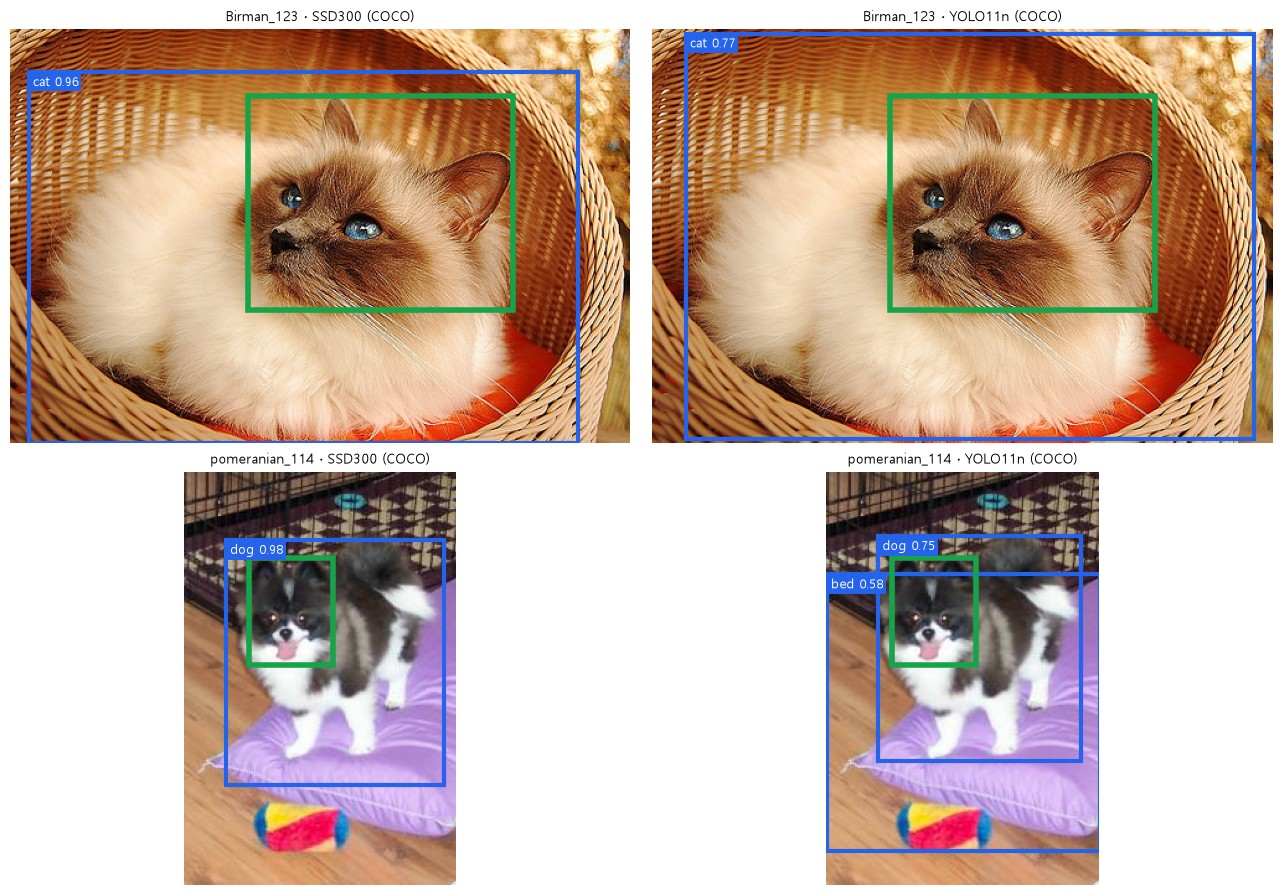

In [57]:
from ultralytics import YOLO          # YOLO 라이브러리
from ultralytics.utils import events  # 사용 통계 설정


# ---------- 8-1 ----------

# 왜 · 실습 실행 정보가 외부로 전송되지 않게 하고 YOLO 구조를 열어 보기 위해
events.events.enabled = False  # 사용 통계 전송 끄기 (이 실행에서만)
yolo = YOLO(WEIGHTS / "yolo11n.pt")  # COCO로 학습된 YOLO11n (원본은 YOLO26n)
print("YOLO 격자 간격(픽셀):", [int(s_) for s_ in yolo.model.stride])           # 8 · 16 · 32
print("640×640 입력의 격자 :", [640 // int(s_) for s_ in yolo.model.stride])    # 80 · 40 · 20
print("YOLO 클래스 수:", len(yolo.names), "· SSD 클래스 수:", len(categories))  # 80 vs 91


# ---------- 8-2 ----------
# 왜 · 같은 사진에 SSD와 YOLO를 돌려 결과를 나란히 비교하기 위해
def both_models(stem):  # 같은 사진 · 같은 기준으로 두 모델
    path = IMAGES / f"{stem}.jpg"                                        # 사진 경로
    with torch.no_grad():                                                # 예측만
        s_out = ssd([SSD_W.transforms()(decode_image(str(path)))])[0]    # SSD
    keep = s_out["scores"] > 0.5                                         # 같은 기준: 점수 0.5 초과
    kept = {k: v[keep].tolist() for k, v in s_out.items()}               # 0.5 초과 줄만 목록으로
    ssd_out = [(categories[lb], v, bx) for bx, lb, v in                  # (이름, 점수, 박스)
               zip(kept["boxes"], kept["labels"], kept["scores"])]
    r = yolo.predict(str(path), conf=0.5, device="cpu", verbose=False)[0]  # YOLO
    yolo_out = [(r.names[int(c)], v, bx) for bx, c, v in zip(            # 같은 모양으로
        r.boxes.xyxy.tolist(), r.boxes.cls.tolist(), r.boxes.conf.tolist())]
    gt_box, _, _ = read_gt(stem)                                         # 머리 정답
    print(f"[{stem}] 정답(머리):", [int(v) for v in gt_box])             # 정답
    for name, outs in (("SSD ", ssd_out), ("YOLO", yolo_out)):           # 두 모델
        for lab, v, bx in outs:                                          # 예측마다
            print(f"  {name} {lab:5s} {v:.2f}  {[int(q) for q in bx]}")  # 한 줄
    return path, gt_box, ssd_out, yolo_out                               # 그림 · 비교용


# 왜 · 두 모델에서 같은 클래스의 첫 박스를 꺼내 비교하기 위해
def first_box(outs, name):                                     # 그 이름의 첫 예측
    return [(v, bx) for lab, v, bx in outs if lab == name][0]  # (점수, 박스)


# 왜 · 고양이 · 개 사진에서 두 모델의 점수와 박스를 비교하기 위해
results = [(both_models("Birman_123"), "cat"), (both_models("pomeranian_114"), "dog")]  # 두 사진
fig, axes = plt.subplots(2, 2, figsize=(13, 9))                               # 사진 2장 × 모델 2개
for row, ((path, gt_box, ssd_out, yolo_out), name) in zip(axes, results):     # 사진마다
    models = (("SSD300 (COCO)", ssd_out), ("YOLO11n (COCO)", yolo_out))       # 두 모델
    for ax, (mname, outs) in zip(row, models):                                # 모델마다
        draw(Image.open(path), gt=[gt_box], pred=[bx for _, _, bx in outs], ax=ax,  # 정답 · 예측
             labels=[f"{lab} {v:.2f}" for lab, v, _ in outs], title=f"{path.stem} · {mname}")
    (sv, sb), (yv, yb) = first_box(ssd_out, name), first_box(yolo_out, name)  # 같은 클래스 박스
    s_box, y_box, head_t = torch.tensor([sb]), torch.tensor([yb]), torch.tensor([gt_box])  # 텐서로
    print(f"[{path.stem}] {name} 점수: SSD {sv:.2f} · YOLO {yv:.2f} · 두 모델 박스끼리 IoU"  # 비교
          f" {box_iou(s_box, y_box).item():.2f} · 머리 정답과 IoU: SSD"
          f" {box_iou(s_box, head_t).item():.2f} · YOLO {box_iou(y_box, head_t).item():.2f}")
plt.tight_layout()                                                            # 여백 정리
plt.show()                                                                    # 그림 출력

**실행 흐름**

1. 번호 바꾸기 · predict · match
2. 겹친 예측 두 개 예제

In [58]:
# ---------- 9. 종합 실습 ----------
# 왜 · COCO 번호와 우리 번호가 달라 바꿔 줘야 채점할 수 있기 때문에
COCO_TO_OURS = {COCO.index("cat"): 1, COCO.index("dog"): 2}  # 나머지 COCO 클래스는 버림
# 17 · 18
print("COCO cat, dog 번호:", list(COCO_TO_OURS), "→ 우리 번호", list(COCO_TO_OURS.values()))


# 왜 · 채점할 예측을 같은 기준으로 모으기 위해
def predict(stem, score_min=0.5):  # COCO SSD 예측 중 점수 ≥ score_min인 cat · dog만
    with torch.no_grad():          # 예측만
        o = ssd([TF.to_tensor(load_image(stem))])[0]  # 학습 전 COCO 모델
    # 남길 줄
    keep = [i for i, (lb, s_) in enumerate(zip(o["labels"].tolist(), o["scores"].tolist()))
            if s_ >= score_min and lb in COCO_TO_OURS]
    return (o["boxes"][keep],      # 박스
            # 우리 번호
            torch.tensor([COCO_TO_OURS[o["labels"][i].item()] for i in keep], dtype=torch.int64),
            o["scores"][keep])     # 점수


# 왜 · 예측과 정답을 IoU로 짝지어 TP · FP · FN을 판정하기 위해
def match(p_boxes, p_labels, g_boxes, g_labels, iou_min=0.5):       # 점수 순 짝짓기
    iou = (box_iou(p_boxes, g_boxes) if len(p_boxes) and len(g_boxes)  # 예측 × 정답
           else torch.zeros(len(p_boxes), len(g_boxes)))
    used, verdicts = set(), []                                      # 짝 생긴 정답 · 판정
    for i in range(len(p_boxes)):                                   # predict() 결과는 이미 점수 순
        cand = [(iou[i, j].item(), j) for j in range(len(g_boxes))  # 같은 클래스 · 짝 없는 정답
                if j not in used and g_labels[j] == p_labels[i]]
        best, j = max(cand, default=(0.0, None))                    # 가장 많이 겹친 정답
        shown = iou[i].max().item() if len(g_boxes) else 0.0        # 클래스 상관없이 최대 IoU
        if j is not None and best >= iou_min:                       # 기준 이상
            used.add(j)                                             # 그 정답은 다시 못 씀
            verdicts.append(("TP", best))                           # 맞음
        else:                                                       # 아니면
            verdicts.append(("FP", shown))                          # 틀림
    return verdicts, len(g_boxes) - len(used)                       # (예측별 판정, FN 개수)


# 왜 · 같은 정답에 겹친 예측 두 개가 어떻게 판정되는지 작은 예로 확인하기 위해
gt_toy = torch.tensor([[100., 100., 200., 200.]])                   # 정답 머리 박스 1개 (장난감 예)
# 예측 2개 · 거의 같은 자리
two_preds = torch.tensor([[102., 98., 205., 200.], [95., 105., 198., 210.]])
print("IoU:", [round(v, 2) for v in box_iou(two_preds, gt_toy)[:, 0].tolist()])  # 둘 다 많이 겹침
verdicts, fn = match(two_preds, torch.tensor([1, 1]), gt_toy, [1])  # 짝짓기
print([v for v, _ in verdicts], "· FN", fn)                         # 하나만 TP

COCO cat, dog 번호: [17, 18] → 우리 번호 [1, 2]
IoU: [0.92, 0.81]
['TP', 'FP'] · FN 0


**실행 흐름**

1. 사진 8장 판정
2. 정밀도 · 재현율 · F1

In [59]:
# ---------- 9. 종합 실습 ----------
# 왜 · 원본과 같은 사진 8장으로 판정 결과를 모으기 위해
photos = ["Abyssinian_10", "Bengal_101", "american_bulldog_121",  # 원본의 사진 8장
          "newfoundland_104",
          "basset_hound_102", "British_Shorthair_116", "Sphynx_114", "keeshond_104"]
TP, FP, FN = 0, 0, 0                                              # 합계
for stem in photos:                                               # 사진마다
    g_boxes, g_names = read_voc(XMLS / f"{stem}.xml")             # 머리 정답
    g_labels = [NAME_TO_LABEL[n] for n in g_names]                # 우리 번호
    p_boxes, p_labels, p_scores = predict(stem)                   # 점수 0.5 이상 cat · dog
    # 판정
    verdicts, fn = match(p_boxes, p_labels, torch.tensor(g_boxes, dtype=torch.float32), g_labels)
    preds = [f"예측 {['', 'cat', 'dog'][lb]} {s_:.2f} → {v} (IoU {iou_v:.2f})"  # 예측마다 한 조각
             for lb, s_, (v, iou_v) in zip(p_labels.tolist(), p_scores.tolist(), verdicts)]
    # 한 줄
    print(f"{stem:22s} 정답 {g_names[0]} 머리 | " + (" / ".join(preds) or "cat·dog 예측 없음")
          + f" | FN {fn}")
    TP += sum(v == "TP" for v, _ in verdicts)                     # 맞힌 수
    FP += sum(v == "FP" for v, _ in verdicts)                     # 틀린 수
    FN += fn                                                      # 놓친 수

# 왜 · 모은 판정으로 정밀도 · 재현율 · F1을 계산하기 위해
print(f"TP {TP} · FP {FP} · FN {FN}")                           # 합계
precision = TP / (TP + FP)                                      # 모델이 낸 박스 중 맞힌 비율
recall = TP / (TP + FN)                                         # 정답 박스 중 찾아낸 비율
f1 = 2 * precision * recall / (precision + recall)              # 조화 평균
print(f"정밀도(precision) = {TP}/{TP + FP} = {precision:.2f}")  # 정밀도
print(f"재현율(recall)    = {TP}/{TP + FN} = {recall:.2f}")     # 재현율
print(f"F1               = {f1:.2f}")                           # F1

Abyssinian_10          정답 cat 머리 | 예측 cat 0.84 → FP (IoU 0.37) | FN 1


Bengal_101             정답 cat 머리 | 예측 cat 0.99 → FP (IoU 0.17) | FN 1


american_bulldog_121   정답 dog 머리 | 예측 dog 0.99 → FP (IoU 0.27) | FN 1


newfoundland_104       정답 dog 머리 | 예측 dog 0.99 → FP (IoU 0.25) | FN 1


basset_hound_102       정답 dog 머리 | 예측 dog 0.97 → TP (IoU 0.95) | FN 0


British_Shorthair_116  정답 cat 머리 | 예측 cat 0.98 → TP (IoU 0.61) | FN 0


Sphynx_114             정답 cat 머리 | 예측 dog 0.81 → FP (IoU 0.61) | FN 1


keeshond_104           정답 dog 머리 | cat·dog 예측 없음 | FN 1
TP 2 · FP 5 · FN 6
정밀도(precision) = 2/7 = 0.29
재현율(recall)    = 2/8 = 0.25
F1               = 0.27
